# Nevis RIA Market Analysis

**Prepared by Isabella Vermaes for the Nevis data analysis hometask**

This notebook turns five years of SEC Form ADV filings into a clean firm-level table, then answers Nevis's questions about the RIA market.

## Executive summary

**Bottom line:** Nevis should start discovery with 10 firms from a shortlist of 402 (Track A - later explained). At these firms, accounts are growing faster than advisors, which suggests rising workload and value-add for Nevis.

### How the market narrows

| Step | Firms | What it means |
|---|---:|---|
| All SEC-registered RIAs | 17,263 | Every firm in the latest SEC file |
| Nevis target screen | 6,579 | US wealth managers, with at least 50% of AUM from individuals, offering both financial planning and portfolio management. Platform-style firms are left out |
| Track A: pilot candidates | 402 | Targets with \$1B-\$10B of AUM and at least 5 advisors, where accounts rose and outpaced advisors over both the latest cycle and 3 years. Growth that looks like a one-off, a transfer or an acquisition is left out |
| First wave | 10 | The highest-scoring Track A firms, to start discovery with |

Track B is a separate list of 308 US wealth managers that are over \$10B or platform-style. They need a longer enterprise sale.

### Market segments

| Segment | Firms | Share of firms | Share of usable AUM |
|---|---:|---:|---:|
| Under \$1B | 11,873 | 68.8% | 2.1% |
| \$1B-\$10B | 4,020 | 23.3% | 7.0% |
| \$10B-\$50B | 937 | 5.4% | 11.7% |
| Over \$50B | 433 | 2.5% | 79.3% |

Assumptions:
- Under \$1B: the largest group, but a median of 3 advisors means few seats and probably smaller budgets.
- \$1B-\$10B: enough advisors to feel workload pressure, with a median of one extra office, so a pilot can stay contained.
- Over \$10B: a jump in complexity, with multiple offices and affiliates, so these firms went into Track B as a longer enterprise sale.


### Leaders by segment

These are Nevis targets. Q1 and Q5 cover 3 years (further years in Step 16 and 18), and Q2 is the latest year. Each section also shows all RIAs and the other windows.

| Question | Under \$1B | \$1B-\$10B | \$10B-\$50B | Over \$50B |
|---|---|---|---|---|
| **Q1: AUM growth a year** | Encompass More, 105.6% | Savvy, 252.0% | &Partners, 257.3% | Focus Partners Wealth, 113.0% |
| **Q2: AUM per advisor** | Aufman Associates, \$323.8M | Prowell Financial, \$2.3B | Baker Street, \$1.4B | GW&K, \$837.8M |
| **Q5: AUM growth minus advisor growth** | Encompass More, 67.1 pts | A16Z Perennial, 184.5 pts | &Partners, 124.9 pts | Cetera, 49.4 pts |

- **Q1:** market growth is broad, at about 13% to 15% a year in every segment. Three of the four three-year segment leaders show possible acquisition-led growth: Savvy, &Partners and Focus Partners Wealth. Encompass More has no jump flagged. Focus is already a named Nevis customer.
- **Q2:** high AUM per advisor often reflects a few large clients, so read it with clients per advisor.
- **Q5:** the workload measure changes the result. On the same 4,155 US wealth managers, AUM outgrew advisors at 90.3%, accounts at 63.9% and clients at 56.8%.
- **Q5 across all windows:** 3,975 screened RIAs across all segments, with at least three advisors at both endpoints, have a positive gap in three overlapping windows.
- **A16Z Perennial:** its account gap is withheld by the 100 starting-account minimum (26 → 147).

### What this means for Nevis

- **Prove one workflow first:** Step 23 gives each first-wave firm a reason and a workflow to test. Part D proposes a first deployment using DayMark.
- **Check operating models:** Advisory Alpha describes a platform for advisor partners, and Axxcess calls itself an enterprise TAMP. The top two prospects aren't straightforward advisor-led pilots.
- **Check fit by firm size:** Nevis's deployment post describes firms with hundreds or thousands of advisors, but its Wedmont case study covers a firm with 12 advisors and \$3.4B of AUM. The median Track A firm has 15 advisors, and 38 firms have at least 100.
- **Use accounts alongside AUM:** AUM can rise without added work, so accounts are a closer sign of workload.
- **Check for group structures:** the fastest growers may have added firms, so one buyer may cover several of them.

### How far to trust this

- **Data kept:** 407 of 95,494 firm-years (0.43%) have received an `exclude` status and stay in the table for audit. In the latest file, 89 of 17,263 firms (0.52%) have that status, and 758 (4.39%) are left out of the analysis, mostly because they report \$0 AUM.
- **Manual review:** cleaning needed none. The first 10 Track A firms are in scope, which is 2.5% of Track A. Identity has been checked for seven, and buying authority is open for all ten.
- **Limits:** the screen shows fit, not demand. The filings can't show a firm's current tools, budget or buyer.

## Contents

| Part | Contents |
|---|---|
| **Method in brief** | How each figure was decided |
| **A. Data preparation** | Steps 1-13: load, clean, classify and validate the data |
| **B. Business questions** | Steps 14-18: market segments, Q1, Q2 and Q5 (Q3) |
| **C. Additional analysis** | Steps 19-25: non-advisory staff, geography, firms joining and leaving, complexity, prospect tracks, business form, sensitivity checks |
| **D. Conclusions** | What the results mean for Nevis |
| **E. Outputs** | Step 26: saved tables |
| **Appendix** | Full methodology, assumptions, limitations, how AI was used and a pricing sensitivity |

The code has to clean the data before it can answer, so the summary above comes first and the answers follow Part A.

**To run it:** put exactly one file per year in `nevis_ria/data` in Google Drive, with names starting `Nov-21`, `Nov-22`, `Nov-23`, `Nov-24`, `Dec-25` and `Nov-26`. Then choose **Runtime → Run all**. No manual steps are needed.

## Method in brief

Each reported figure answers three questions, in this order:

1. **Can the row be trusted?** Every firm-year is checked automatically against 20 written rules.
2. **Can this figure be used for this question?** A firm with no reported advisors (e.g. due to affiliates) can still have reliable AUM, so it stays in AUM analysis and leaves advisor analysis.
3. **Was the firm measured properly over the whole period, and is the growth real?** A firm enters a growth ranking only if it was usable in every year of that window. Transfers between related firms are removed or labelled.

Two principles apply throughout:

- **Rows are flagged, not deleted.** All 95,494 firm-years stay in the final table, and the market table reconciles to all 17,263 firms in the latest source file.
- **Nothing depends on manual review.** Every decision is a written rule, so running the notebook gives the same result each time. The only hand-gathered facts are the sourced group checks in Step 23.

The Appendix sets out the full methodology.

# Part A: Data preparation

The steps below turn six raw SEC files into one clean table, with one row per firm per year.

## Step 1: Setup

Connects to Google Drive and sets every choice in one place, so nothing is hidden further down the notebook.

**Why November snapshots?** Firms update their AUM once a year, usually by the end of March. Each November file therefore mostly holds the previous year-end figures, and all snapshots line up with the latest file. The SEC's October and November 2025 files contain no data, so December 2025 is used instead.

`data_year` is the year-end the figures mostly relate to, so the November 2026 file is 2025.

In [ ]:
import difflib
import hashlib
import io
import re
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# Use Google Drive in Colab, or a local "data" folder anywhere else
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/nevis_ria")
except ImportError:
    PROJECT_DIR = Path(".")

RAW_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# One row per snapshot. "*" lets the rest of the file name be anything
SNAPSHOTS = [
    {"file_pattern": "Nov-21*", "data_year": 2020, "snapshot_date": "2021-11-01"},
    {"file_pattern": "Nov-22*", "data_year": 2021, "snapshot_date": "2022-11-07"},
    {"file_pattern": "Nov-23*", "data_year": 2022, "snapshot_date": "2023-11-01"},
    {"file_pattern": "Nov-24*", "data_year": 2023, "snapshot_date": "2024-11-01"},
    {"file_pattern": "Dec-25*", "data_year": 2024, "snapshot_date": "2025-12-01"},
    {"file_pattern": "Nov-26*", "data_year": 2025, "snapshot_date": "2026-11-02"},
]

# Cleaning assumptions, all in one place
STALE_AFTER_MONTHS = 15        # a filing older than this is out of date
WEALTH_MANAGER_THRESHOLD = 0.50  # share of AUM from individuals and HNW clients
LARGE_AUM_JUMP = 5             # flag AUM or advisor moves above 5x in one year
AUM_SPIKE = 3                  # flag one year 3x away from both neighbouring years
MAX_AUM_PER_ADVISOR = 1_000_000_000_000  # above this is treated as an error
MIN_PLAUSIBLE_AUM = 1_000      # positive AUM below this looks like a units error

# Growth windows (Step 11)
GROWTH_WINDOWS = [1, 3, 5]             # years


def window_name(years):
    """Name a growth window. The files in the 1-year window are 11 months apart."""
    return "Latest cycle" if years == 1 else f"{years} years"


MIN_START_AUM = 100_000_000            # avoids huge percentages from tiny bases
MIN_START_ADVISORS = 3                 # avoids 1-to-2 advisors counting as 100% growth
JUMP_LABEL = 3                 # label AUM rises above 3x in one year
SUPPORTING_RISE = 1.5          # clients, accounts or staff rising 1.5x supports a jump
FUND_EXPLAINS_SHARE = 0.80     # fund assets explaining this share of a rise support a jump
MATERIAL_DOLLAR_MOVE = 100_000_000  # a material move also needs this dollar change
RELATED_LOSS_SHARE = 0.30      # a related firm's loss must be this share of the rise
RELATED_MIN_GAIN = 500_000_000  # the rise must be at least this large
SCALE_MULTIPLE, SCALE_MIN_GAIN = 3, 1_000_000_000  # signs of acquisition-led growth
PLATFORM_LOAD_PER_ADVISOR = 1_000  # clients or accounts per advisor for a platform-style firm
FEWER_THAN_5_MINIMUM, FEWER_THAN_5_MAXIMUM = 1, 4  # range when no count is given
MIN_START_ACCOUNTS = 100       # avoids unstable account growth from tiny bases
MIN_PILOT_ADVISORS = 5         # Track A firms need a real advisory team
MAX_RECENT_ACCOUNT_GROWTH = 1.0  # a doubling of accounts is treated as a possible one-off
ADVISOR_DECLINE_SHARE = 0.5      # advisors falling to this share in a year marks a large decline

# Text some firms enter instead of a business name
PLACEHOLDER_NAMES = {"NO OTHER PRIMARY BUSINESS NAME", "NONE", "N/A", "NA"}

print(f"Reading raw files from: {RAW_DIR}")

Mounted at /content/drive
Reading raw files from: /content/drive/MyDrive/nevis_ria/data


## Step 2: Choose the columns

The SEC file has 448 columns, but the analysis needs about 70. Each one has a clear role:

- **Required:** the analysis can't run without these, so a missing column stops the notebook.
- **Supporting:** these fill the requested table or test whether a row can be trusted.
- **Client columns (Item 5.D):** the number of clients and AUM for each of the 14 client types.

Raw names follow the Form ADV item numbers. For example, `5F(2)(c)` is Item 5.F.(2)(c), total AUM.

In [ ]:
# Raw SEC column name -> clean name used in this notebook
REQUIRED_COLUMNS = {
    "SEC#": "sec_number",
    "Organization CRD#": "crd",
    "Primary Business Name": "firm_name",
    "Latest ADV Filing Date": "filing_date",
    "5F(2)(c)": "aum_usd",
    "5B(1)": "advisors",
}

SUPPORTING_COLUMNS = {
    "Legal Name": "legal_name",
    "Website Address": "website_raw",
    "Total Number of Website Addresses": "website_count",
    "Main Office City": "city",
    "Main Office State": "state",
    "Main Office Country": "country",
    "SEC Current Status": "sec_status",
    "Form Version": "form_version",
    "5A": "employees",
    "5F(1)": "manages_portfolios",
    "5F(2)(a)": "aum_discretionary",
    "5F(2)(b)": "aum_non_discretionary",
    "5F(2)(f)": "accounts",
    "5F(2)(d)": "accounts_discretionary",
    "5F(2)(e)": "accounts_non_discretionary",
    "5G(1)": "offers_financial_planning",
    "5G(2)": "manages_individual_portfolios",
    "Firm Type": "firm_type",
    "3A": "business_form",
    "4A": "succession_flag",
    "4B": "succession_date",
    "7A(2)": "has_adviser_affiliate",
    "Umbrella Registration": "umbrella",
    "Total number of offices, other than your Principal Office and place of business": "offices",
    "Count of IA Affiliates": "ia_affiliates",
}

# Item 5.D: (1) number of clients, (2) "fewer than 5" box, (3) AUM.
# Types d, e and f have no "fewer than 5" box on the form.
CLIENT_TYPES = list("abcdefghijklmn")
TYPES_WITH_FEWER_THAN_5_BOX = [t for t in CLIENT_TYPES if t not in "def"]

CLIENT_COUNT_COLUMNS = [f"5D({t})(1)" for t in CLIENT_TYPES]
FEWER_THAN_5_COLUMNS = [f"5D({t})(2)" for t in TYPES_WITH_FEWER_THAN_5_BOX]
CLIENT_AUM_COLUMNS = [f"5D({t})(3)" for t in CLIENT_TYPES]

ALL_COLUMNS = {**REQUIRED_COLUMNS, **SUPPORTING_COLUMNS}
for column in CLIENT_COUNT_COLUMNS + FEWER_THAN_5_COLUMNS + CLIENT_AUM_COLUMNS:
    ALL_COLUMNS[column] = column  # client columns keep their form names

# Note: the Nov 2021 and Nov 2022 files have only 262 columns, not 448.
# Columns they lack, such as "Count of IA Affiliates" and "4A", load as blanks.
# Those columns are only compared between years where both years have them.

# If an older file names a column differently, add it here:
# {"name in the old file": "name used in the 2026 file"}
COLUMN_ALIASES = {}

print(f"Columns kept: {len(ALL_COLUMNS)} of 448")

Columns kept: 70 of 448


## Step 3: Load each file as text

Everything is read as **text** first. If pandas guessed the types, a value like `More than 100` in a number column could become blank without warning. Keeping it as text lets the next step check it first.

The loader handles ZIP, CSV and Excel files because the SEC's format changes between years. It also:

- trims hidden spaces, which matter because some cells contain only a space
- treats the text `NA` as text, because `keep_default_na=False` stops it being read as blank
- stops with a clear message if a required column is missing
- stops if a file contains anything other than registered advisers, an unknown status or a duplicated firm
- records each file's size and SHA-256 hash, and each row's position in its source file, so any figure can be traced back

In [ ]:
def read_table(content, file_name):
    """Turn raw file bytes into a table where every value is text."""
    if file_name.lower().endswith(".csv"):
        return pd.read_csv(io.BytesIO(content), encoding="latin-1", dtype=str,
                           keep_default_na=False, low_memory=False)
    return pd.read_excel(io.BytesIO(content), dtype=str, keep_default_na=False)


def read_raw_file(path):
    """Read a CSV or Excel file, or the largest data file inside a ZIP."""
    if path.suffix.lower() != ".zip":
        return read_table(path.read_bytes(), path.name)

    with zipfile.ZipFile(path) as archive:
        data_files = [
            item for item in archive.infolist()
            if item.filename.lower().endswith((".csv", ".xlsx", ".xls"))
            and "__MACOSX" not in item.filename
        ]
        if not data_files:
            raise ValueError(f"No CSV or Excel file found inside {path.name}")
        largest = max(data_files, key=lambda item: item.file_size)
        return read_table(archive.read(largest), largest.filename)


def standardise_columns(raw, file_name):
    """Keep the needed columns, rename them and tidy the text."""
    # Remove extra spaces from headers so small differences don't break matching
    raw.columns = [" ".join(str(name).split()) for name in raw.columns]
    raw = raw.rename(columns=COLUMN_ALIASES)

    missing_required = [c for c in REQUIRED_COLUMNS if c not in raw.columns]
    if missing_required:
        suggestions = {
            c: difflib.get_close_matches(c, raw.columns, n=3)
            for c in missing_required
        }
        raise KeyError(
            f"{file_name} is missing required columns. Closest matches: "
            f"{suggestions}. Add the right name to COLUMN_ALIASES in Step 2."
        )

    missing_supporting = [c for c in ALL_COLUMNS if c not in raw.columns]
    if missing_supporting:
        print(f"  Warning: {len(missing_supporting)} supporting columns are "
              f"missing and will be blank: {missing_supporting[:8]}")
        for column in missing_supporting:
            raw[column] = pd.NA

    clean = raw[list(ALL_COLUMNS)].rename(columns=ALL_COLUMNS).copy()
    for column in clean.columns:
        clean[column] = clean[column].astype("string").str.strip()
        clean[column] = clean[column].replace("", pd.NA)
    return clean


def validate_source(table, file_name):
    """Stop if a file contains something unexpected."""
    firm_types = set(table["firm_type"].dropna())
    if firm_types - {"Registered"}:
        raise ValueError(f"{file_name} has unexpected firm types: {firm_types}")
    statuses = set(table["sec_status"].dropna())
    if statuses - {"Approved", "120-Day Approval"}:
        raise ValueError(f"{file_name} has unexpected statuses: {statuses}")
    if table["crd"].isna().any() or table["crd"].duplicated().any():
        raise ValueError(f"{file_name} has blank or duplicated CRD numbers")
    if table["sec_number"].dropna().duplicated().any():
        raise ValueError(f"{file_name} has duplicated SEC numbers")


def load_all_snapshots(snapshots):
    """Load every available snapshot into one table of text."""
    tables, manifest = [], []
    for snapshot in snapshots:
        matches = sorted(RAW_DIR.glob(snapshot["file_pattern"]))
        if not matches:
            print(f"Missing: {snapshot['file_pattern']} "
                  f"(data year {snapshot['data_year']})")
            continue
        if len(matches) > 1:
            raise ValueError(f"More than one file matches: {matches}")

        path = matches[0]
        raw_table = read_raw_file(path)
        manifest.append({
            "file": path.name, "data_year": snapshot["data_year"], "rows": len(raw_table),
            "columns": raw_table.shape[1],
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
        table = standardise_columns(raw_table, path.name)
        validate_source(table, path.name)
        table["source_row"] = np.arange(2, len(table) + 2)  # row 1 is the header
        table["data_year"] = snapshot["data_year"]
        table["snapshot_date"] = pd.Timestamp(snapshot["snapshot_date"])
        table["source_file"] = path.name
        tables.append(table)
        print(f"Loaded {path.name}: {len(table):,} firms "
              f"(data year {snapshot['data_year']})")

    if not tables:
        raise FileNotFoundError(f"No matching files found in {RAW_DIR}")
    return pd.concat(tables, ignore_index=True), pd.DataFrame(manifest)


raw_text, source_manifest = load_all_snapshots(SNAPSHOTS)
display(source_manifest)

Loaded Nov-21_SEC Registered Investment Adviser Report.csv: 14,777 firms (data year 2020)
Loaded Nov-22_SEC Registered Investment Adviser Report.xlsx: 15,423 firms (data year 2021)
Loaded Nov-23_SEC Registered Investment Adviser Report.xlsx: 15,573 firms (data year 2022)
Loaded Nov-24_SEC Registered Investment Adviser Report.xlsx: 15,974 firms (data year 2023)
Loaded Dec-25_SEC Registered Investment Adviser Report.CSV: 16,484 firms (data year 2024)
Loaded Nov-26_SEC Registered Investment Adviser Report.CSV: 17,263 firms (data year 2025)


,file,data_year,rows,columns,sha256
0,Nov-21_SEC Registered Investment Adviser Report.csv,2020,14777,262,3220677054ac6750846b625f655ec32d6a6bb41ceb704b255abb55a5...
1,Nov-22_SEC Registered Investment Adviser Report.xlsx,2021,15423,262,0ce1650dd0b9cd4b6fc49b43e91bef2f6127140342288184afaebf9b...
2,Nov-23_SEC Registered Investment Adviser Report.xlsx,2022,15573,448,7dcd5a23967b36b2725a5a8bf60fcefef95f23bead0a414ba528ce06...
3,Nov-24_SEC Registered Investment Adviser Report.xlsx,2023,15974,448,ba53c346853e4c9cf42cc6445e4cb76905a804b382140c1e1aecd773...
4,Dec-25_SEC Registered Investment Adviser Report.CSV,2024,16484,448,e6ef6be107d2803dca639dff37ae81ee9f0572b6fef084cf84fefae3...
5,Nov-26_SEC Registered Investment Adviser Report.CSV,2025,17263,448,b6223149f8cd95f09e00cff7e82a6b8cbb8f4f39b4811677408f4101...


## Step 4: Check formats before converting anything

Each column has an expected format, such as `Y`/`N` or a number. This step counts the filled values that break the rule. Blanks are ignored here, because they get their own checks in Step 8.

The patterns accept both styles found in SEC files: `630,665,806.00` from CSV files and `630665806` from Excel files.

Any failure here should be understood before moving on. The table shows one row per column and year.

In [ ]:
# What a valid value looks like for each type of column
PATTERNS = {
    "yes_no": r"[YN]",
    "whole_number": r"\d[\d,]*(\.0+)?",
    "money": r"\d[\d,]*(\.\d+)?|\.\d+",
    "date": r"\d{1,2}/\d{1,2}/\d{4}|\d{4}-\d{2}-\d{2}( 00:00:00)?",
    "sec_number": r"801-\d+",
    "state": r"[A-Z]{2}",
    "status": r"Approved|120-Day Approval",
}

# Which pattern each column must follow
COLUMN_RULES = {
    "sec_number": "sec_number",
    "crd": "whole_number",
    "filing_date": "date",
    "sec_status": "status",
    "state": "state",
    "aum_usd": "money",
    "aum_discretionary": "money",
    "aum_non_discretionary": "money",
    "advisors": "whole_number",
    "employees": "whole_number",
    "accounts": "whole_number",
    "accounts_discretionary": "whole_number",
    "accounts_non_discretionary": "whole_number",
    "manages_portfolios": "yes_no",
    "has_adviser_affiliate": "yes_no",
    "offers_financial_planning": "yes_no",
    "manages_individual_portfolios": "yes_no",
}
COLUMN_RULES.update({column: "whole_number" for column in CLIENT_COUNT_COLUMNS})
COLUMN_RULES.update({column: "money" for column in CLIENT_AUM_COLUMNS})


def check_formats(df, rules):
    """List the columns, per year, where filled values break their rule."""
    failures = []
    for year, table in df.groupby("data_year"):
        for column, rule in rules.items():
            values = table[column].dropna()
            invalid = values[~values.str.fullmatch(PATTERNS[rule])]
            if len(invalid) > 0:
                failures.append({
                    "data_year": year,
                    "column": column,
                    "rule": rule,
                    "invalid_count": len(invalid),
                    "examples": invalid.unique()[:5].tolist(),
                })
    return pd.DataFrame(failures)


format_failures = check_formats(raw_text, COLUMN_RULES)
if format_failures.empty:
    print("All filled values match their format rules.")
else:
    print(f"{len(format_failures)} format problems found:")
    display(format_failures)

All filled values match their format rules.


## Step 5: Convert text to numbers and dates

Commas are removed and text becomes numbers or dates. A value that can't be converted would normally become blank without warning, so this step records it in `conversion_failures` and flags the row.

In [ ]:
NUMBER_COLUMNS = (
    ["crd", "aum_usd", "aum_discretionary", "aum_non_discretionary", "advisors",
     "employees", "accounts", "accounts_discretionary", "accounts_non_discretionary",
     "website_count", "offices", "ia_affiliates"]
    + CLIENT_COUNT_COLUMNS
    + CLIENT_AUM_COLUMNS
)


def convert_types(text_table):
    """Convert number and date columns, and report anything that fails."""
    df = text_table.copy()
    df["has_invalid_number"] = False
    failures = []

    for column in NUMBER_COLUMNS:
        original = df[column]
        converted = pd.to_numeric(
            original.str.replace(",", "", regex=False), errors="coerce"
        )
        failed = original.notna() & converted.isna()
        df.loc[failed, "has_invalid_number"] = True
        if failed.any():
            failed_rows = df.loc[failed, ["data_year", "sec_number", "firm_name"]].copy()
            failed_rows["column"] = column
            failed_rows["original_value"] = original[failed]
            failures.append(failed_rows)
        df[column] = converted.astype("Float64")

    df["crd"] = df["crd"].astype("Int64")

    original_dates = df["filing_date"]
    df["filing_date"] = pd.to_datetime(original_dates, format="mixed", errors="coerce")
    df["succession_date"] = pd.to_datetime(df["succession_date"], format="mixed", errors="coerce")
    bad_dates = original_dates.notna() & df["filing_date"].isna()
    df.loc[bad_dates, "has_invalid_number"] = True

    failure_table = pd.concat(failures) if failures else pd.DataFrame()
    return df, failure_table, int(bad_dates.sum())


converted, conversion_failures, bad_date_count = convert_types(raw_text)

print(f"Values that could not be converted: {len(conversion_failures):,}")
print(f"Dates that could not be converted: {bad_date_count:,}")
if not conversion_failures.empty:
    display(conversion_failures.head(20))

Values that could not be converted: 0
Dates that could not be converted: 0


## Step 6: Remove duplicates and build the client count

**Firm names:** a few firms enter a placeholder as their business name, so their legal name is used instead.

**Duplicates:** the table needs one row per firm per year, so if a firm appears twice in a file, the latest filing is kept. The CRD number is used because 117 rows in the 2026 file share a firm name with another row.

**Number of clients** isn't one column. It's the sum of the 14 client types in Item 5.D.

- A blank client type means the firm has none, so it counts as 0. Across all six files, every client type with AUM but no count has the "fewer than 5" box ticked, which supports this.
- If "fewer than 5 clients" is ticked and the count is blank or 0, the true number is between 1 and 4. `clients_min` and `clients_max` keep that range.
- `clients` uses the minimum, so the table has one usable figure and counts are never overstated. `client_count_basis` shows whether a total is fully `reported`, calculated with `blanks_as_zero`, a `range` or `unknown`, and AUM per client has matching low and high values. The range of 1 to 4 is this notebook's convention for the "fewer than 5" box.
- If a firm has AUM but the total is still 0, the count is unknown and stays blank.

**Client AUM check:** client-type AUM should equal total AUM. Each firm is recorded as `passed`, `failed` or `not_testable`, because a check that can't run isn't the same as one that failed.

**Wealth manager flag:** this field is added because Nevis sells to wealth managers, while raw AUM also includes institutional asset managers such as Vanguard. A firm is flagged when at least 50% of its AUM comes from individuals and high-net-worth clients, which are client types (a) and (b).

In [ ]:
def remove_duplicates(df):
    """Keep one row per firm per year, using the latest filing."""
    before = len(df)
    df = df.sort_values(["crd", "data_year", "filing_date"])
    df = df.drop_duplicates(["crd", "data_year"], keep="last")
    print(f"Duplicate rows removed: {before - len(df):,}")
    return df.reset_index(drop=True)


def fix_placeholder_names(df):
    """Use the legal name where the business name is only a placeholder."""
    df = df.copy()
    placeholder = df["firm_name"].str.upper().isin(PLACEHOLDER_NAMES).fillna(False)
    df.loc[placeholder, "firm_name"] = df.loc[placeholder, "legal_name"]
    print(f"Placeholder firm names replaced: {placeholder.sum():,}")
    return df


def calculate_clients(df):
    """Add up clients and AUM across the Item 5.D client types."""
    df = df.copy()
    counts = df[CLIENT_COUNT_COLUMNS].fillna(0)
    minimum, maximum = counts.copy(), counts.copy()

    # "Fewer than 5" ticked with no usable count: keep the range of 1 to 4
    df["client_minimum_applied"] = False
    for client_type in TYPES_WITH_FEWER_THAN_5_BOX:
        count_column = f"5D({client_type})(1)"
        box_ticked = df[f"5D({client_type})(2)"].notna()
        no_count = counts[count_column] == 0
        in_range = box_ticked & no_count
        minimum.loc[in_range, count_column] = FEWER_THAN_5_MINIMUM
        maximum.loc[in_range, count_column] = FEWER_THAN_5_MAXIMUM
        df.loc[in_range, "client_minimum_applied"] = True

    df["clients_min"] = minimum.sum(axis=1)
    df["clients_max"] = maximum.sum(axis=1)
    df["clients"] = df["clients_min"]

    # A firm with AUM must have clients, so a total of 0 means "unknown"
    unknown = (df["clients"] == 0) & (df["aum_usd"] > 0)
    df.loc[unknown, ["clients", "clients_min", "clients_max"]] = pd.NA
    is_unknown = df["clients"].isna().to_numpy(dtype=bool)
    is_range = (df["clients_min"] != df["clients_max"]).fillna(False).to_numpy(dtype=bool)
    has_blanks = df[CLIENT_COUNT_COLUMNS].isna().any(axis=1).to_numpy(dtype=bool)
    df["client_count_basis"] = np.select(
        [is_unknown, is_range, has_blanks], ["unknown", "range", "blanks_as_zero"], default="reported",
    )

    # Reconcile client-type AUM with total AUM, separating "failed" from "can't test"
    client_aum = df[CLIENT_AUM_COLUMNS]
    df["client_type_aum_total"] = client_aum.fillna(0).sum(axis=1)
    no_client_aum = client_aum.isna().all(axis=1)
    gap = (df["client_type_aum_total"] - df["aum_usd"]).abs()
    has_gap = (gap > 1).fillna(False).to_numpy(dtype=bool)
    df["client_aum_check"] = np.select([no_client_aum.to_numpy(dtype=bool), has_gap],
                                       ["not_testable", "failed"], default="passed")
    df["fund_aum"] = df[[f"5D({t})(3)" for t in "def"]].fillna(0).sum(axis=1)
    return df


def add_wealth_manager_flag(df):
    """Flag firms that earn most of their AUM from private clients."""
    df = df.copy()
    individual_aum = df[["5D(a)(3)", "5D(b)(3)"]].fillna(0).sum(axis=1)
    has_aum = df["aum_usd"] > 0
    df["individual_aum_share"] = (individual_aum / df["aum_usd"]).where(has_aum)
    df["is_wealth_manager"] = (
        df["individual_aum_share"] >= WEALTH_MANAGER_THRESHOLD
    ).fillna(False).astype(bool)
    return df


firms = remove_duplicates(converted)
firms = fix_placeholder_names(firms)
firms = calculate_clients(firms)
firms = add_wealth_manager_flag(firms)

print("Client count basis:", firms["client_count_basis"].value_counts().to_dict())
print("Client AUM check:", firms["client_aum_check"].value_counts().to_dict())

Duplicate rows removed: 0
Placeholder firm names replaced: 9
Client count basis: {'blanks_as_zero': 53144, 'range': 22475, 'reported': 19853, 'unknown': 22}
Client AUM check: {'passed': 93023, 'not_testable': 2471}


## Step 7: Clean the websites

The SEC file shows only one website per firm, and it's often a social media page. Beacon Pointe, the example in the brief, shows a Pinterest link.

For each firm, this step:

1. removes `http://` and `https://`, and puts the address in lower case
2. marks social media links
3. if a firm only has a social link this year, borrows its most recent real website from another year

`website_status` records which case applied: `ok`, `from_other_year`, `social_only` or `missing`.

In [ ]:
SOCIAL_DOMAINS = (
    "facebook.com", "linkedin.com", "twitter.com", "x.com", "instagram.com",
    "youtube.com", "pinterest.com", "tiktok.com", "yelp.com", "vimeo.com",
    "fb.com", "youtu.be", "amazon.com", "apple.com", "spotify.com", "soundcloud.com",
)


def standardise_website(url):
    """Return a tidy web address, e.g. www.beaconpointe.com."""
    if pd.isna(url):
        return pd.NA
    text = str(url).strip().lower()
    text = text.split()[0] if text else text  # drop any note after the address
    text = text.split("://")[-1]             # remove http:// or https://
    text = text.split("?")[0].split("#")[0]  # remove tracking text
    return text.rstrip("/")


def is_social_link(url):
    """Check whether a tidy web address belongs to a social media site."""
    if pd.isna(url):
        return False
    host = url.split("/")[0]
    return any(host == domain or host.endswith("." + domain)
               for domain in SOCIAL_DOMAINS)


def clean_websites(df):
    """Create a usable website column and record where it came from."""
    df = df.copy()
    tidy = df["website_raw"].map(standardise_website)
    social = tidy.map(is_social_link).astype(bool)

    df["website"] = tidy.where(~social)
    df["website_status"] = np.where(social, "social_only", "ok")
    df.loc[tidy.isna(), "website_status"] = "missing"

    # Latest real website for each firm across all years
    real_sites = df.loc[df["website"].notna(), ["crd", "data_year", "website"]]
    latest_site = real_sites.sort_values("data_year").groupby("crd")["website"].last()

    needs_site = df["website"].isna()
    borrowed = df.loc[needs_site, "crd"].map(latest_site)
    df.loc[needs_site, "website"] = borrowed
    df.loc[borrowed.dropna().index, "website_status"] = "from_other_year"
    return df


firms = clean_websites(firms)
display(firms.groupby("data_year")["website_status"].value_counts().unstack(fill_value=0))

website_status,from_other_year,missing,ok,social_only
data_year,,,,
2020,1621,1148,10425,1583
2021,2236,1143,10419,1625
2022,2714,1112,10105,1642
2023,3123,1090,10010,1751
2024,3387,1134,10041,1922
2025,3475,1288,10306,2194


## Step 8: Classify every row

Every row is classified automatically by the rule book below. **For the purpose of this assignment, there is no manual review step.**

Instead of asking "is this row good?", each rule asks "**which figure does this problem affect?**" A firm with zero reported advisors can still have a perfectly usable AUM figure, so it stays in the AUM analysis and only drops out of the advisor analysis.

| Status | Meaning | Market count | AUM growth (Q1) | Advisor analysis (Q2, Q5) |
|---|---|---|---|---|
| `ok` | Passes every rule | Yes | Yes | Yes |
| `valid_gap` | A blank or zero explained by another answer on the form | Yes | If AUM is above 0 | If AUM and advisors are above 0 |
| `limited` | One figure can't be used, but the others can | Yes | If AUM is usable | No, if advisors are the problem |
| `exclude` | The AUM can't be trusted, or the filing is out of date | Shown separately | No | No |

A row can break several rules. All of them appear in `row_issues`, and the most serious one sets `row_status`.

**Definitions**

- **Unexplained gap:** a blank or zero in a field that should have a value, where no other answer on the form accounts for it.
- **Stale filing:** a last filing more than 15 months before the snapshot. SEC rules require an update within 90 days of year-end, so the longest on-time gap is about 12 + 3 months.
- **Plausibility rule:** catches values that pass every format check but can't be real, such as \$11.5T with one advisor.

In [ ]:
RULE_BOOK = pd.DataFrame(
    [
        # EXCLUDE: the AUM can't be trusted, or the row is out of date
        ("exclude", "missing_required_field", "All figures",
         "SEC number, CRD number, firm name, filing date, AUM or advisor count is blank.",
         "The firm can't be identified or measured."),
        ("exclude", "stale_filing", "All figures",
         f"Last filing is more than {STALE_AFTER_MONTHS} months before the snapshot.",
         "SEC rules require an annual update, so the figures are out of date."),
        ("exclude", "invalid_number", "All figures",
         "A number column holds a value that isn't a number.",
         "The true value is unknown."),
        ("exclude", "aum_parts_do_not_add_up", "AUM",
         "Discretionary + non-discretionary AUM differs from total AUM by more than $1.",
         "Two answers on the form disagree."),
        ("exclude", "client_aum_does_not_match_total", "AUM",
         "AUM by client type differs from total AUM by more than $1.",
         "The form says these should be equal."),
        ("exclude", "aum_and_accounts_disagree", "AUM",
         "The firm has AUM but no accounts, or accounts but no AUM.",
         "Two answers on the form disagree."),
        ("exclude", "aum_but_says_no_portfolios", "AUM",
         "The firm has AUM but answered no to managing portfolios at 5F(1).",
         "Two answers on the form disagree."),
        ("exclude", "implausible_aum_per_advisor", "AUM",
         f"AUM per advisor is at least ${MAX_AUM_PER_ADVISOR / 1e12:,.0f}T.",
         "No individual could oversee this much, so the AUM is almost certainly a typing error."),
        ("exclude", "implausibly_small_aum", "AUM",
         f"AUM is above $0 but below ${MIN_PLAUSIBLE_AUM:,}.",
         "This looks like a units error, such as entering 12 instead of the full figure."),

        # LIMITED: one figure can't be used, but the rest of the row can
        ("limited", "zero_aum_unexplained", "AUM",
         "AUM is 0, the firm says it manages portfolios, and it isn't newly registered.",
         "Nothing on the form explains the zero, so the firm can't be ranked."),
        ("limited", "advisors_exceed_employees", "Advisors",
         "Advisors at 5B(1) are higher than total employees at 5A.",
         "Advisors are a subset of employees, so the count can't be right."),
        ("limited", "employees_but_no_advisors", "Advisors",
         "The firm has AUM and employees, but reports zero advisors.",
         "AUM may be fine, but advisor ratios can't be calculated."),
        ("limited", "no_staff_reported", "Advisors",
         "The firm has AUM, but reports zero employees and zero advisors.",
         "Its people may sit in a related company. AUM is usable, but advisor ratios aren't."),
        ("limited", "clients_unknown", "Clients",
         "The firm has AUM, but no client count even after the 1-client minimum.",
         "A firm with AUM must have clients, so the count is unknown."),
        ("limited", "client_aum_not_testable", "Clients and client mix",
         "The firm has AUM, but every client-type AUM field is blank.",
         "The check can't be run, which is different from failing it."),
        ("limited", "account_parts_do_not_add_up", "Accounts",
         "Discretionary + non-discretionary accounts differ from total accounts.",
         "Two answers on the form disagree."),
        ("limited", "clients_at_least_equal_aum", "Clients",
         "The number of clients is at least as high as AUM in dollars.",
         "This looks like a value entered in the wrong field."),

        # VALID GAP: a blank or zero that another answer explains
        ("valid_gap", "zero_aum_no_portfolios", "None",
         "AUM is 0 and the firm answered no to managing portfolios at 5F(1).",
         "The zero is the expected answer."),
        ("valid_gap", "zero_aum_new_registration", "None",
         "AUM is 0, the firm says it manages portfolios, and its status is 120-Day Approval.",
         "A newly registered firm may not have started managing assets."),
        ("valid_gap", "client_minimum_applied", "None",
         "Fewer than 5 clients is ticked but the count is blank or 0, so that type counts as 1.",
         "The form explains the gap, and 1 is the lowest possible value."),
    ],
    columns=["status", "rule", "affects", "definition", "why_it_matters"],
)

display(RULE_BOOK)

,status,rule,affects,definition,why_it_matters
0,exclude,missing_required_field,All figures,"SEC number, CRD number, firm name, filing date, AUM or a...",The firm can't be identified or measured.
1,exclude,stale_filing,All figures,Last filing is more than 15 months before the snapshot.,"SEC rules require an annual update, so the figures are o..."
2,exclude,invalid_number,All figures,A number column holds a value that isn't a number.,The true value is unknown.
3,exclude,aum_parts_do_not_add_up,AUM,Discretionary + non-discretionary AUM differs from total...,Two answers on the form disagree.
4,exclude,client_aum_does_not_match_total,AUM,AUM by client type differs from total AUM by more than $1.,The form says these should be equal.
5,exclude,aum_and_accounts_disagree,AUM,"The firm has AUM but no accounts, or accounts but no AUM.",Two answers on the form disagree.
6,exclude,aum_but_says_no_portfolios,AUM,The firm has AUM but answered no to managing portfolios ...,Two answers on the form disagree.
7,exclude,implausible_aum_per_advisor,AUM,AUM per advisor is at least $1T.,"No individual could oversee this much, so the AUM is alm..."
8,exclude,implausibly_small_aum,AUM,"AUM is above $0 but below $1,000.","This looks like a units error, such as entering 12 inste..."
9,limited,zero_aum_unexplained,AUM,"AUM is 0, the firm says it manages portfolios, and it is...","Nothing on the form explains the zero, so the firm can't..."


**Changes over time** are flagged but don't change a row's status, because they may be real:

| Flag | Meaning | Treatment |
|---|---|---|
| `large_aum_jump`, `large_advisor_swing` | A move above 5x in one year, which may be a reporting or organisational change | Labelled. Advisor swings leave the Q5 ranking |
| `aum_spike` | One year more than 3x above or below **both** neighbouring years | Blocks that year as a growth start point |
| `large_advisor_decline` | Advisors fell at least 50% in one year, such as Vanguard Group going from 330 to 19 | That year's AUM per advisor isn't ranked in Q2 |
| `repeat_filing` | The same filing date as the previous snapshot, so there's no new data | Blocks the firm if it's the latest year |
| `aum_unchanged` | The same AUM to the dollar, with a new filing | Flag only, as flat AUM can be real |
| `material_aum_move` | AUM doubled or halved **and** moved at least \$100M | Used to find transfers |
| `jump_type` | AUM rose over 3x and at least \$100M in a year. `supported` if clients, accounts, advisors or employees rose at least 1.5x, or fund assets explain at least 80% of the rise. Otherwise `unconfirmed` | Shown beside each ranking |
| `structure_change` | A dated succession, or a changed SEC number or umbrella status, compared only where both years have the data | Flag only |

**Why jumps aren't removed:** a large jump usually isn't an error, as most persist into the following year. Removing them would delete real growth, so they're labelled instead. Transfers between related firms are handled separately in Step 9.

A spike can't be detected in the latest year, because there's no following year to show it reversing. The jump label is the safeguard there.

In [ ]:
def add_basic_flags(df):
    """Add the simple yes/no flags used by the row rules."""
    df = df.copy()
    df["is_us_firm"] = df["state"].notna()
    df["is_new_registration"] = df["sec_status"].eq("120-Day Approval").fillna(False)

    stale_cutoff = df["snapshot_date"] - pd.DateOffset(months=STALE_AFTER_MONTHS)
    df["is_stale_filing"] = (df["filing_date"] < stale_cutoff).fillna(False)
    return df


def find_rows_for_each_rule(df):
    """Return the rows that break each rule in the rule book."""
    has_aum = df["aum_usd"] > 0
    zero_aum = df["aum_usd"] == 0
    says_manages = df["manages_portfolios"].eq("Y").fillna(False)
    says_not_managing = df["manages_portfolios"].eq("N").fillna(False)
    new_firm = df["is_new_registration"]
    no_advisors = df["advisors"] == 0
    no_employees = df["employees"] == 0

    aum_parts = df["aum_discretionary"] + df["aum_non_discretionary"]
    account_parts = df["accounts_discretionary"] + df["accounts_non_discretionary"]
    required_columns = list(REQUIRED_COLUMNS.values())
    aum_per_advisor = df["aum_usd"] / df["advisors"].where(df["advisors"] > 0)

    return {
        "missing_required_field": df[required_columns].isna().any(axis=1),
        "stale_filing": df["is_stale_filing"],
        "invalid_number": df["has_invalid_number"],
        "aum_parts_do_not_add_up": (aum_parts - df["aum_usd"]).abs() > 1,
        "client_aum_does_not_match_total": has_aum & df["client_aum_check"].eq("failed"),
        "aum_and_accounts_disagree": has_aum != (df["accounts"] > 0),
        "aum_but_says_no_portfolios": has_aum & says_not_managing,
        "implausible_aum_per_advisor": aum_per_advisor >= MAX_AUM_PER_ADVISOR,
        "implausibly_small_aum": has_aum & (df["aum_usd"] < MIN_PLAUSIBLE_AUM),
        "zero_aum_unexplained": zero_aum & says_manages & ~new_firm,
        "advisors_exceed_employees": df["advisors"] > df["employees"],
        "employees_but_no_advisors": has_aum & no_advisors & (df["employees"] > 0),
        "no_staff_reported": has_aum & no_advisors & no_employees,
        "clients_unknown": has_aum & df["clients"].isna(),
        "client_aum_not_testable": has_aum & df["client_aum_check"].eq("not_testable"),
        "account_parts_do_not_add_up": (account_parts - df["accounts"]).abs() > 0,
        "clients_at_least_equal_aum": has_aum & (df["clients"] >= df["aum_usd"]),
        "zero_aum_no_portfolios": zero_aum & says_not_managing,
        "zero_aum_new_registration": zero_aum & says_manages & new_firm,
        "client_minimum_applied": df["client_minimum_applied"],
    }


def assign_row_status(df):
    """Apply the rule book. The most serious status sets row_status."""
    df = df.copy()
    rule_rows = find_rows_for_each_rule(df)

    # Stop if the code and the rule book ever drift apart
    if set(rule_rows) != set(RULE_BOOK["rule"]):
        raise ValueError("The rule book and the code do not match.")

    df["row_status"] = "ok"
    df["row_issues"] = ""

    # Least serious first, so the most serious status is written last
    for status in ["valid_gap", "limited", "exclude"]:
        for rule in RULE_BOOK.loc[RULE_BOOK["status"] == status, "rule"]:
            rows = rule_rows[rule].fillna(False).astype(bool)
            df.loc[rows, "row_status"] = status
            df.loc[rows, "row_issues"] += rule + "; "

    df["row_issues"] = df["row_issues"].str.rstrip("; ")

    # Record which figures remain unusable for this row
    unusable_clients = (rule_rows["clients_unknown"]
                        | rule_rows["client_aum_not_testable"]
                        | rule_rows["clients_at_least_equal_aum"]).fillna(False)
    unusable_accounts = rule_rows["account_parts_do_not_add_up"].fillna(False).astype(bool)
    unusable_advisors = (rule_rows["advisors_exceed_employees"]
                         | rule_rows["employees_but_no_advisors"]
                         | rule_rows["no_staff_reported"]).fillna(False)
    df["clients_usable"] = ~unusable_clients.astype(bool)
    df["advisors_usable"] = ~unusable_advisors.astype(bool) & (df["advisors"] > 0).fillna(False)
    df["accounts_usable"] = ~unusable_accounts & (df["accounts"] > 0).fillna(False)
    return df


def flag_changes_over_time(df):
    """Flag firms whose AUM or advisor count moves sharply between years."""
    df = df.sort_values(["crd", "data_year"]).copy()
    by_firm = df.groupby("crd")

    # Only compare consecutive years, in case a firm is missing from a file
    gap_to_previous = df["data_year"] - by_firm["data_year"].shift(1)
    gap_to_next = by_firm["data_year"].shift(-1) - df["data_year"]

    aum = df["aum_usd"].where(df["aum_usd"] > 0)
    previous_aum = by_firm["aum_usd"].shift(1).where(lambda s: s > 0)
    next_aum = by_firm["aum_usd"].shift(-1).where(lambda s: s > 0)
    change = (aum / previous_aum).where(gap_to_previous == 1)

    df["large_aum_jump"] = (
        (change > LARGE_AUM_JUMP) | (change < 1 / LARGE_AUM_JUMP)
    ).fillna(False).astype(bool)

    # A spike is one year far above or below both neighbours
    versus_previous = aum / previous_aum
    versus_next = aum / next_aum
    both_sides = (gap_to_previous == 1) & (gap_to_next == 1)
    df["aum_spike"] = (
        ((versus_previous > AUM_SPIKE) & (versus_next > AUM_SPIKE))
        | ((versus_previous < 1 / AUM_SPIKE) & (versus_next < 1 / AUM_SPIKE))
    ).where(both_sides, False).fillna(False).astype(bool)

    # The same filing date means no new data. The same AUM with a new filing is only a flag.
    previous_filing = by_firm["filing_date"].shift(1)
    df["repeat_filing"] = ((df["filing_date"] == previous_filing)
                           & (gap_to_previous == 1)).fillna(False).astype(bool)
    df["aum_unchanged"] = ((aum == previous_aum)
                           & (gap_to_previous == 1)).fillna(False).astype(bool)

    # A material move needs both a large multiple and a real dollar change
    dollar_change = (df["aum_usd"] - by_firm["aum_usd"].shift(1)).astype("Float64")
    df["material_aum_move"] = (
        ((change >= 2) | (change <= 0.5)) & (dollar_change.abs() >= MATERIAL_DOLLAR_MOVE)
    ).fillna(False).astype(bool)

    advisors = df["advisors"].where(df["advisors"] > 0)
    previous_advisors = by_firm["advisors"].shift(1).where(lambda s: s > 0)
    advisor_change = (advisors / previous_advisors).where(gap_to_previous == 1)
    df["large_advisor_swing"] = (
        (advisor_change > LARGE_AUM_JUMP) | (advisor_change < 1 / LARGE_AUM_JUMP)
    ).fillna(False).astype(bool)

    # A fall of at least half in one year often means the count itself changed
    df["large_advisor_decline"] = (advisor_change <= ADVISOR_DECLINE_SHARE).fillna(False).astype(bool)

    # Is there evidence of change beyond the AUM figure?
    def rose(column):
        previous = by_firm[column].shift(1).where(lambda s: s > 0)
        return (df[column] / previous >= SUPPORTING_RISE).fillna(False).astype(bool)

    fund_change = (df["fund_aum"] - by_firm["fund_aum"].shift(1)).astype("Float64")
    funds_explain = (fund_change / dollar_change.where(dollar_change != 0)
                     >= FUND_EXPLAINS_SHARE).fillna(False).astype(bool)
    supported = (rose("clients") | rose("advisors") | rose("employees")
                 | rose("accounts") | funds_explain)

    is_jump = ((change > JUMP_LABEL)
               & (dollar_change >= MATERIAL_DOLLAR_MOVE)).fillna(False).astype(bool)
    df["jump_type"] = np.select([is_jump & supported, is_jump], ["supported", "unconfirmed"],
                                default="none")

    # Signals that the reporting entity may have changed
    def changed(column):
        previous = by_firm[column].shift(1)
        both_known = df[column].notna() & previous.notna() & (gap_to_previous == 1)
        return (both_known & (df[column] != previous)).fillna(False).astype(bool)

    previous_snapshot = by_firm["snapshot_date"].shift(1)
    dated_succession = (df["succession_flag"].eq("Y")
                        & (df["succession_date"] > previous_snapshot)
                        & (df["succession_date"] <= df["snapshot_date"])).fillna(False).astype(bool)
    df["structure_change"] = dated_succession | changed("sec_number") | changed("umbrella")
    return df.reset_index(drop=True)


def set_usage_flags(df):
    """Turn each row's status into simple yes/no usage columns."""
    df = df.copy()
    has_aum = (df["aum_usd"] > 0).fillna(False).astype(bool)

    df["in_market_count"] = df["row_status"] != "exclude"
    df["use_in_rankings"] = df["in_market_count"] & has_aum
    df["use_in_advisor_rankings"] = df["use_in_rankings"] & df["advisors_usable"]
    return df


def count_rows_per_rule(df):
    """Show how many rows each rule catches in each year."""
    issues = df[["data_year", "row_issues"]].copy()
    issues["rule"] = issues["row_issues"].str.split("; ")
    issues = issues.explode("rule", ignore_index=True)
    counts = pd.crosstab(issues["rule"], issues["data_year"])
    counts = counts.drop(index="", errors="ignore")
    return (RULE_BOOK[["status", "rule", "affects"]]
            .merge(counts, left_on="rule", right_index=True, how="left")
            .fillna(0))


firms = add_basic_flags(firms)
firms = assign_row_status(firms)
firms = set_usage_flags(firms)
firms = flag_changes_over_time(firms)

status_order = ["ok", "valid_gap", "limited", "exclude"]
print("Rows by status:")
display(pd.crosstab(firms["data_year"], firms["row_status"])
        .reindex(columns=status_order, fill_value=0))
print("Rows caught by each rule (a row can break several):")
display(count_rows_per_rule(firms))

Rows by status:


row_status,ok,valid_gap,limited,exclude
data_year,,,,
2020,10168,4286,272,51
2021,10924,4165,254,80
2022,11177,4070,253,73
2023,11561,4160,213,40
2024,12078,4119,213,74
2025,12764,4180,230,89


Rows caught by each rule (a row can break several):


,status,rule,affects,2020,2021,2022,2023,2024,2025
0,exclude,missing_required_field,All figures,2.00,1.00,1.00,1.00,1.00,1.00
1,exclude,stale_filing,All figures,44.00,73.00,63.00,35.00,64.00,74.00
2,exclude,invalid_number,All figures,0.00,0.00,0.00,0.00,0.00,0.00
3,exclude,aum_parts_do_not_add_up,AUM,0.00,0.00,0.00,0.00,0.00,0.00
4,exclude,client_aum_does_not_match_total,AUM,0.00,0.00,0.00,0.00,0.00,0.00
5,exclude,aum_and_accounts_disagree,AUM,0.00,0.00,0.00,0.00,0.00,0.00
6,exclude,aum_but_says_no_portfolios,AUM,0.00,0.00,0.00,0.00,0.00,0.00
7,exclude,implausible_aum_per_advisor,AUM,0.00,0.00,1.00,0.00,0.00,0.00
8,exclude,implausibly_small_aum,AUM,6.00,7.00,9.00,5.00,10.00,16.00
9,limited,zero_aum_unexplained,AUM,165.00,147.00,149.00,126.00,137.00,143.00


## Step 9: Detect transfers between related firms

A jump in AUM isn't growth if the assets simply moved between two legal entities. PineBridge is the clearest case: the name moved from one CRD to another, and one rose from \$1.17B to \$76.73B as the other fell from \$73.24B to \$2.67B.

There are three tests, because the evidence differs in strength:

| Test | What it looks for | Treatment |
|---|---|---|
| **Name move** | A firm's exact name appears on a different CRD a year later, with AUM moving by an offsetting amount (between 0.5x and 2x) | **Removed** from growth rankings for windows containing the move |
| **Possible related transfer** | A firm's AUM rises by at least \$500M while a firm with the same distinctive first brand word or website leaves or halves, with a loss worth at least 30% of the rise | **Labelled**, as a shared name doesn't prove a transfer |
| **Possible acquisition-led growth** | Over the window, AUM **and** advisors both rise at least 3x, with at least \$1B of new AUM | **Labelled** in Step 16 |

The third test exists because consolidation often can't be seen by matching names. Cetera Investment Advisers grew from \$28.3B to \$256.8B and from 2,462 to 9,049 advisors, while sister firms left the file a year or more before the assets arrived. No firm-level test can prove this from the SEC file alone, so these firms are labelled rather than removed.

In [ ]:
GENERIC_NAME_WORDS = set(
    "LLC INC LP LLP LTD LIMITED CO COMPANY CORP CORPORATION GROUP PARTNERS ADVISORS ADVISERS "
    "ADVISORY ADVISOR WEALTH MANAGEMENT CAPITAL INVESTMENT INVESTMENTS INVESTORS FINANCIAL "
    "ASSET ASSETS THE AND OF SERVICES SECURITIES US USA UK PRIVATE GLOBAL TRUST FUND FUNDS "
    "PLANNING SOLUTIONS STRATEGIES CREDIT FIRST NEW NATIONAL AMERICAN UNITED".split()
)
MAX_BRAND_FIRMS = 5  # a word used by more firms than this isn't a distinctive brand


def name_key(text):
    """Reduce a name to letters and digits, so small differences don't matter."""
    return re.sub(r"[^A-Z0-9]", "", str(text).upper())


def names_by_key(table, placeholders):
    """Map each normalised name to the CRD numbers that use it."""
    keys = {}
    for crd, name, legal in table[["crd", "firm_name", "legal_name"]].itertuples(index=False):
        for key in {name_key(name), name_key(legal)} - placeholders - {"", "NAN"}:
            keys.setdefault(key, set()).add(crd)
    return keys


def find_name_moves(df):
    """Find names that moved between CRDs, with offsetting AUM."""
    years = sorted(df["data_year"].unique())
    placeholders = {name_key(name) for name in PLACEHOLDER_NAMES}
    moves = []

    for older, newer in zip(years, years[1:]):
        base_rows, latest_rows = df[df["data_year"] == older], df[df["data_year"] == newer]
        base, latest = base_rows.set_index("crd"), latest_rows.set_index("crd")
        base_names = names_by_key(base_rows, placeholders)
        latest_names = names_by_key(latest_rows, placeholders)

        for key in sorted(base_names.keys() & latest_names.keys()):
            if len(base_names[key]) != 1 or len(latest_names[key]) != 1:
                continue
            donor, recipient = next(iter(base_names[key])), next(iter(latest_names[key]))
            if donor == recipient or recipient not in base.index:
                continue

            old_recipient = float(base.at[recipient, "aum_usd"])
            new_recipient = float(latest.at[recipient, "aum_usd"])
            donor_after = float(latest.at[donor, "aum_usd"]) if donor in latest.index else 0.0
            gain = new_recipient - old_recipient
            loss = float(base.at[donor, "aum_usd"]) - donor_after

            if (old_recipient > 0 and new_recipient >= 2 * old_recipient
                    and gain >= MATERIAL_DOLLAR_MOVE and loss > 0 and 0.5 <= gain / loss <= 2):
                moves.append({"data_year": newer, "donor_crd": donor, "recipient_crd": recipient,
                              "firm_name": latest.at[recipient, "firm_name"],
                              "recipient_gain_usd": gain, "donor_loss_usd": loss})
    return pd.DataFrame(moves, columns=["data_year", "donor_crd", "recipient_crd", "firm_name",
                                        "recipient_gain_usd", "donor_loss_usd"])


def website_host(address):
    """Return a firm's web host from a tidy address."""
    if pd.isna(address):
        return None
    return str(address).split("/")[0].removeprefix("www.") or None


def brand_word(name):
    """Return the first word in a name that isn't generic."""
    words = re.findall(r"[A-Z0-9]{3,}", str(name).upper())
    return next((word for word in words if word not in GENERIC_NAME_WORDS), None)


def find_possible_transfers(df, years_back):
    """Flag firms that grew while a firm with the same brand or website shrank."""
    end_year = int(df["data_year"].max())
    start_year = end_year - years_back
    start = df[df["data_year"] == start_year].set_index("crd")
    end = df[df["data_year"] == end_year].set_index("crd")

    latest_names = df.sort_values("data_year").groupby("crd")["firm_name"].last()
    brand_counts = latest_names.map(brand_word).value_counts().to_dict()

    # Firms that left, or at least halved, during the window
    end_aum = end["aum_usd"].reindex(start.index).fillna(0).astype(float)
    start_aum = start["aum_usd"].astype(float)
    shrank = start[(start_aum >= MATERIAL_DOLLAR_MOVE) & (end_aum <= 0.5 * start_aum)].copy()
    shrank["loss"] = start_aum[shrank.index] - end_aum[shrank.index]
    shrank["brand"] = shrank["firm_name"].map(brand_word)
    shrank["host"] = shrank["website"].map(website_host)

    flagged = {}
    for crd, row in end[end["aum_usd"] > 0].iterrows():
        before = float(start.at[crd, "aum_usd"]) if crd in start.index else 0.0
        gain = float(row["aum_usd"]) - before
        if gain < RELATED_MIN_GAIN or float(row["aum_usd"]) < 1.5 * before:
            continue
        brand, host = brand_word(row["firm_name"]), website_host(row["website"])
        same_brand = shrank["brand"].eq(brand) & (brand_counts.get(brand, 0) <= MAX_BRAND_FIRMS)
        same_host = shrank["host"].eq(host) & shrank["host"].notna()
        related = shrank[(same_brand | same_host) & (shrank.index != crd)]
        if len(related) and related["loss"].sum() >= RELATED_LOSS_SHARE * gain:
            flagged[crd] = "; ".join(related["firm_name"].astype(str).head(3))
    return flagged


name_moves = find_name_moves(firms)
possible_transfers = {years: find_possible_transfers(firms, years) for years in GROWTH_WINDOWS}

print(f"Name moves found: {len(name_moves)}")
display(name_moves.assign(
    recipient_gain_usd=name_moves["recipient_gain_usd"].map("${:,.0f}".format),
    donor_loss_usd=name_moves["donor_loss_usd"].map("${:,.0f}".format),
))
print("Possible related transfers by window:",
      {window_name(years): len(found) for years, found in possible_transfers.items()})

Name moves found: 3


,data_year,donor_crd,recipient_crd,firm_name,recipient_gain_usd,donor_loss_usd
0,2024,165931,299805,"BISON WEALTH, LLC","$1,596,104,546","$1,605,442,799"
1,2025,105926,285211,PINEBRIDGE INVESTMENTS LLC,"$75,555,012,409","$70,563,829,710"
2,2025,328970,170811,"PINEGROVE OPPORTUNITY PARTNERS, LLC","$2,113,335,321","$1,178,937,640"


Possible related transfers by window: {'Latest cycle': 26, '3 years': 149, '5 years': 268}


## Step 10: Calculate the ratios

A ratio stays blank when the denominator is 0. Otherwise pandas would create `inf`, and those firms would top every ranking.

`clients_per_advisor` isn't in the brief. It's added because it measures adviser capacity more directly than AUM per advisor.

In [ ]:
def safe_divide(numerator, denominator):
    """Divide two columns, leaving blanks where the denominator is not above 0."""
    return (numerator / denominator.where(denominator > 0)).astype("Float64")


def add_ratios(df):
    """Add the per-client and per-advisor measures."""
    df = df.copy()
    aum = df["aum_usd"].where(df["use_in_rankings"])
    clients = df["clients"].where(df["clients_usable"])
    advisors = df["advisors"].where(df["advisors_usable"])
    accounts = df["accounts"].where(df["accounts_usable"])
    df["aum_per_client"] = safe_divide(aum, clients)
    df["aum_per_client_low"] = safe_divide(aum, df["clients_max"].where(df["clients_usable"]))
    df["aum_per_client_high"] = safe_divide(aum, df["clients_min"].where(df["clients_usable"]))
    df["aum_per_advisor"] = safe_divide(aum, advisors)
    df["clients_per_advisor"] = safe_divide(clients, advisors)
    df["accounts_per_advisor"] = safe_divide(accounts, advisors)
    return df


firms = add_ratios(firms)
firms[["aum_per_client", "aum_per_advisor", "clients_per_advisor"]].describe()

,aum_per_client,aum_per_advisor,clients_per_advisor
count,"91,064.00","90,475.00","94,536.00"
mean,"241,690,252.95","270,814,591.61",217.88
std,"2,307,336,424.68","2,410,230,978.69","8,107.36"
min,1.62,38.46,0.00
25%,"964,469.87","49,163,718.01",1.12
50%,"3,408,575.10","92,647,669.12",24.38
75%,"90,629,796.20","188,781,032.95",70.31
max,"172,454,217,111.00","583,824,479,366.42","1,213,457.40"


## Step 11: Decide which firms can enter each growth window

A firm's 5-year growth is only meaningful if the firm was reported properly **throughout** those 5 years. Each window therefore has its own list of eligible firms, ending at the latest year.

A firm must pass **every** test below for a given window:

| Test | Why it matters |
|---|---|
| Usable in the latest year | The end point must be reliable |
| Reported in every year of the window | A missing year means the history is broken |
| Usable in every year of the window | A stale, faulty or \$0 AUM year in the middle undermines the trend |
| Start year isn't a new registration | First-year AUM can be partial, which inflates growth |
| No AUM spike in the start year | A one-year error would distort the whole window |
| No name move between firms | The AUM moved between entities rather than grew |
| Latest filing is new | With the same filing date as the start, there's no new data |
| Start AUM of at least \$100M | Tiny bases create huge percentages |

Q5 compares AUM with advisors, so it needs two more tests:

| Test | Why it matters |
|---|---|
| Advisor count usable in every year | Advisor growth needs a valid count throughout |
| At least 3 advisors at the start and end | Very small teams create extreme gaps, as one departure can look like a crisis |

The tables below show how many firms remain after each test, so a reviewer can see exactly what each one removes.

**Survivorship:** firms that left the data are excluded by design, because they have no end point. The table at the end shows how many left in each window, so the growth results aren't read as covering every firm.

In [ ]:
def firm_by_year(df, column):
    """Reshape a yes/no column into one row per firm and one column per year."""
    table = df.pivot(index="crd", columns="data_year", values=column)
    return table.astype("boolean").fillna(False).astype(bool)


def check_growth_window(df, years_back, min_start_aum=MIN_START_AUM, require_every_year=True):
    """Test every firm for one window and count who remains after each test."""
    end_year = int(df["data_year"].max())
    start_year = end_year - years_back
    window = list(range(start_year, end_year + 1))
    checked_years = window if require_every_year else [start_year, end_year]

    reported = firm_by_year(df.assign(reported=True), "reported")
    usable = firm_by_year(df, "use_in_rankings")
    usable_advisors = firm_by_year(df, "use_in_advisor_rankings")
    new_firm = firm_by_year(df, "is_new_registration")
    spike = firm_by_year(df, "aum_spike")
    aum = df.pivot(index="crd", columns="data_year", values="aum_usd")
    advisors = df.pivot(index="crd", columns="data_year", values="advisors")
    filing = df.pivot(index="crd", columns="data_year", values="filing_date")

    moves = name_moves[(name_moves["data_year"] > start_year) & (name_moves["data_year"] <= end_year)]
    moved = set(moves["donor_crd"]) | set(moves["recipient_crd"])

    aum_tests = {
        "Usable in the latest year": usable[end_year],
        "Reported in every year": reported[checked_years].all(axis=1),
        "Usable in every year": usable[checked_years].all(axis=1),
        "Start year isn't a new registration": ~new_firm[start_year],
        "No AUM spike in the start year": ~spike[start_year],
        "No name move between firms": ~usable.index.isin(moved),
        "Latest filing is new": filing[end_year] != filing[start_year],
        "Start AUM at the minimum": aum[start_year].fillna(0) >= min_start_aum,
    }
    advisor_tests = {
        "Advisor count usable in every year": usable_advisors[checked_years].all(axis=1),
        "At least 3 advisors at the start and end": (
            (advisors[start_year].fillna(0) >= MIN_START_ADVISORS)
            & (advisors[end_year].fillna(0) >= MIN_START_ADVISORS)
        ),
    }

    # Apply the tests in order, recording who remains and why others left
    remaining = pd.Series(True, index=usable.index)
    reason = pd.Series(pd.NA, index=usable.index, dtype="string")
    steps = []
    for test, passed in aum_tests.items():
        reason[remaining & ~passed] = test
        remaining = remaining & passed
        steps.append({"test": test, window_name(years_back): int(remaining.sum())})
    eligible_aum = remaining.copy()

    for test, passed in advisor_tests.items():
        remaining = remaining & passed
        steps.append({"test": test, window_name(years_back): int(remaining.sum())})
    eligible_advisors = remaining.copy()

    # Firms present at the start of the window but gone by the end
    left = reported[start_year] & ~reported[end_year]
    start_rows = df[(df["data_year"] == start_year) & df["crd"].isin(left[left].index)]
    exits = {
        "Window": window_name(years_back),
        "Firms at the start": int(reported[start_year].sum()),
        "Firms that left": len(start_rows),
        "Their usable AUM at the start": start_rows.loc[start_rows["use_in_rankings"], "aum_usd"].sum(),
        "Wealth managers that left": int(start_rows["is_wealth_manager"].sum()),
    }
    return eligible_aum, eligible_advisors, pd.DataFrame(steps).set_index("test"), exits, reason


def build_growth_eligibility(df):
    """Run every window and combine the results."""
    eligibility = pd.DataFrame(index=df["crd"].dropna().unique())
    funnels, exits = [], []

    for years_back in GROWTH_WINDOWS:
        if int(df["data_year"].max()) - years_back not in set(df["data_year"]):
            print(f"Skipping {window_name(years_back)}: start year not loaded.")
            continue
        aum_ok, advisors_ok, funnel, window_exits, reason = check_growth_window(df, years_back)
        eligibility[f"eligible_aum_{years_back}y"] = aum_ok
        eligibility[f"eligible_advisors_{years_back}y"] = advisors_ok
        eligibility[f"reason_{years_back}y"] = reason.astype(object)
        funnels.append(funnel)
        exits.append(window_exits)

    eligible_columns = [column for column in eligibility.columns if column.startswith("eligible")]
    eligibility[eligible_columns] = eligibility[eligible_columns].fillna(False).astype(bool)
    eligibility.index.name = "crd"
    return eligibility.reset_index(), pd.concat(funnels, axis=1), pd.DataFrame(exits)


growth_eligibility, growth_funnel, firms_that_left = build_growth_eligibility(firms)

print("Firms remaining after each test:")
display(growth_funnel)
print("Firms that left the data during each window:")
display(firms_that_left.style.format({"Their usable AUM at the start": "${:,.0f}"}))

Firms remaining after each test:


,Latest cycle,3 years,5 years
test,,,
Usable in the latest year,16505,16505,16505
Reported in every year,15267,12902,11065
Usable in every year,15038,12647,10841
Start year isn't a new registration,15006,12630,10822
No AUM spike in the start year,14990,12621,10822
No name move between firms,14987,12617,10818
Latest filing is new,14975,12617,10818
Start AUM at the minimum,14029,11746,10177
Advisor count usable in every year,13954,11655,10075


Firms that left the data during each window:


,Window,Firms at the start,Firms that left,Their usable AUM at the start,Wealth managers that left
0,Latest cycle,16484,805,"$1,496,602,696,112",407
1,3 years,15573,2344,"$4,899,956,676,812",1188
2,5 years,14777,3414,"$8,357,998,700,889",1685


## Step 12: Validate the final table

Each check prints PASS or FAIL so a reviewer can see the results at a glance. **Don't start the analysis until every check passes, or until you can explain each failure.**

In [ ]:
def run_checks(df, text_table, converted_table, eligibility, expected_years):
    """Run the final checks and return one PASS/FAIL row for each."""
    results = []

    def record(check, passed, detail):
        results.append({"result": "PASS" if passed else "FAIL",
                        "check": check, "detail": detail})

    # 1. All years are present
    years = sorted(int(year) for year in df["data_year"].unique())
    record("All six years loaded", len(years) == expected_years,
           f"{len(years)} of {expected_years}: {years}")

    # 2. Row counts are stable from year to year
    counts = df.groupby("data_year").size()
    biggest_change = counts.pct_change().abs().max()
    biggest_change = 0 if pd.isna(biggest_change) else biggest_change
    record("Firm count moves less than 15% a year", biggest_change < 0.15,
           f"Counts: {counts.to_dict()}")

    # 3. One row per firm per year
    duplicates = df.duplicated(["crd", "data_year"]).sum()
    record("One row per firm per year", duplicates == 0, f"{duplicates} duplicates")

    # 4. Nothing vanished when text was converted to numbers
    for column in ["aum_usd", "advisors", "employees"]:
        before = text_table[column].notna().sum()
        after = converted_table[column].notna().sum()
        record(f"No values lost in {column}", before == after,
               f"{before:,} filled before, {after:,} after")

    # 5. AUM columns add up, separating failures from checks that can't run
    checks = df.loc[df["aum_usd"] > 0, "client_aum_check"].value_counts()
    record("Client-type AUM reconciles for every testable firm", checks.get("failed", 0) == 0,
           f"{checks.get('passed', 0):,} passed, {checks.get('failed', 0):,} failed, "
           f"{checks.get('not_testable', 0):,} can't be tested")

    # 6. Values are logical
    negatives = (df[["aum_usd", "advisors", "employees", "clients"]] < 0).sum().sum()
    record("No negative values", negatives == 0, f"{negatives} found")
    too_many = (df.loc[df["use_in_rankings"], "advisors"]
                > df.loc[df["use_in_rankings"], "employees"]).sum()
    record("Advisors never exceed employees among ranked firms", too_many == 0, f"{too_many} found")

    # 7. No infinite ratios
    ratio_columns = ["aum_per_client", "aum_per_advisor", "clients_per_advisor"]
    infinite = np.isinf(df[ratio_columns].astype(float)).sum().sum()
    record("No infinite ratios", infinite == 0, f"{infinite} found")

    # 8. Filled SEC numbers have the expected form. Blanks are excluded in Step 8.
    filled_ids = df["sec_number"].dropna()
    bad_ids = (~filled_ids.str.fullmatch(r"801-\d+")).sum()
    record("Filled SEC numbers are in the form 801-XXXXX", bad_ids == 0,
           f"{bad_ids} invalid, {df['sec_number'].isna().sum()} blank")
    blank_in_use = df.loc[df["row_status"] != "exclude", "sec_number"].isna().sum()
    record("Rows with no SEC number are excluded", blank_in_use == 0,
           f"{blank_in_use} still in use")

    # 9. Every row has a known status
    unknown = (~df["row_status"].isin(status_order)).sum()
    record("Every row has a status", unknown == 0, f"{unknown} unknown")

    # 10. No flagged rows reach the rankings
    ranked = df["use_in_rankings"] | df["use_in_advisor_rankings"]
    leaks = (df.loc[ranked, "row_status"] == "exclude").sum()
    record("No excluded rows in rankings", leaks == 0, f"{leaks} found")

    # 11. Advisor rankings can't include firms with no advisors
    no_advisors = (df.loc[df["use_in_advisor_rankings"], "advisors"] <= 0).sum()
    record("Advisor rankings only include firms with advisors", no_advisors == 0,
           f"{no_advisors} found")

    # 12. Every firm is either in the market count or shown as excluded
    in_count = df["in_market_count"].sum()
    excluded = (df["row_status"] == "exclude").sum()
    record("Market count + excluded rows = all rows", in_count + excluded == len(df),
           f"{in_count:,} + {excluded:,} = {len(df):,}")

    # 13. Every eligible firm really has a usable row in every year of its window
    end_year = df["data_year"].max()
    usable_rows = df[df["use_in_rankings"]].groupby("crd")["data_year"].agg(set)
    for years_back in GROWTH_WINDOWS:
        column = f"eligible_aum_{years_back}y"
        if column in eligibility.columns:
            needed = set(range(end_year - years_back, end_year + 1))
            eligible = eligibility.loc[eligibility[column], "crd"]
            broken = sum(not needed <= usable_rows.get(crd, set()) for crd in eligible)
            record(f"All {years_back}-year firms are usable in every year", broken == 0,
                   f"{len(eligible):,} firms, {broken} with a gap")

    return pd.DataFrame(results)


check_results = run_checks(firms, raw_text, converted, growth_eligibility,
                           expected_years=len(SNAPSHOTS))
display(check_results)
print(f"{(check_results['result'] == 'PASS').sum()} of {len(check_results)} checks passed")

failed_checks = check_results[check_results["result"] == "FAIL"]
if len(failed_checks) > 0:
    raise RuntimeError(f"Stopping, because these checks failed: {failed_checks['check'].tolist()}")

,result,check,detail
0,PASS,All six years loaded,"6 of 6: [2020, 2021, 2022, 2023, 2024, 2025]"
1,PASS,Firm count moves less than 15% a year,"Counts: {2020: 14777, 2021: 15423, 2022: 15573, 2023: 15..."
2,PASS,One row per firm per year,0 duplicates
3,PASS,No values lost in aum_usd,"95,494 filled before, 95,494 after"
4,PASS,No values lost in advisors,"95,488 filled before, 95,488 after"
5,PASS,No values lost in employees,"95,488 filled before, 95,488 after"
6,PASS,Client-type AUM reconciles for every testable firm,"91,364 passed, 0 failed, 22 can't be tested"
7,PASS,No negative values,0 found
8,PASS,Advisors never exceed employees among ranked firms,0 found
9,PASS,No infinite ratios,0 found


19 of 19 checks passed


## Step 13: Compare key firms with the source

These automatic tests confirm that the clean table still matches the SEC file for four firms of different sizes, so the check repeats on every run with no manual step. The expected values come from each firm's row in the November 2026 SEC file. Three known problem cases are also tested, so a future change can't quietly let them back in.

In [ ]:
# Expected values: (AUM, advisors, employees) from the November 2026 SEC file
EXPECTED_FIRMS = {
    "801-60943": (54_872_534_714, 440, 780),      # Beacon Pointe
    "801-18564": (295_568_603_071, 1_538, 1_650), # Creative Planning
    "801-60749": (122_186_725_110, 850, 1_700),   # Wealth Enhancement
    "801-71117": (6_823_756_233, 114, 189),       # Focus Financial
}

latest = firms[firms["data_year"] == firms["data_year"].max()].set_index("sec_number")
for sec_number, (aum, advisors, employees) in EXPECTED_FIRMS.items():
    row = latest.loc[sec_number]
    assert float(row["aum_usd"]) == aum, f"AUM mismatch for {sec_number}"
    assert float(row["advisors"]) == advisors, f"Advisor mismatch for {sec_number}"
    assert float(row["employees"]) == employees, f"Employee mismatch for {sec_number}"

# Madoff still appears as "Approved" in the file, so it tests the stale-filing rule
assert latest.loc["801-67134", "row_status"] == "exclude", "A stale firm wasn't excluded"

# PineBridge's AUM moved between CRDs, so it must not be eligible for growth rankings
pinebridge = growth_eligibility.set_index("crd").loc[285211]
assert not pinebridge["eligible_aum_1y"], "A name move reached the growth rankings"

# Vista reported $11.5T with one advisor, so that row must not reach any ranking
vista = firms[(firms["crd"] == 316306) & (firms["data_year"] == 2022)].iloc[0]
assert not vista["use_in_rankings"], "An implausible AUM reached the rankings"
print("All source comparisons passed.")

columns = ["firm_name", "aum_usd", "clients", "employees", "advisors", "filing_date", "row_status"]
latest.loc[list(EXPECTED_FIRMS) + ["801-67134"], columns]

All source comparisons passed.


,firm_name,aum_usd,clients,employees,advisors,filing_date,row_status
sec_number,,,,,,,
801-60943,"BEACON POINTE ADVISORS, LLC","54,872,534,714.00","29,929.00",780.00,440.00,2026-08-31,ok
801-18564,CREATIVE PLANNING,"295,568,603,071.00","100,298.00","1,650.00","1,538.00",2026-07-10,ok
801-60749,"WEALTH ENHANCEMENT ADVISORY SERVICES, LLC","122,186,725,110.00","85,001.00","1,700.00",850.00,2026-10-29,ok
801-71117,FOCUS FINANCIAL,"6,823,756,233.00","13,684.00",189.00,114.00,2026-10-01,ok
801-67134,BERNARD L. MADOFF INVESTMENT SECURITIES LLC,"17,091,640,696.00",<NA>,<NA>,<NA>,2008-01-07,exclude


# Part B: Business questions

This part uses the clean table from Part A. Each question shows two views:

- **All RIAs:** the direct answer to the brief.
- **Nevis targets:** US wealth managers, excluding platform-style firms. This is the view closest to Nevis's customers.

Tables show the top 5 per segment. The top 25 for each are saved to the `outputs` folder.

## Step 14: Set up the analysis

This step creates a one-row-per-firm profile for the latest year, then the shared tools used by every question.

- **Segment:** based on each firm's latest AUM, as the brief asks.
- **Wealth manager:** at least 50% of AUM comes from individuals and high-net-worth clients.
- **Platform-style firm:** more than 1,000 clients or accounts per advisor. These are mostly software-led or turnkey platforms, and their AUM per advisor doesn't measure advisor strain. The cutoff is a proxy, so these firms are labelled rather than removed from the data.
- **Nevis target:** a US wealth manager that offers both financial planning and individual portfolio management, and isn't platform-style.

In [ ]:
SEGMENT_LABELS = ["Under $1B", "$1B-$10B", "$10B-$50B", "Over $50B"]


def assign_segment(aum):
    """Place AUM into the four segments in the brief."""
    conditions = [aum < 1e9, aum < 1e10, aum <= 5e10, aum > 5e10]
    segments = np.select(conditions, SEGMENT_LABELS, default="Unknown")
    return pd.Categorical(segments, categories=SEGMENT_LABELS, ordered=True)


def build_profile(df):
    """Create one row per firm for the latest year, with its analysis labels."""
    latest_year = int(df["data_year"].max())
    profile = df[(df["data_year"] == latest_year) & df["use_in_rankings"]].copy()
    profile["segment"] = assign_segment(profile["aum_usd"].astype(float))
    profile["is_platform_style"] = (
        (profile["clients_per_advisor"] > PLATFORM_LOAD_PER_ADVISOR)
        | (profile["accounts_per_advisor"] > PLATFORM_LOAD_PER_ADVISOR)
    ).fillna(False).astype(bool)
    profile["is_us_wealth_manager"] = profile["is_wealth_manager"] & profile["is_us_firm"]
    profile["offers_planning_and_portfolios"] = (
        profile["offers_financial_planning"].eq("Y")
        & profile["manages_individual_portfolios"].eq("Y")
    ).fillna(False).astype(bool)
    profile["is_nevis_target"] = (
        profile["is_us_wealth_manager"] & profile["offers_planning_and_portfolios"]
        & ~profile["is_platform_style"]
    )
    non_advisors = (profile["employees"] - profile["advisors"]).clip(lower=0)
    profile["non_advisory_staff_per_advisor"] = safe_divide(
        non_advisors, profile["advisors"].where(profile["advisors"] > 0)
    )
    return profile.set_index("crd"), latest_year


def money(value):
    """Format dollars for reading, e.g. $12.3B."""
    if pd.isna(value):
        return ""
    for limit, suffix in [(1e12, "T"), (1e9, "B"), (1e6, "M")]:
        if abs(value) >= limit:
            return f"${value / limit:,.1f}{suffix}"
    return f"${value:,.0f}"


def percent(value):
    """Format a share as a percentage, capping very large values for reading."""
    if pd.isna(value):
        return ""
    return ">1,000%" if value > 10 else f"{value:.1%}"


def points(value):
    """Format a gap between two growth rates in percentage points."""
    if pd.isna(value):
        return ""
    return ">1,000 pts" if value > 10 else f"{value * 100:,.1f} pts"


def show_table(view):
    """Display a table without the pandas row numbers."""
    display(view.reset_index(drop=True).style.hide(axis="index"))


def top_by_segment(table, metric, count):
    """Return the highest values of a metric within each segment."""
    ranked = table.sort_values(metric, ascending=False)
    ranked = ranked.groupby("segment", observed=True).head(count).copy()
    ranked["rank"] = ranked.groupby("segment", observed=True)[metric].rank(
        method="first", ascending=False
    ).astype(int)
    return ranked.sort_values(["segment", "rank"])


def save_ranking(table, name):
    """Save a full ranking to the outputs folder."""
    table.reset_index().to_csv(OUTPUT_DIR / f"{name}.csv", index=False)


profile, latest_year = build_profile(firms)
print(f"Latest year: {latest_year}")
print(f"Firms with usable AUM: {len(profile):,}")
us_wealth = profile["is_us_wealth_manager"]
print(f"US wealth managers: {us_wealth.sum():,}")
print(f"  Platform-style: {(us_wealth & profile['is_platform_style']).sum():,}")
print(f"  Without both planning and portfolio services: {(us_wealth & ~profile['offers_planning_and_portfolios']).sum():,}")
print(f"Firms passing the Nevis target screen: {profile['is_nevis_target'].sum():,}")

# The brief's 12 fields for 10 well-known firms, as a sample of the clean table
KNOWN_FIRMS = [105348, 104510, 159289, 151559, 116407, 151736, 147363, 107271, 119290, 140195]
sample = profile.loc[KNOWN_FIRMS]

# Firm-owned sites found by search on 3 November 2026. Blank means not checked.
MAIN_WEBSITES = {
    151559: "ceritypartners.com", 159289: "focuspartners.com", 151736: "pathstone.com",
    119290: "beaconpointe.com", 140195: "marinerwealthadvisors.com", 147363: "merceradvisors.com",
}
print("The data table at a glance, latest year")
show_table(pd.DataFrame({
    "SEC#": sample["sec_number"], "Firm": sample["firm_name"], "Website as filed": sample["website"].fillna(""),
    "Main website, checked": sample.index.map(MAIN_WEBSITES).fillna(""),
    "City": sample["city"], "State": sample["state"], "AUM": sample["aum_usd"].map(money),
    "Clients": sample["clients"].map("{:,.0f}".format),
    "AUM per client": sample["aum_per_client"].map(money),
    "Employees": sample["employees"].map("{:,.0f}".format),
    "Advisors": sample["advisors"].map("{:,.0f}".format),
    "AUM per advisor": sample["aum_per_advisor"].map(money),
    "Filing date": pd.to_datetime(sample["filing_date"]).dt.strftime("%d %b %Y"),
}))
print("A firm files one web address, which can be a branch or legacy site. A blank check means not checked.")

Latest year: 2025
Firms with usable AUM: 16,505
US wealth managers: 8,136
  Platform-style: 119
  Without both planning and portfolio services: 1,503
Firms passing the Nevis target screen: 6,579
The data table at a glance, latest year


SEC#,Firm,Website as filed,"Main website, checked",City,State,AUM,Clients,AUM per client,Employees,Advisors,AUM per advisor,Filing date
801-18564,CREATIVE PLANNING,connect.creativeplanning.com,,OVERLAND PARK,KS,$295.6B,"100,298",$2.9M,"1,650","1,538",$192.2M,10 Jul 2026
801-55196,EDELMAN FINANCIAL ENGINES,www.edelmanfinancialengines.com,,SANTA CLARA,CA,$326.3B,"1,244,406","$262,202","1,679",553,$590.0M,30 Oct 2026
801-72862,"FOCUS PARTNERS WEALTH, LLC",www.debrabrede.com/book,focuspartners.com,ST. LOUIS,MO,$181.9B,"62,466",$2.9M,"1,915","1,025",$177.4M,29 Sep 2026
801-70719,CERITY PARTNERS LLC,www.wakeleyfinancial.com,ceritypartners.com,NEW YORK,NY,$161.7B,"26,230",$6.2M,"1,529","1,102",$146.7M,28 Oct 2026
801-60749,"WEALTH ENHANCEMENT ADVISORY SERVICES, LLC",www.wealthenhancement.com,,PLYMOUTH,MN,$122.2B,"85,001",$1.4M,"1,700",850,$143.7M,29 Oct 2026
801-70776,PATHSTONE,,pathstone.com,ENGLEWOOD,NJ,$110.3B,"2,244",$49.2M,704,365,$302.2M,31 Mar 2026
801-69271,MERCER GLOBAL ADVISORS INC.,www.confluencefa.com,merceradvisors.com,DENVER,CO,$84.4B,"36,172",$2.3M,"1,429",632,$133.5M,17 Sep 2026
801-43144,SAVANT WEALTH MANAGEMENT,www.savantwealth.com,,ROCKFORD,IL,$55.6B,"24,034",$2.3M,659,238,$233.6M,30 Jul 2026
801-60943,"BEACON POINTE ADVISORS, LLC",,beaconpointe.com,NEWPORT BEACH,CA,$54.9B,"29,929",$1.8M,780,440,$124.7M,31 Aug 2026
801-66632,MARINER,mistercarwash.marinerwealthadvisors.com,marinerwealthadvisors.com,OVERLAND PARK,KS,$125.4B,"55,512",$2.3M,"1,889",933,$134.4M,02 Oct 2026


A firm files one web address, which can be a branch or legacy site. A blank check means not checked.


## Step 15: Market segments

**How many RIAs fall into each AUM segment in the latest year?**

The first table answers the brief directly. Every firm in the file appears in a segment using its AUM as reported, so the total is 17,263. A firm reporting \$0 is under \$1B.

The second table shows how many of those firms can be used for analysis, because a reported figure isn't always a usable one. It removes \$0 AUM firms and excluded firms.

In [ ]:
def build_segment_tables(df, profile, latest_year):
    """Show the full reported market, then the usable view."""
    latest = df[df["data_year"] == latest_year].copy()
    latest["segment"] = assign_segment(latest["aum_usd"].astype(float))
    groups = latest.groupby("segment", observed=False)

    reported = pd.DataFrame({
        "Reported firms": groups.size(),
        "Of which $0 AUM": groups["aum_usd"].apply(lambda s: int((s == 0).sum())),
        "Of which excluded": groups["in_market_count"].apply(lambda s: int((~s).sum())),
    })
    reported["Share of firms"] = reported["Reported firms"] / reported["Reported firms"].sum()

    usable_groups = profile.groupby("segment", observed=False)
    usable = pd.DataFrame({
        "Usable firms": usable_groups.size(),
        "US wealth managers": usable_groups["is_us_wealth_manager"].sum(),
        "Nevis targets": usable_groups["is_nevis_target"].sum(),
        "Total AUM": usable_groups["aum_usd"].sum().astype(float),
        "Median advisors": usable_groups["advisors"].median().astype(float),
    })
    usable["Share of AUM"] = usable["Total AUM"] / usable["Total AUM"].sum()
    return reported, usable


reported_market, usable_market = build_segment_tables(firms, profile, latest_year)
assert reported_market["Reported firms"].sum() == len(firms[firms["data_year"] == latest_year])

print("As reported: the full market")
display(reported_market.style.format({"Reported firms": "{:,.0f}", "Share of firms": "{:.1%}"}))
print(f"Total firms: {reported_market['Reported firms'].sum():,}")
print("Usable view: firms with reliable AUM above $0")
display(usable_market.style.format({
    "Usable firms": "{:,.0f}", "US wealth managers": "{:,.0f}", "Nevis targets": "{:,.0f}",
    "Total AUM": money, "Median advisors": "{:,.0f}", "Share of AUM": "{:.1%}",
}))
reported_market.to_csv(OUTPUT_DIR / "market_segments_reported.csv")
usable_market.to_csv(OUTPUT_DIR / "market_segments_usable.csv")

As reported: the full market


,Reported firms,Of which $0 AUM,Of which excluded,Share of firms
segment,,,,
Under $1B,"11,873",679,84,68.8%
$1B-$10B,"4,020",0,3,23.3%
$10B-$50B,937,0,2,5.4%
Over $50B,433,0,0,2.5%


Total firms: 17,263
Usable view: firms with reliable AUM above $0


,Usable firms,US wealth managers,Nevis targets,Total AUM,Median advisors,Share of AUM
segment,,,,,,
Under $1B,"11,120","6,511","5,246",$3.7T,3,2.1%
$1B-$10B,"4,017","1,415","1,170",$12.4T,12,7.0%
$10B-$50B,935,149,118,$20.8T,37,11.7%
Over $50B,433,61,45,$141.0T,127,79.3%


**Commentary**

- **The direct answer:** 11,873 firms are under \$1B, 4,020 are \$1B-\$10B, 937 are \$10B-\$50B and 433 are over \$50B, totalling 17,263.
- **Firm count and AUM sit at opposite ends.** Firms under \$1B are 68.8% of RIAs but hold 2.1% of usable AUM. Firms over \$50B are 2.5% of RIAs and hold 79.3%.
- **The target market is smaller.** Only 6,579 firms are Nevis targets, and 5,246 of them (80%) are under \$1B. Just 163 are above \$10B. The firms holding the most assets are mainly institutions, so raw AUM overstates Nevis's reachable market.
- **Total AUM should be read with care.** The over-\$50B total includes the apparent Vanguard double-count described in the Appendix.
- **So what for Nevis:** size the market on firms that pass the target screen, not on total RIAs or total AUM.

## Step 16: Q1, who are the fastest growing firms?

**Metric:** AUM growth a year over the latest cycle, 3 years and 5 years.

`Growth a year = (end AUM / start AUM) ^ (1 / years) - 1`

- **Latest cycle:** December 2025 to November 2026. The files are 11 months apart, but the median firm's filings are 12 months apart, so this is one annual filing cycle. It's shown as observed growth and isn't annualised, which would overstate it.
- **Who's included:** only firms that pass the growth-window tests in Step 11.
- **Versus segment:** the firm's growth minus its segment's median. Rising markets lift nearly every firm, so this shows growth above the market.
- **Growth quality:** `No jump flagged` means no single year rose above 3x. `Supported jump` means other evidence moved too. `Unconfirmed jump` means nothing else moved. `Possible related transfer` means a related firm shrank at the same time. `Possible acquisition-led growth` means AUM and advisors both multiplied, which suggests firms were added rather than grown.

Percentage growth favours small firms, so the largest **dollar** increases are shown as well. A final audit table shows what the unscreened data would have ranked first, and why each firm was removed.

In [ ]:
def cagr(end_value, start_value, years):
    """Calculate compound annual growth."""
    return (end_value / start_value) ** (1 / years) - 1


def growth_quality_label(df, years_back, latest_year):
    """Summarise the strongest warning for each firm in a window."""
    window = df[df["data_year"] > latest_year - years_back]
    has_unconfirmed = window[window["jump_type"] == "unconfirmed"]["crd"].unique()
    has_supported = window[window["jump_type"] == "supported"]["crd"].unique()

    labels = pd.Series("No jump flagged", index=profile.index)
    labels[labels.index.isin(has_supported)] = "Supported jump"
    labels[labels.index.isin(has_unconfirmed)] = "Unconfirmed jump"
    labels[labels.index.isin(list(possible_transfers[years_back]))] = "Possible related transfer"
    return labels


def build_growth_table(df, eligibility, years_back, latest_year):
    """Calculate growth for every firm eligible for one window."""
    start = df[df["data_year"] == latest_year - years_back].set_index("crd")
    eligible = eligibility.set_index("crd")
    eligible = eligible.index[eligible[f"eligible_aum_{years_back}y"]]

    table = profile.loc[profile.index.isin(eligible)].copy()
    table["start_aum"] = start["aum_usd"].reindex(table.index).astype(float)
    table["end_aum"] = table["aum_usd"].astype(float)
    table["start_advisors"] = start["advisors"].reindex(table.index).astype(float)
    table["end_advisors"] = table["advisors"].astype(float)
    table["start_accounts"] = start["accounts"].reindex(table.index).astype(float)
    table["end_accounts"] = table["accounts"].astype(float)
    table["start_clients"] = start["clients"].reindex(table.index).astype(float)
    table["end_clients"] = table["clients"].astype(float)

    table["total_growth"] = table["end_aum"] / table["start_aum"] - 1
    table["aum_change"] = table["end_aum"] - table["start_aum"]
    table["aum_cagr"] = cagr(table["end_aum"], table["start_aum"], years_back)
    table["segment_median"] = table.groupby("segment", observed=True)["aum_cagr"].transform("median")
    table["versus_segment"] = table["aum_cagr"] - table["segment_median"]
    table["growth_quality"] = growth_quality_label(df, years_back, latest_year).reindex(table.index)

    # The hold-out is separate from the label, so another label can't overwrite it
    window = df[df["data_year"] > latest_year - years_back]
    unconfirmed = window.loc[window["jump_type"] == "unconfirmed", "crd"].unique()
    table["held_out_jump"] = table.index.isin(unconfirmed)

    # AUM and advisors both multiplying points to acquisitions or firms folding together
    scaled_up = ((table["end_aum"] >= SCALE_MULTIPLE * table["start_aum"])
                 & (table["start_advisors"] > 0) & (table["end_advisors"] > 0)
                 & (table["end_advisors"] >= SCALE_MULTIPLE * table["start_advisors"])
                 & (table["aum_change"] >= SCALE_MIN_GAIN))
    keep_related = table["growth_quality"] == "Possible related transfer"
    table.loc[scaled_up & ~keep_related, "growth_quality"] = "Possible acquisition-led growth"
    table["window"] = window_name(years_back)

    # Signs that the reporting entity changed, shown beside the rank
    changed = window.loc[window["structure_change"], "crd"].unique()
    table["reporting_signal"] = np.where(table.index.isin(changed), "Check", "")
    return table


def growth_header(years):
    """Label a growth column accurately for its window."""
    return "Observed growth (not annualised)" if years == 1 else "Growth a year"


def show_growth(table, title, years, count=5):
    """Display the fastest growers per segment in a readable format."""
    top = top_by_segment(table, "aum_cagr", count)
    print(title)
    show_table(pd.DataFrame({
        "Segment": top["segment"], "Rank": top["rank"], "Firm": top["firm_name"],
        "State": top["state"], "Start AUM": top["start_aum"].map(money),
        "Latest AUM": top["end_aum"].map(money), growth_header(years): top["aum_cagr"].map(percent),
        "Versus segment": top["versus_segment"].map(points),
        "Growth quality": top["growth_quality"], "Reporting signal": top["reporting_signal"],
    }))


growth_tables = {
    years: build_growth_table(firms, growth_eligibility, years, latest_year)
    for years in GROWTH_WINDOWS
}

medians = pd.DataFrame({
    window_name(years): table.groupby("segment", observed=True)["aum_cagr"].median()
    for years, table in growth_tables.items()
})
print("Median AUM growth by segment and window (the latest cycle is observed, not annualised):")
display(medians.style.format("{:.1%}"))

quality = pd.DataFrame({
    window_name(years): table["growth_quality"].value_counts()
    for years, table in growth_tables.items()
}).fillna(0).astype(int)
print("Eligible firms by growth quality:")
display(quality)

for years, table in growth_tables.items():
    # Unconfirmed jumps stay visible, but apart from the rankings
    ranked = table[~table["held_out_jump"]]
    targets = ranked[ranked["is_nevis_target"]]
    show_growth(ranked, f"All RIAs: fastest AUM growth, {window_name(years)}", years)
    show_growth(targets, f"Nevis targets: fastest AUM growth, {window_name(years)}", years)
    save_ranking(top_by_segment(ranked, "aum_cagr", 25), f"q1_fastest_growing_{years}y_all_rias")
    save_ranking(top_by_segment(targets, "aum_cagr", 25), f"q1_fastest_growing_{years}y_nevis_targets")

held_out = pd.concat([table[table["held_out_jump"]]
                      for table in growth_tables.values()])
top = held_out.sort_values("aum_cagr", ascending=False).head(10)
print("Firms held out of the rankings:", {window_name(years): int(table["held_out_jump"].sum())
                                          for years, table in growth_tables.items()})
print("Held out of the rankings: the largest unconfirmed jumps")
show_table(pd.DataFrame({
    "Window": top["window"], "Segment": top["segment"], "Firm": top["firm_name"],
    "Start AUM": top["start_aum"].map(money), "Latest AUM": top["end_aum"].map(money),
    "Growth": top["aum_cagr"].map(percent), "Label": top["growth_quality"],
    "Accounts": top["start_accounts"].map("{:,.0f}".format) + " to " + top["end_accounts"].map("{:,.0f}".format),
    "Advisors": top["start_advisors"].map("{:,.0f}".format) + " to " + top["end_advisors"].map("{:,.0f}".format),
}))


def show_dollar_growth(table, title, count=3):
    """Display the largest dollar increases per segment."""
    top = top_by_segment(table, "aum_change", count)
    print(title)
    show_table(pd.DataFrame({
        "Segment": top["segment"], "Rank": top["rank"], "Firm": top["firm_name"],
        "Start AUM": top["start_aum"].map(money), "Latest AUM": top["end_aum"].map(money),
        "Dollar change": top["aum_change"].map(money), "Growth quality": top["growth_quality"],
    }))


show_dollar_growth(growth_tables[3][growth_tables[3]["is_nevis_target"]
                                    & ~growth_tables[3]["held_out_jump"]],
                   "Nevis targets: largest dollar AUM increase, 3 years")


def audit_reported_leaders(df, eligibility, years_back, latest_year):
    """Show who would lead with no screening, and why each firm was removed."""
    start = df[df["data_year"] == latest_year - years_back].set_index("crd")["aum_usd"].astype(float)
    end = df[df["data_year"] == latest_year].set_index("crd")
    table = pd.DataFrame({"firm_name": end["firm_name"], "end_aum": end["aum_usd"].astype(float)})
    table["start_aum"] = start.reindex(table.index)
    table = table[table["start_aum"] > 0].copy()
    table["segment"] = assign_segment(table["end_aum"])
    table["growth"] = table["end_aum"] / table["start_aum"] - 1
    reasons = eligibility.set_index("crd")[f"reason_{years_back}y"]
    table["reason"] = reasons.reindex(table.index).fillna("Passed every test, so ranked")
    window_table = growth_tables[years_back]
    held_out = window_table.index[window_table["held_out_jump"]]
    table.loc[table.index.isin(held_out), "reason"] = "Passed eligibility, then held out: jump not corroborated"

    top = top_by_segment(table, "growth", 1)
    return pd.DataFrame({
        "Window": window_name(years_back), "Segment": top["segment"], "Firm": top["firm_name"],
        "Start AUM": top["start_aum"].map(money), "Latest AUM": top["end_aum"].map(money),
        "Outcome": top["reason"],
    }).reset_index(drop=True)


print("Audit: unscreened leaders, and what happened to each one")
audit_leaders = pd.concat([audit_reported_leaders(firms, growth_eligibility, years, latest_year)
                           for years in GROWTH_WINDOWS], ignore_index=True)
show_table(audit_leaders)
audit_leaders.to_csv(OUTPUT_DIR / "audit_unscreened_leaders.csv", index=False)

# Regression checks: Gallagher has an unconfirmed jump and also meets the acquisition rule,
# and Capital Bank reports zero advisors at both ends, so it can't show advisors multiplying
assert growth_tables[5].loc[146509, "held_out_jump"], "An unconfirmed jump lost its hold-out"
assert growth_tables[3].loc[170017, "growth_quality"] != "Possible acquisition-led growth", \
    "The acquisition label reached a firm with no advisors"
print("Regression checks passed.")

Median AUM growth by segment and window (the latest cycle is observed, not annualised):


,Latest cycle,3 years,5 years
segment,,,
Under $1B,14.0%,13.0%,8.2%
$1B-$10B,15.0%,14.5%,11.5%
$10B-$50B,14.1%,12.6%,10.4%
Over $50B,15.2%,13.7%,10.9%


Eligible firms by growth quality:


,Latest cycle,3 years,5 years
growth_quality,,,
No jump flagged,13884,11419,9660
Possible acquisition-led growth,8,53,153
Possible related transfer,13,103,149
Supported jump,113,152,194
Unconfirmed jump,11,19,21


All RIAs: fastest AUM growth, Latest cycle


Segment,Rank,Firm,State,Start AUM,Latest AUM,Observed growth (not annualised),Versus segment,Growth quality,Reporting signal
Under $1B,1,"REDBLACK ADVISERS, INC.",NJ,$124.0M,$823.6M,564.2%,550.2 pts,Supported jump,
Under $1B,2,SYNTHETICFI LLC,CA,$153.2M,$992.9M,548.1%,534.1 pts,Supported jump,
Under $1B,3,"ARA GC PARTNERS, LLC",TX,$150.0M,$935.9M,524.0%,510.0 pts,Supported jump,
Under $1B,4,PEACHTREE GROUP,GA,$155.7M,$940.8M,504.1%,490.1 pts,Supported jump,
Under $1B,5,"WISDOMTREE DIGITAL MANAGEMENT, INC.",NY,$129.0M,$766.0M,494.0%,480.0 pts,Supported jump,
$1B-$10B,1,SEABURY CAPITAL MANAGEMENT LLC,NY,$120.0M,$3.0B,">1,000%",">1,000 pts",Supported jump,
$1B-$10B,2,SITUATIONAL AWARENESS LP,CA,$383.0M,$9.3B,">1,000%",">1,000 pts",Supported jump,
$1B-$10B,3,TREMBLANT ADVISORS LP,FL,$146.6M,$3.3B,">1,000%",">1,000 pts",Supported jump,
$1B-$10B,4,UNIFI ASSET MANAGEMENT LP,NY,$120.0M,$2.5B,">1,000%",">1,000 pts",Supported jump,
$1B-$10B,5,"VALUE ALIGNED RESEARCH ADVISORS, LLC",,$542.2M,$9.1B,">1,000%",">1,000 pts",Supported jump,


... (13 outputs left out)

Segment,Rank,Firm,Start AUM,Latest AUM,Dollar change,Growth quality
Under $1B,1,ENCOMPASS MORE ASSET MANAGEMENT LLC,$113.3M,$984.9M,$871.5M,No jump flagged
Under $1B,2,CANOPY PARTNERS,$104.8M,$869.0M,$764.2M,Supported jump
Under $1B,3,MAIA WEALTH,$213.5M,$973.0M,$759.5M,Supported jump
$1B-$10B,1,ARKADIOS WEALTH ADVISORS,$1.8B,$8.8B,$7.0B,No jump flagged
$1B-$10B,2,FACET,$2.1B,$8.7B,$6.6B,No jump flagged
$1B-$10B,3,"BLUESPRING WEALTH MANAGEMENT, LLC",$1.3B,$7.8B,$6.6B,Possible acquisition-led growth
$10B-$50B,1,NEWEDGE ADVISORS,$12.7B,$43.2B,$30.5B,No jump flagged
$10B-$50B,2,&PARTNERS,$663.8M,$30.3B,$29.6B,Possible acquisition-led growth
$10B-$50B,3,LIDO,$13.1B,$42.5B,$29.4B,No jump flagged
Over $50B,1,MORGAN STANLEY,$1.2T,$2.0T,$776.8B,No jump flagged


Audit: unscreened leaders, and what happened to each one


Window,Segment,Firm,Start AUM,Latest AUM,Outcome
Latest cycle,Under $1B,GOLDENTREE ASSET MANAGEMENT CREDIT ADVISOR LLC,$100,$318.5M,Usable in every year
Latest cycle,$1B-$10B,STONE POINT CREDIT INCOME ADVISER LLC,$1.1M,$1.2B,Start AUM at the minimum
Latest cycle,$10B-$50B,CLEARBROOK INVESTMENT CONSULTING LLC,$470.1M,$13.7B,"Passed eligibility, then held out: jump not corroborated"
Latest cycle,Over $50B,PINEBRIDGE INVESTMENTS LLC,$1.2B,$76.7B,No name move between firms
3 years,Under $1B,"FEG CURIO INVESTMENT PARTNERS, LLC",$2,$195.3M,Usable in every year
3 years,$1B-$10B,PRESTON CAPITAL,$100,$1.1B,Usable in every year
3 years,$10B-$50B,FIDELITY DIVERSIFYING SOLUTIONS LLC,$86.4M,$18.9B,Start AUM at the minimum
3 years,Over $50B,AEGON ASSET MANAGEMENT UK PLC,$832.9M,$52.6B,"Passed every test, so ranked"
5 years,Under $1B,"CUADRILLA CAPITAL, LLC",$10,$586.6M,Usable in every year
5 years,$1B-$10B,V-SQUARE QUANTITATIVE MANAGEMENT,$4.3M,$1.4B,Start AUM at the minimum


Regression checks passed.


**Commentary**

- **Market growth is broad.** Median 3-year growth is 12.6% to 14.5% a year across all four segments, and 5-year growth is 8.2% to 11.5%. Size alone doesn't explain growth, which is why each firm is compared with its segment median.
- **Most firms show no jump.** 95% of firms in the 5-year window have `No jump flagged`.
- **The top of each list is different.** The fastest growers usually carry a jump or acquisition label, so treat these rankings as a sign of major change, not steady organic growth. Keeping only firms with no jump flagged leaves 2 of the 3-year top 20 (Step 25).
- **Possible consolidation stands out among the largest Nevis targets.** Focus Partners Wealth (\$13.1B to \$181.9B over 5 years), Osaic (\$20.7B to \$234.9B) and Cetera (\$28.3B to \$256.8B) all carry the acquisition label. Cetera's sister firms left the SEC file during this period, so firms folding together may explain much of its rise. These shouldn't be read as organic growth rates.
- **Dollar growth tells a different story.** Over 3 years, the largest increases among Nevis targets are Morgan Stanley (\$776.8B), LPL (\$451.1B) and Edward Jones (\$420.5B). None has a jump flagged, so scale rather than percentage growth shows where most new assets went.
- **Screening matters.** The audit table shows that unscreened data would have named firms growing from \$2 or \$100, and PineBridge, whose AUM moved between entities.
- **Unconfirmed jumps are listed, not ranked.** 11 firms over the latest cycle, 20 over 3 years and 25 over 5 years are held out. Clearbrook passed initial eligibility and was then held out because nothing corroborated its jump: AUM rose from \$470.1M to \$13.7B while accounts went from 16 to 15 and advisors stayed at 6. The hold-out also applies when another label is present: Gallagher Fiduciary jumped from \$10.2B to \$180.6B in one year and meets the acquisition rule, but it's still held out.
- **`Check` in the Reporting signal column** means a dated succession, a new SEC number or a change in umbrella status appeared in the window, so the firm's scope may have changed too. It's an unresolved signal, not a confirmed transfer.
- **The latest cycle is observed growth,** not annualised, and gaps between rates are in percentage points.
- **Segments use latest AUM,** so a fast grower appears in the segment it reached. The under-\$1B leaders mostly start close to the \$100M minimum.
- **So what for Nevis:** fast growth signals change, and change is when firms review their systems. The labels decide the approach: a group conversation for acquisition-led firms, a workload conversation for the rest.

## Step 17: Q2, which firms are capacity-strained?

**Metric:** AUM per advisor in the latest year.

`AUM per advisor = total AUM / advisors at Item 5.B.(1)`

- **Who's included:** firms with a usable advisor count and at least 3 advisors, so one-person firms don't dominate.
- **Large reported advisor declines:** firms reporting a fall of at least 50% between the two latest files are held out and listed separately. Vanguard Group went from 330 to 19, which would otherwise show \$583.8B per advisor.
- **How to read it:** high AUM per advisor can mean real strain, but it can also mean very large accounts or institutional mandates. Clients and accounts per advisor are shown beside it because they're closer to the daily workload. An account isn't a household, as one household can hold several accounts.

In [ ]:
def show_capacity(table, title, count=5):
    """Display the highest AUM per advisor per segment."""
    top = top_by_segment(table, "aum_per_advisor", count)
    view = pd.DataFrame({
        "Segment": top["segment"], "Rank": top["rank"], "Firm": top["firm_name"],
        "State": top["state"], "AUM": top["aum_usd"].map(money),
        "Advisors": top["advisors"].map("{:,.0f}".format),
        "AUM per advisor": top["aum_per_advisor"].map(money),
        "Clients per advisor": top["clients_per_advisor"].map("{:,.0f}".format),
        "Accounts per advisor": top["accounts_per_advisor"].map("{:,.0f}".format),
        "Platform-style": top["is_platform_style"],
    })
    print(title)
    show_table(view)


large_declines = profile[profile["large_advisor_decline"]]
capacity = profile[profile["use_in_advisor_rankings"]
                   & (profile["advisors"] >= MIN_START_ADVISORS)
                   & ~profile["large_advisor_decline"]].copy()
held_out_of_q2 = (profile["use_in_advisor_rankings"] & (profile["advisors"] >= MIN_START_ADVISORS)
                  & profile["large_advisor_decline"]).sum()
print(f"Large reported advisor decline: {len(large_declines):,} firms with usable AUM")
print(f"Otherwise eligible, so held out of Q2: {held_out_of_q2:,} firms")
capacity["aum_per_advisor"] = capacity["aum_per_advisor"].astype(float)
capacity["clients_per_advisor"] = capacity["clients_per_advisor"].astype(float)
capacity["accounts_per_advisor"] = capacity["accounts_per_advisor"].astype(float)
capacity_targets = capacity[capacity["is_nevis_target"]]

capacity_summary = pd.DataFrame({
    "Median AUM per advisor among Q2-eligible RIAs": capacity.groupby("segment", observed=True)["aum_per_advisor"].median(),
    "Median AUM per advisor among Q2-eligible targets": capacity_targets.groupby("segment", observed=True)["aum_per_advisor"].median(),
    "Median clients per advisor, targets": capacity_targets.groupby("segment", observed=True)["clients_per_advisor"].median(),
})
display(capacity_summary.style.format({
    "Median AUM per advisor among Q2-eligible RIAs": money, "Median AUM per advisor among Q2-eligible targets": money,
    "Median clients per advisor, targets": "{:,.0f}",
}))

top = large_declines.sort_values("aum_usd", ascending=False).head(5)
print("Largest firms with a large reported advisor decline")
previous_advisors = firms[firms["data_year"] == latest_year - 1].set_index("crd")["advisors"]
show_table(pd.DataFrame({
    "Firm": top["firm_name"], "AUM": top["aum_usd"].map(money),
    "Advisors last year": previous_advisors.reindex(top.index).map("{:,.0f}".format),
    "Advisors this year": top["advisors"].map("{:,.0f}".format),
}))

show_capacity(capacity, "All RIAs: highest AUM per advisor")
show_capacity(capacity_targets, "Nevis targets: highest AUM per advisor")
save_ranking(top_by_segment(capacity, "aum_per_advisor", 25), "q2_capacity_all_rias")
save_ranking(top_by_segment(capacity_targets, "aum_per_advisor", 25), "q2_capacity_nevis_targets")

Large reported advisor decline: 271 firms with usable AUM
Otherwise eligible, so held out of Q2: 80 firms


,Median AUM per advisor among Q2-eligible RIAs,Median AUM per advisor among Q2-eligible targets,"Median clients per advisor, targets"
segment,,,
Under $1B,$63.0M,$65.9M,62
$1B-$10B,$187.7M,$131.8M,66
$10B-$50B,$504.2M,$130.4M,60
Over $50B,$1.1B,$107.2M,84


Largest firms with a large reported advisor decline


Firm,AUM,Advisors last year,Advisors this year
VANGUARD GROUP INC,$11.1T,330,19
ICICI ASSET MANAGEMENT,$117.1B,6,3
MORNINGSTAR INVESTMENT MANAGEMENT LLC,$87.8B,113,52
PARK AVENUE INSTITUTIONAL ADVISERS LLC,$82.0B,23,10
I SQUARED CAPITAL ADVISORS (US) LLC,$60.1B,253,113


All RIAs: highest AUM per advisor


Segment,Rank,Firm,State,AUM,Advisors,AUM per advisor,Clients per advisor,Accounts per advisor,Platform-style
Under $1B,1,CANDER ASSET MANAGEMENT,NY,$989.0M,3,$329.7M,1,1,False
Under $1B,2,"FINE CAPITAL PARTNERS, L.P.",NY,$986.0M,3,$328.7M,1,1,False
Under $1B,3,FIDUCIARY EXPERTS LLC,,$985.8M,3,$328.6M,25,30,False
Under $1B,4,AUFMAN ASSOCIATES INC,PA,$971.5M,3,$323.8M,84,83,False
Under $1B,5,FACTORIAL FUNDS MANAGEMENT LLC,CA,$967.0M,3,$322.3M,8,8,False
$1B-$10B,1,DOCKSIDE PLATFORMS,NY,$9.6B,3,$3.2B,4,4,False
$1B-$10B,2,"FS REIT ADVISOR, LLC",PA,$9.1B,3,$3.0B,0,0,False
$1B-$10B,3,NEUBERGER BERMAN LOAN ADVISERS II LLC,IL,$9.0B,3,$3.0B,9,6,False
$1B-$10B,4,DISRUPTIVE TECHNOLOGY ADVISERS LLC,TX,$7.7B,3,$2.6B,9,9,False
$1B-$10B,5,HUDSON HOUSING CAPITAL LLC,NY,$7.4B,3,$2.5B,35,35,False


Nevis targets: highest AUM per advisor


Segment,Rank,Firm,State,AUM,Advisors,AUM per advisor,Clients per advisor,Accounts per advisor,Platform-style
Under $1B,1,AUFMAN ASSOCIATES INC,PA,$971.5M,3,$323.8M,84,83,False
Under $1B,2,"ASHFORD ADVISORS, LLC",NY,$942.7M,3,$314.2M,26,72,False
Under $1B,3,CRANE & ASSOCIATES WEALTH MANAGEMENT,CA,$934.6M,3,$311.5M,156,349,False
Under $1B,4,"TRIFECTA CAPITAL ADVISORS, LLC",IL,$927.4M,3,$309.1M,53,168,False
Under $1B,5,"CLARIS ADVISORS, LLC",MO,$911.1M,3,$303.7M,111,324,False
$1B-$10B,1,"PROWELL FINANCIAL MANAGEMENT, LLC",PA,$6.9B,3,$2.3B,25,135,False
$1B-$10B,2,"WHARTON BUSINESS GROUP, LLC",PA,$4.6B,3,$1.5B,40,112,False
$1B-$10B,3,YALE CAPITAL CORP.,FL,$5.6B,4,$1.4B,30,30,False
$1B-$10B,4,"FRANK, RIMERMAN ADVISORS LLC",CA,$3.4B,3,$1.1B,36,146,False
$1B-$10B,5,"MILLER INVESTMENT MANAGEMENT, LP",PA,$7.1B,7,$1.0B,26,44,False


**Commentary**

- **The all-RIA list mostly isn't about capacity.** It's led by fund entities and institutional managers, such as Allspring Funds Management at \$108.2B per advisor. These firms run large pooled mandates, not advisor-led client books.
- **Large reported advisor declines are held out.** 271 firms with usable AUM reported a decline of at least 50% from the December 2025 file to the November 2026 file, and 80 otherwise-eligible firms were held out of Q2 by that rule. Vanguard Group went from 330 to 19, which would have shown \$583.8B per advisor. A fall this size can be real at a small firm, so these are listed, not treated as errors.
- **The target view is more meaningful.** Median AUM per advisor is \$65.9M under \$1B, and \$107.2M to \$131.8M in the larger segments.
- **Workload is similar across sizes.** The median target has 60 to 84 clients per advisor in every segment.
- **High AUM per advisor doesn't always mean strain.** Prowell Financial Management has \$2.3B per advisor but only 25 clients per advisor, which suggests a few large relationships. Firms high on several measures are stronger signals, such as GW&K (\$837.8M and 773 clients per advisor).
- **Treat the ranking as indicative.** Raising the minimum from 3 to 5 advisors keeps 12 of the top 20, and including platform-style firms keeps only 3, which shows why they're separated (Step 25).
- **So what for Nevis:** use AUM per advisor to find firms worth a conversation, not as proof of strain. It works best alongside clients or accounts per advisor.

## Step 18: Q5, which RIAs appear under-staffed?

**Brief's metric:** the gap between AUM growth and advisor growth.

`AUM gap = AUM growth a year - advisor growth a year`

A firm whose AUM grew 20% a year while advisors grew 5% a year has a gap of 15 points.

**Added metric:** the same gap using accounts.

`Account gap = account growth a year - advisor growth a year`

AUM can rise with markets without adding work, while new accounts usually do add work. The account gap is therefore a closer measure of pressure on advisors, and the first table shows how large the difference is.

- **Who's included:** firms passing the AUM and advisor tests in Step 11, including at least 3 advisors at the start.
- **Ranking:** only firms with rising AUM, a positive gap and at least three advisors at both endpoints. Firms whose advisor count moved more than 5x or fell at least 50% in a year are left out, as are unconfirmed jumps, because these may be reporting changes.
- **Shrinking teams:** a gap can come from losing advisors rather than gaining work, so these firms are shown separately.
- **All three windows:** the final tables answer the brief's literal question, showing firms where AUM grew faster than advisors over the latest cycle, 3 years and 5 years. Each firm is ranked by its smallest gap, so one strong window can't carry it.

In [ ]:
def build_staffing_table(growth_table, eligibility, years_back):
    """Compare AUM growth with advisor growth for one window."""
    eligible = eligibility.set_index("crd")
    eligible = eligible.index[eligible[f"eligible_advisors_{years_back}y"]]

    table = growth_table.loc[growth_table.index.isin(eligible)].copy()
    table["advisor_cagr"] = cagr(table["end_advisors"], table["start_advisors"], years_back)
    table["cagr_gap"] = table["aum_cagr"] - table["advisor_cagr"]

    accounts_valid = (table["start_accounts"] >= MIN_START_ACCOUNTS) & (table["end_accounts"] > 0)
    table["account_cagr"] = cagr(table["end_accounts"], table["start_accounts"], years_back).where(accounts_valid)
    table["account_gap"] = table["account_cagr"] - table["advisor_cagr"]
    clients_valid = (table["start_clients"] > 0) & (table["end_clients"] > 0) & table["clients_usable"]
    table["client_cagr"] = cagr(table["end_clients"], table["start_clients"], years_back).where(clients_valid)

    # A 5x swing or a fall of half in one year may be a change in how advisors are counted
    window = firms[firms["data_year"] > int(firms["data_year"].max()) - years_back]
    swings = window.loc[window["large_advisor_swing"] | window["large_advisor_decline"], "crd"].unique()
    table["advisor_swing"] = table.index.isin(swings)
    return table


def widening_gap(table):
    """Find firms with rising AUM, a positive gap and no sign of a reporting break."""
    return ((table["aum_cagr"] > 0) & (table["cagr_gap"] > 0) & ~table["advisor_swing"]
            & ~table["held_out_jump"])


def understaffed_candidates(table):
    """Keep firms with rising AUM, a positive gap and advisor headcount that didn't fall."""
    return table[widening_gap(table) & (table["advisor_cagr"] >= 0)]


def shrinking_teams(table):
    """Keep firms where a gap comes from losing advisors."""
    return table[widening_gap(table) & (table["advisor_cagr"] < 0)]


def staffing_view(top, years):
    """Format a staffing ranking for reading."""
    return pd.DataFrame({
        "Segment": top["segment"], "Rank": top["rank"], "Firm": top["firm_name"],
        "State": top["state"], "AUM growth": top["aum_cagr"].map(percent),
        "Advisor growth": top["advisor_cagr"].map(percent), "AUM gap": top["cagr_gap"].map(points),
        "Account gap": top["account_gap"].map(points),
        "Advisors": top["start_advisors"].map("{:,.0f}".format) + " to " + top["end_advisors"].map("{:,.0f}".format),
        "Growth quality": top["growth_quality"], "Reporting signal": top["reporting_signal"],
    })


def show_staffing(table, title, years, count=5):
    """Display the widest gaps between AUM and advisor growth."""
    print(title)
    show_table(staffing_view(top_by_segment(table, "cagr_gap", count), years))


staffing_tables = {
    years: build_staffing_table(growth_tables[years], growth_eligibility, years)
    for years in GROWTH_WINDOWS
}

def workload_summary(table):
    """Compare AUM, accounts and clients with advisors on the same firms."""
    same_firms = table[table["account_cagr"].notna() & table["client_cagr"].notna()]
    return pd.Series({
        "Firms": len(same_firms),
        "Median AUM growth": same_firms["aum_cagr"].median(),
        "Median account growth": same_firms["account_cagr"].median(),
        "Median client growth": same_firms["client_cagr"].median(),
        "Median advisor growth": same_firms["advisor_cagr"].median(),
        "AUM outgrew advisors": (same_firms["aum_cagr"] > same_firms["advisor_cagr"]).mean(),
        "Accounts outgrew advisors": (same_firms["account_cagr"] > same_firms["advisor_cagr"]).mean(),
        "Clients outgrew advisors": (same_firms["client_cagr"] > same_firms["advisor_cagr"]).mean(),
    })


workload = pd.DataFrame({
    window_name(years): workload_summary(table[table["is_us_wealth_manager"]])
    for years, table in staffing_tables.items()
})
print("US wealth managers: what grew faster than advisors? (the same firms on every line)")
display(workload.style.format("{:.1%}").format("{:,.0f}", subset=pd.IndexSlice[["Firms"], :]))

share_faster = pd.DataFrame({
    window_name(years): table.groupby("segment", observed=True)["cagr_gap"].apply(lambda s: (s > 0).mean())
    for years, table in staffing_tables.items()
})
median_gap = pd.DataFrame({
    window_name(years): table.groupby("segment", observed=True)["cagr_gap"].median()
    for years, table in staffing_tables.items()
})
print("All RIAs: share of firms where AUM grew faster than advisors")
display(share_faster.style.format("{:.0%}"))
print("All RIAs: median AUM gap")
display(median_gap.style.format(points))

for years, table in staffing_tables.items():
    growing = understaffed_candidates(table)
    shrank = shrinking_teams(table)
    targets = growing[growing["is_nevis_target"]]
    show_staffing(growing, f"All RIAs: widest AUM gap, {window_name(years)}", years)
    show_staffing(targets, f"Nevis targets: widest AUM gap, {window_name(years)}", years)
    show_staffing(shrank[shrank["is_nevis_target"]],
                  f"Nevis targets whose teams shrank: widest AUM gap, {window_name(years)}", years, count=3)
    save_ranking(top_by_segment(growing, "cagr_gap", 25), f"q5_understaffed_{years}y_all_rias")
    save_ranking(top_by_segment(targets, "cagr_gap", 25), f"q5_understaffed_{years}y_nevis_targets")
    save_ranking(top_by_segment(shrank, "cagr_gap", 25), f"q5_teams_shrank_{years}y_all_rias")

# The brief's literal question: AUM grew faster than advisors over 1, 3 and 5 years
def positive_in_window(table):
    return table[widening_gap(table)].index


all_windows = set.intersection(*[set(positive_in_window(table)) for table in staffing_tables.values()])
persistent = staffing_tables[3].loc[list(all_windows)].copy()
persistent["gap_latest"] = staffing_tables[1]["cagr_gap"].reindex(persistent.index)
persistent["gap_five"] = staffing_tables[5]["cagr_gap"].reindex(persistent.index)
persistent["lowest_gap"] = persistent[["gap_latest", "cagr_gap", "gap_five"]].min(axis=1)

print(f"Firms where AUM outgrew advisors in all three windows: {len(persistent):,}")
for segment in SEGMENT_LABELS:
    table = persistent[persistent["segment"].astype(str) == segment]
    top = table.sort_values("lowest_gap", ascending=False).head(5)
    print(f"{segment}: {len(table):,} firms, ranked by their smallest gap across the three windows")
    show_table(pd.DataFrame({
        "Firm": top["firm_name"], "State": top["state"], "Gap, latest cycle": top["gap_latest"].map(points),
        "Gap, 3 years": top["cagr_gap"].map(points), "Gap, 5 years": top["gap_five"].map(points),
        "Latest advisors": top["end_advisors"].map("{:,.0f}".format),
        "Growth quality": top["growth_quality"],
    }))
save_ranking(persistent.sort_values("lowest_gap", ascending=False), "q5_gap_in_all_three_windows")

print("Nevis targets: widest account gap, 3 years")
account_view = staffing_tables[3][staffing_tables[3]["is_nevis_target"]
                                  & staffing_tables[3]["account_gap"].notna()]
top = top_by_segment(understaffed_candidates(account_view), "account_gap", 5)
show_table(pd.DataFrame({
    "Segment": top["segment"], "Rank": top["rank"], "Firm": top["firm_name"], "State": top["state"],
    "Account growth": top["account_cagr"].map(percent), "Advisor growth": top["advisor_cagr"].map(percent),
    "Account gap": top["account_gap"].map(points),
    "Accounts": top["start_accounts"].map("{:,.0f}".format) + " to " + top["end_accounts"].map("{:,.0f}".format),
    "Growth quality": top["growth_quality"],
}))

US wealth managers: what grew faster than advisors? (the same firms on every line)


,Latest cycle,3 years,5 years
Firms,"5,043","4,155","3,596"
Median AUM growth,16.7%,16.5%,11.3%
Median account growth,6.0%,5.8%,6.3%
Median client growth,4.7%,4.3%,4.9%
Median advisor growth,0.0%,0.0%,2.5%
AUM outgrew advisors,80.1%,90.3%,87.3%
Accounts outgrew advisors,62.0%,63.9%,69.1%
Clients outgrew advisors,58.3%,56.8%,62.3%


All RIAs: share of firms where AUM grew faster than advisors


,Latest cycle,3 years,5 years
segment,,,
Under $1B,73%,79%,77%
$1B-$10B,72%,78%,77%
$10B-$50B,74%,75%,72%
Over $50B,79%,83%,73%


All RIAs: median AUM gap


,Latest cycle,3 years,5 years
segment,,,
Under $1B,12.9 pts,11.4 pts,7.1 pts
$1B-$10B,11.9 pts,10.6 pts,7.3 pts
$10B-$50B,11.8 pts,9.3 pts,5.5 pts
Over $50B,11.8 pts,10.3 pts,5.1 pts


... (24 outputs left out)

Over $50B: 218 firms, ranked by their smallest gap across the three windows


Firm,State,"Gap, latest cycle","Gap, 3 years","Gap, 5 years",Latest advisors,Growth quality
QUANTINNO CAPITAL MANAGEMENT LP,NY,165.4 pts,170.2 pts,170.1 pts,13,Supported jump
INNOCAP GLOBAL INVESTMENT MANAGEMENT (IRELAND) LTD,,84.3 pts,58.3 pts,62.9 pts,6,No jump flagged
SCHONFELD STRATEGIC ADVISORS LLC,NY,62.4 pts,54.6 pts,42.9 pts,344,No jump flagged
VALOR EQUITY PARTNERS,IL,130.3 pts,47.1 pts,35.1 pts,68,No jump flagged
"NATIXIS ADVISORS, LLC",MA,58.9 pts,47.9 pts,31.8 pts,48,No jump flagged


Nevis targets: widest account gap, 3 years


Segment,Rank,Firm,State,Account growth,Advisor growth,Account gap,Accounts,Growth quality
Under $1B,1,ROCKPORT WEALTH ADVISORS,OH,86.0%,10.1%,75.9 pts,"467 to 3,004",Possible related transfer
Under $1B,2,DARDEN WEALTH GROUP,MI,65.7%,0.0%,65.7 pts,"253 to 1,151",No jump flagged
Under $1B,3,"WALSER WEALTH MANAGEMENT COMPANY, A LIMITED LIABILITY COMPANY",FL,96.4%,32.6%,63.7 pts,"614 to 4,648",No jump flagged
Under $1B,4,"WJ FINANCIAL ADVISORS, LLC",CT,63.0%,0.0%,63.0 pts,158 to 684,No jump flagged
Under $1B,5,ENRICH FINANCIAL PARTNERS LLC,WI,62.1%,0.0%,62.1 pts,"384 to 1,636",No jump flagged
$1B-$10B,1,MATTER FAMILY OFFICE,MO,109.1%,4.6%,104.6 pts,"258 to 2,360",No jump flagged
$1B-$10B,2,BIRCH HILL INVESTMENT ADVISORS LLC,MA,95.1%,0.0%,95.1 pts,"187 to 1,388",No jump flagged
$1B-$10B,3,FIDUCIARY FINANCIAL ADVISORS,MI,96.4%,31.5%,65.0 pts,"1,088 to 8,246",No jump flagged
$1B-$10B,4,WEALTHPLAN INVESTMENT MANAGEMENT LLC,NE,69.2%,5.3%,64.0 pts,"1,096 to 5,313",No jump flagged
$1B-$10B,5,"ARMSTRONG, FLEMING & MOORE, INC.",DC,63.5%,2.0%,61.5 pts,"421 to 1,841",No jump flagged


**Commentary**

- **The direct answer:** 3,975 screened RIAs have a positive gap in three overlapping comparison windows: 1,814 under \$1B, 1,548 at \$1B-\$10B, 395 at \$10B-\$50B and 218 over \$50B. The windows share years, so they aren't three independent confirmations.
- **The AUM gap is widespread, and the measure changes the result.** AUM outgrew advisors at 72% to 83% of all RIAs in every segment and window. On the same 4,155 US wealth managers over 3 years, that's 90.3% using AUM, 63.9% using accounts and 56.8% using clients. The analysis doesn't measure how much of the difference comes from markets.
- **Accounts still outgrew advisors at most firms.** That holds at about two in three of those firms, and median advisor growth is 0.0%.
- **The two gaps can disagree.** Core Planning has a latest-cycle AUM gap of 241.7 points but an account gap of -76.9, because advisors rose from 32 to 61 while accounts didn't keep pace. A firm is a stronger signal when both gaps are wide.
- **A ranking leader isn't always the best workload example.** A16Z Perennial leads the \$1B-\$10B AUM gap, but its account gap is withheld by the 100 starting-account minimum (26 → 147). Impact Partnership Wealth has both measures, with a 77.3 percentage-point AUM gap and a 59.7 percentage-point account gap over 3 years, while its advisors rose from 33 to 89.
- **Recent pressure is visible at scale.** Over the latest cycle, Farther grew AUM 112.8% with advisors almost flat at 250 to 252, and an account gap of 82.4 points.
- **Consolidators need care.** Cetera's advisors rose from 2,788 to 9,049 over 3 years, so its 49.4-point gap may reflect firms folding together rather than a thin team.
- **Shrinking teams are a different story.** Facet's gap of 67.6 points comes partly from advisors falling from 109 to 89. That may be efficiency or attrition, so it's shown apart from firms where advisor headcount didn't fall.
- **So what for Nevis:** lead with firms where accounts grew faster than advisor headcount, as that's the case for adding capacity without hiring. Track A in Step 23 applies this test.

# Part C: Additional analysis

These go beyond the brief, to connect the data to Nevis's market. They use **US wealth managers**, and each firm's latest state and wealth manager status, so a firm that moved state isn't counted as a change in the market.

## Step 19: Reported non-advisory staff

**Metric:** reported non-advisory staff for each advisor.

`Non-advisory staff per advisor = (employees - advisors) / advisors`

Item 5.A excludes clerical workers, so this **doesn't measure admin capacity**. It shows how much of a firm's reported professional staff sits outside advisory roles, which is only a rough signal of how specialised its operations are.

,2020,2025
segment,,
Under $1B,0.40,0.40
$1B-$10B,0.64,0.62
$10B-$50B,1.00,0.82
Over $50B,0.59,1.02


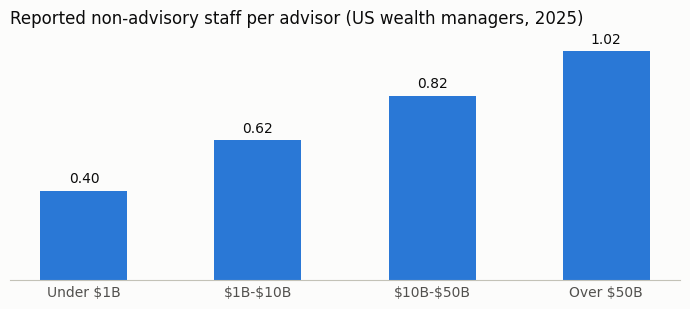

In [ ]:
CHART_BLUE, CHART_ORANGE = "#2a78d6", "#e8710a"
INK, MUTED, GRID, BASELINE, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams["text.parse_math"] = False  # show $ signs as plain text


def style_axis(ax, title, title_gap=12):
    """Apply one quiet chart style to every figure."""
    ax.set_facecolor(SURFACE)
    ax.figure.set_facecolor(SURFACE)
    ax.set_title(title, loc="left", color=INK, fontsize=12, pad=title_gap)
    ax.tick_params(colors=MUTED, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)


def non_advisory_by_segment(df, year):
    """Median non-advisory staff per advisor by segment, for one year."""
    rows = df[(df["data_year"] == year) & df["use_in_advisor_rankings"]
              & df["is_wealth_manager"] & df["is_us_firm"]].copy()
    rows["segment"] = assign_segment(rows["aum_usd"].astype(float))
    staff = (rows["employees"] - rows["advisors"]).clip(lower=0) / rows["advisors"]
    return staff.astype(float).groupby(rows["segment"], observed=True).median()


non_advisory_table = pd.DataFrame({
    str(latest_year - 5): non_advisory_by_segment(firms, latest_year - 5),
    str(latest_year): non_advisory_by_segment(firms, latest_year),
})
display(non_advisory_table.style.format("{:.2f}"))

fig, ax = plt.subplots(figsize=(7, 3.2))
values = non_advisory_table[str(latest_year)]
bars = ax.bar(values.index.astype(str), values.values, width=0.5, color=CHART_BLUE)
ax.bar_label(bars, labels=[f"{v:.2f}" for v in values.values], padding=4, color=INK)
ax.set_yticks([])
ax.spines["bottom"].set_visible(True)
style_axis(ax, f"Reported non-advisory staff per advisor (US wealth managers, {latest_year})")
plt.tight_layout()
plt.show()

**Commentary**

- **Reported non-advisory staff rises with size:** the median is 0.40 per advisor under \$1B, rising to 1.02 over \$50B. Larger firms report more specialist staff outside advisory roles.
- **This isn't an admin measure.** The form excludes clerical workers, so this can't show who does the admin work. It's used only as a small signal in Track A.
- **Don't read much into the over-\$50B change from 2020.** That segment is small and its membership changed, so the rise from 0.59 to 1.02 may reflect firms moving in.

## Step 20: Geography

**Metrics:** firm count, median AUM, and AUM excluding firms above \$50B.

State shows where a firm's **headquarters** is, not where its clients are. A few giant firms can dominate a state's AUM, so firm count and median AUM are the main measures, and state totals exclude firms above \$50B.

**Median 5-year CAGR** covers firms in the 5-year window, while **net change in firms** shows the separate effect of firms joining and leaving since 2020.

,Firms,Median AUM,AUM excl. firms over $50B,Share of firms,Median 5-year CAGR,Firms in 2020,Net change in firms,Change %
state,,,,,,,,
CA,1008,$321.7M,$1.2T,12.4%,10.3%,894,+114,+13%
NY,712,$215.5M,$1.1T,8.8%,8.8%,686,+26,+4%
TX,568,$357.7M,$521.6B,7.0%,10.7%,448,+120,+27%
FL,556,$282.2M,$461.6B,6.8%,10.0%,413,+143,+35%
PA,367,$423.0M,$495.2B,4.5%,10.6%,331,+36,+11%
IL,331,$365.7M,$355.8B,4.1%,10.5%,276,+55,+20%
OH,308,$331.4M,$396.0B,3.8%,11.2%,252,+56,+22%
MA,289,$403.5M,$484.9B,3.6%,9.7%,276,+13,+5%
MI,242,$333.2M,$210.7B,3.0%,9.9%,193,+49,+25%


Fastest rise in firm count, among states with at least 50 firms in the start year:


,Firms in 2020,Firms,Net change in firms,Change %,Median 5-year CAGR
state,,,,,
UT,67,101,+34,+51%,12.2%
FL,413,556,+143,+35%,10.0%
NH,50,66,+16,+32%,8.3%
NC,154,203,+49,+32%,12.4%
SC,68,89,+21,+31%,10.5%


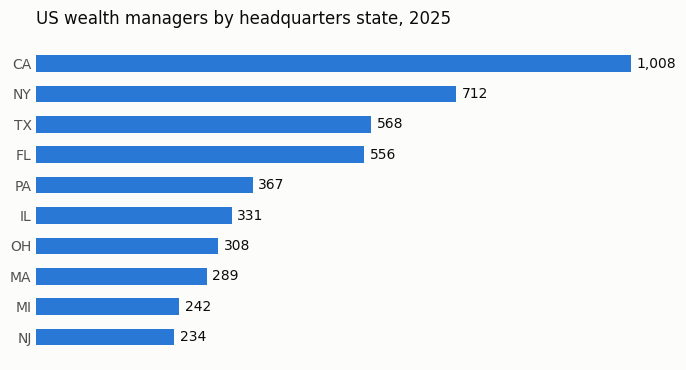

In [ ]:
def latest_firm_labels(df):
    """Take each firm's most recent state and wealth manager status."""
    latest_rows = df.sort_values("data_year").groupby("crd").last()
    return latest_rows[["state", "is_wealth_manager", "is_us_firm"]].rename(columns={
        "state": "last_state", "is_wealth_manager": "last_wealth", "is_us_firm": "last_us",
    })


def build_state_table(df, profile, growth_table, latest_year, first_year):
    """Summarise the US wealth manager market by headquarters state."""
    base = profile[profile["is_us_wealth_manager"]]
    excluding_giants = base[base["aum_usd"] <= 5e10]
    table = pd.DataFrame({
        "Firms": base.groupby("state").size(),
        "Median AUM": base.groupby("state")["aum_usd"].median().astype(float),
        "AUM excl. firms over $50B": excluding_giants.groupby("state")["aum_usd"].sum().astype(float),
    })
    table["Share of firms"] = table["Firms"] / table["Firms"].sum()

    in_target = growth_table[growth_table["is_wealth_manager"] & growth_table["is_us_firm"]]
    table["Median 5-year CAGR"] = in_target.groupby("state")["aum_cagr"].median()

    # Firms joining and leaving, using each firm's latest state throughout
    labels = latest_firm_labels(df)
    wealth_rows = df.merge(labels, left_on="crd", right_index=True)
    wealth_rows = wealth_rows[wealth_rows["last_wealth"] & wealth_rows["last_us"]
                              & wealth_rows["in_market_count"]]
    start = wealth_rows[wealth_rows["data_year"] == first_year].groupby("last_state").size()
    end = wealth_rows[wealth_rows["data_year"] == latest_year].groupby("last_state").size()
    table[f"Firms in {first_year}"] = start.reindex(table.index).fillna(0).astype(int)
    table["Net change in firms"] = end.reindex(table.index).fillna(0).astype(int) - table[f"Firms in {first_year}"]
    table["Change %"] = table["Net change in firms"] / table[f"Firms in {first_year}"].where(table[f"Firms in {first_year}"] > 0)
    return table.sort_values("Firms", ascending=False)


first_year = latest_year - 5
state_table = build_state_table(firms, profile, growth_tables[5], latest_year, first_year)
state_table.to_csv(OUTPUT_DIR / "state_summary.csv")

display(state_table.head(10).style.format({
    "Median AUM": money, "AUM excl. firms over $50B": money, "Share of firms": "{:.1%}",
    "Median 5-year CAGR": "{:.1%}", "Change %": "{:+.0%}", "Net change in firms": "{:+,.0f}",
}))
print("Fastest rise in firm count, among states with at least 50 firms in the start year:")
larger_states = state_table[state_table[f"Firms in {first_year}"] >= 50]
display(larger_states.sort_values("Change %", ascending=False).head(5)[
    [f"Firms in {first_year}", "Firms", "Net change in firms", "Change %", "Median 5-year CAGR"]
].style.format({"Change %": "{:+.0%}", "Net change in firms": "{:+,.0f}", "Median 5-year CAGR": "{:.1%}"}))

top_states = state_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(top_states.index, top_states["Firms"], height=0.55, color=CHART_BLUE)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in top_states["Firms"]], padding=4, color=INK)
ax.set_xticks([])
style_axis(ax, f"US wealth managers by headquarters state, {latest_year}")
ax.spines["bottom"].set_visible(False)
plt.tight_layout()
plt.show()

**Commentary**

- **The market is concentrated:** California (1,008 firms), New York (712), Texas (568) and Florida (556) hold 35% of US wealth managers.
- **Momentum sits in the South:** among the largest states, Florida rose 35% and Texas 27% from 2020, against 13% for California and 4% for New York. Utah rose fastest, at 51%, from a small base.
- **Location barely changes firm growth:** median 5-year growth is 8.8% to 11.2% across the top 10 states. Geography matters more for where to find firms than for predicting growth.
- **New York's median firm is smaller,** at \$215.5M against \$321.7M in California, so a high firm count there doesn't mean larger accounts.

## Step 21: Firms joining and leaving

**Metric:** the number of US wealth managers appearing in the SEC file for the first time, and the number disappearing, each year.

A joining firm may be new, or an existing state-registered firm that grew large enough to register with the SEC, so this shows **new SEC-registered firms**, not necessarily new businesses. A leaving firm may have closed, been acquired or moved to state registration.

,Joined,Left,Net,Median joiner AUM
data_year,,,,
2021,660,288,372,$120.3M
2022,396,346,50,$118.3M
2023,595,336,259,$119.4M
2024,664,407,257,$122.6M
2025,641,357,284,$120.4M


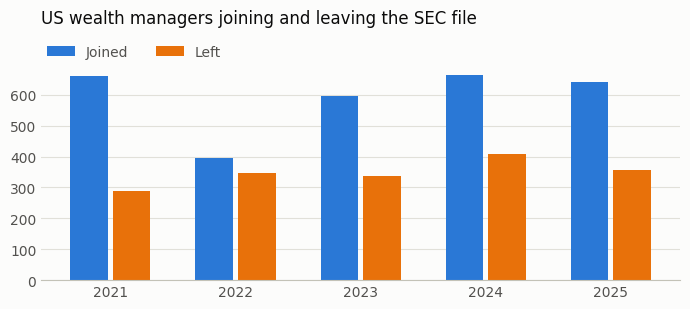

In [ ]:
def build_flow_table(df):
    """Count wealth managers joining and leaving the SEC file each year."""
    labels = latest_firm_labels(df)
    rows = df.merge(labels, left_on="crd", right_index=True)
    rows = rows[rows["last_wealth"] & rows["last_us"]]

    first_seen = rows.groupby("crd")["data_year"].min()
    last_seen = rows.groupby("crd")["data_year"].max()
    all_years = sorted(rows["data_year"].unique())

    joined = first_seen[first_seen > all_years[0]].value_counts().sort_index()
    left = (last_seen[last_seen < all_years[-1]] + 1).value_counts().sort_index()

    entrants = rows.merge(first_seen.rename("first_year"), left_on="crd", right_index=True)
    entrants = entrants[(entrants["data_year"] == entrants["first_year"])
                        & (entrants["first_year"] > all_years[0]) & (entrants["aum_usd"] > 0)]

    table = pd.DataFrame({"Joined": joined, "Left": left}).fillna(0).astype(int)
    table["Net"] = table["Joined"] - table["Left"]
    table["Median joiner AUM"] = entrants.groupby("data_year")["aum_usd"].median().astype(float)
    return table


flow_table = build_flow_table(firms)
display(flow_table.style.format({"Median joiner AUM": money}))
flow_table.to_csv(OUTPUT_DIR / "firms_joining_and_leaving.csv")

fig, ax = plt.subplots(figsize=(7, 3.2))
positions = np.arange(len(flow_table))
ax.bar(positions - 0.17, flow_table["Joined"], width=0.3, color=CHART_BLUE, label="Joined")
ax.bar(positions + 0.17, flow_table["Left"], width=0.3, color=CHART_ORANGE, label="Left")
ax.set_xticks(positions, flow_table.index)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2,
          labelcolor=MUTED, borderaxespad=0)
style_axis(ax, "US wealth managers joining and leaving the SEC file", title_gap=30)
plt.tight_layout()
plt.show()

**Commentary**

- **The market is growing on a net basis:** 2,956 US wealth managers joined from 2021 to 2025 and 1,734 left, a net gain of 1,222.
- **Joiners are remarkably consistent in size:** the median joiner has \$118M to \$123M, just above the roughly \$100M level at which advisers generally register with the SEC. This suggests many are existing state-registered firms moving up, not start-ups.
- **Why this matters for Nevis:** about 600 firms a year enter this market while they're growing and may be choosing systems.

## Step 22: Operational complexity

**Metrics:** offices beyond the main office, the share of firms with an affiliated adviser, and median advisors.

These show how hard a firm is to roll out to. They use the latest year only, because the affiliate column isn't in the two oldest files.

In [ ]:
wealth_managers = profile[profile["is_us_wealth_manager"]]
groups = wealth_managers.groupby("segment", observed=True)
complexity_table = pd.DataFrame({
    "Firms": groups.size(),
    "Median advisors": groups["advisors"].median().astype(float),
    "Median extra offices": groups["offices"].median().astype(float),
    "Share with an affiliated adviser": groups["ia_affiliates"].apply(lambda s: (s > 0).mean()),
})
display(complexity_table.style.format({
    "Median advisors": "{:,.0f}", "Median extra offices": "{:,.0f}",
    "Share with an affiliated adviser": "{:.0%}",
}))
complexity_table.to_csv(OUTPUT_DIR / "operational_complexity.csv")

,Firms,Median advisors,Median extra offices,Share with an affiliated adviser
segment,,,,
Under $1B,6511,3,0,8%
$1B-$10B,1415,13,1,22%
$10B-$50B,149,104,20,48%
Over $50B,61,885,131,79%


**Commentary**

- **Complexity rises steeply with size.** The median firm has no extra office under \$1B and 131 over \$50B. The share with an affiliated adviser rises from 8% to 79%.
- **Why this matters for Nevis:** smaller firms can likely adopt quickly with one decision-maker, while large firms need a multi-entity rollout. The two groups need different sales approaches.

## Step 23: Prospect tracks

Firms are split into two tracks, because they need different sales approaches.

**Track A: advisor-led pilot candidates.** Nevis targets with \$1B to \$10B of AUM and at least 5 advisors, a usable account history, and positive account growth in both the latest cycle and 3 years, with accounts growing faster than advisors in both. Firms whose accounts more than doubled in the latest cycle are left out, as that's more likely a one-off change. So are firms with an unconfirmed jump, a possible related transfer, possible acquisition-led growth or an advisor swing.

| Signal | Weight | Why it matters |
|---|---:|---|
| AUM growth above the segment median | 30% | A growing firm feels capacity pressure sooner |
| 3-year account gap | 30% | Accounts are outpacing advisors |
| Accounts per advisor | 25% | A direct measure of workload |
| Few non-advisory staff per advisor | 15% | Fewer reported specialists to share the work |

**Track B: enterprise and platform opportunities.** US wealth managers above \$10B, or platform-style firms. These are ranked by AUM, because they need a longer, multi-entity sale and a different product conversation.

**Workflow to test:** where accounts grew at least 25% in the latest cycle, the pressure is likely new work, so test onboarding. Otherwise it's a steady heavy book, so test meeting preparation. This is a hypothesis to raise in discovery, not a finding.

**Group review:** the table in the code holds public-source checks on specific firms, with evidence links. A shared parent means sales should coordinate, while a shared investor alone doesn't establish a shared buying team. Automatic hints use affiliate answers and shared websites. Firms with no review are marked `Not yet reviewed`.

`checked_on` shows how each fact was checked and when. Rows marked as an earlier review should be reopened before outreach.

**Websites:** the SEC file holds one web address per firm, chosen by the firm, so it isn't always the main site. Check it before using it for outreach.

In [ ]:
PROSPECT_REVIEW = pd.DataFrame(
    [
        (148107, None, 'https://kingsviewwealth.com/', 'Kingsview Partners received a growth investment from FTV Capital. The link between Kingsview Partners and this CRD still needs confirming, along with where buying authority sits.', 'https://ftvcapital.com/portfolio-item/kingsview-partners/', 'Page read 2026-11-03'),
        (143208, None, 'https://bipwealth.com/', 'Secured a strategic minority investment from Constellation Wealth Capital in February 2026. An investor link alone does not establish a shared buying team.', 'https://pulse2.com/bip-wealth-announces-strategic-investment-from-constellation-wealth-capital', 'Page read 2026-11-03'),
        (151501, None, 'https://c2privatewealth.com/', 'Firm brochure verifies the DBA and identity. Confirm procurement scope and whether rising accounts represent additional households.', 'https://c2privatewealth.com/wp-content/uploads/2025/03/C2PW-CRS-3.3.25.pdf', 'Earlier review, link not reopened'),
        (164081, None, 'https://axxcessplatform.com/', 'Identity confirmed from the SEC roster. The firm\'s site calls it "the enterprise TAMP for RIAs", and lists onboarding and transitions as a ten-week workflow. A deployment would be with platform operations, not advisors. Ownership is not verified.', 'https://axxcessplatform.com/advisor-and-tamp-solutions/', 'Firm site read 2026-11-03'),
        (170301, 'Ally Financial', 'https://www.ally.com/invest/', 'SEC identifies Ally Financial as parent and describes a robo-advice programme. Route to digital advice operations and confirm product fit.', 'https://www.sec.gov/files/litigation/admin/2026/ia-6954.pdf', 'Earlier review, link not reopened'),
        (153649, None, 'https://www.gerberkawasaki.com/', 'Company site verifies the advisory brand. Confirm operating workflow and buying ownership.', 'https://www.gerberkawasaki.com/about-us', 'Earlier review, link not reopened'),
        (311980, None, 'https://www.confluencefp.com/', 'Company announcement discloses a strategic investment from Constellation Wealth Capital. Keep separate from BIP pending buying-team evidence.', 'https://www.prnewswire.com/news-releases/confluence-financial-partners-announces-strategic-partnership-with-constellation-wealth-capital-302858481.html', 'Earlier review, link not reopened'),
        (111119, None, 'https://www.wealthcaregdx.com/', 'Sammons discloses Wealthcare within its Criterion holding company. Coordinate with other Criterion opportunities if present.', 'https://www.sammonsfinancialgroup.com/our-member-companies/criterion', 'Earlier review, link not reopened'),
        (140619, None, 'https://cardinalpointwealth.com/', 'Cardinal Point brochure identifies Focus as parent. Coordinate with any Focus opportunity including Focus Partners Wealth.', 'https://cardinalpointwealth.com/wp-content/uploads/2025/04/Cardinal-Point-Form-ADV-Part-2A-Firm-Brochure-March-2025.pdf', 'Earlier review, link not reopened'),
        (320878, None, 'https://www.daymarkwealth.com/', 'Received a minority investment from Constellation Wealth Capital in December 2025. Constellation has also invested in BIP and Confluence, but a shared investor does not establish a shared buying team.', 'https://www.businesswire.com/news/home/20251215525161/en/DayMark-Wealth-Partners-Receives-Minority-Investment-From-Constellation-Wealth-Capital', 'Page read 2026-11-03'),
        (322879, 'Ascentis Holdings', None, 'Ascentis Holdings combines Ascentis Wealth Management, Ascentis Asset Management and Ascentis Independent Advisors. Confirm where buying authority sits.', 'https://www.globenewswire.com/news-release/2026/01/21/3222559/0/en/ascentis-holdings-launches-bringing-three-established-businesses-under-one-platform.html', 'Page read 2026-11-03'),
        (288792, None, 'https://www.kingswoodus.com/', 'Historical: a 2022 announcement names Kingswood Group as the parent of Kingswood U.S. Check current ownership and buying team.', 'https://www.thewealthadvisor.com/article/kingswood-us-rias-consolidate-under-kingswood-wealth-advisors-brand', 'Page read 2026-11-03'),
        (311364, None, 'https://www.wealthplan.group/', 'WealthPlan Partners (CRD 305026) is a separately registered adviser with the same brand and city in the SEC roster. Confirm how the two relate before outreach.', 'https://adviserinfo.sec.gov/firm/summary/305026', 'SEC file and roster 2026-11-03'),
        (158282, None, 'https://www.advisoryalpha.com/', "The firm's site describes a platform for advisor partners, including help starting or enhancing an RIA. Confirm the operating model and ownership before treating it as an advisor-led pilot.", 'https://www.advisoryalpha.com/', 'Firm site text read 2026-11-03'),
        (313928, None, 'https://www.impactpartnershipwealth.com/', 'Form ADV Section 1.I lists this site, and its relationship summary misspells it as impactparnershipwealth.com. A 2021 release describes the firm as affiliated with The Impact Partnership, an insurance marketing organization, under the same president. Confirm current ownership.', 'https://prnewswire.com/news-releases/the-impact-partnership-llc-launches-impact-partnership-wealth-llc-partnered-with-market-guard-301321406.html', 'Filings and release read 2026-11-03'),
        (7691, 'Bank of America', None, 'A Merrill client agreement says MLPF&S and MAA are wholly-owned subsidiaries of Bank of America Corporation. Use one outreach owner across the group while buying authority is checked.', 'https://olui2.fs.ml.com/Publish/Content/application/pdf/GWMOL/summary-programs-services_backend.pdf', 'Page read 2026-11-03'),
        (142558, 'Bank of America', None, 'A Merrill client agreement says MLPF&S and MAA are wholly-owned subsidiaries of Bank of America Corporation. Procurement may still sit with a separate team.', 'https://olui2.fs.ml.com/Publish/Content/application/pdf/GWMOL/summary-programs-services_backend.pdf', 'Page read 2026-11-03'),
        (149777, 'Morgan Stanley', None, 'Parent of the group. Parametric is checked separately.', 'https://adviserinfo.sec.gov/firm/summary/149777', 'SEC file 2026-11-03'),
        (114310, 'Morgan Stanley', None, 'Form ADV Part 2A says Parametric is an indirect, wholly owned subsidiary of Morgan Stanley. Procurement may still sit with a separate team.', 'https://www.parametricportfolio.com/-/media/files/form-crs/form-adv-part-2a---ppa---11-27-2024.pdf', 'Page read 2026-11-03 (November 2024 brochure)'),
        (284430, None, None, 'SEC firm summary confirms multiple trading names under one CRD. Consolidate those brands in account records and verify the main site.', 'https://adviserinfo.sec.gov/firm/summary/284430', 'Earlier review, link not reopened'),
        (159289, None, None, 'Related group record outside the final shortlist. Use in the duplicate outreach check.', 'https://focus-financial.files.svdcdn.com/production/documents/Focus-Partners-Wealth-ADV-Part-2A-04.29.26.pdf', 'Earlier review, link not reopened'),
    ],
    columns=["crd", "confirmed_group", "verified_website", "review_note", "evidence_url", "checked_on"],
)

# Possible links that lack a current source. These trigger a review but set no outreach group.
POSSIBLE_GROUPS = {
    148107: "Kingsview Partners", 288792: "Kingswood Group", 159289: "Focus Financial Partners",
    140619: "Focus Financial Partners", 111119: "Sammons Financial Group",
}

SCORE_WEIGHTS = {
    "growth_score": 0.30, "account_gap_score": 0.30, "workload_score": 0.25, "low_staff_score": 0.15,
}


def score_pool(table, weights):
    """Score a pool of firms from 0 to 100 using percentile ranks."""
    table = table.copy()
    table["accounts_per_advisor"] = table["accounts_per_advisor"].astype(float)
    table["non_advisory_staff_per_advisor"] = table["non_advisory_staff_per_advisor"].astype(float)
    table["growth_score"] = table["versus_segment"].rank(pct=True)
    table["account_gap_score"] = table["account_gap"].rank(pct=True)
    table["workload_score"] = table["accounts_per_advisor"].rank(pct=True)
    table["low_staff_score"] = 1 - table["non_advisory_staff_per_advisor"].rank(pct=True)
    table["target_score"] = sum(table[name] * weight for name, weight in weights.items()) * 100
    return table.sort_values("target_score", ascending=False)


def build_track_a_pool(three_year, latest_cycle):
    """Select advisor-led pilot candidates."""
    recent_gap = latest_cycle["account_gap"].reindex(three_year.index)
    recent_growth = latest_cycle["account_cagr"].reindex(three_year.index)
    accounts_rising = (three_year["account_cagr"] > 0) & (recent_growth > 0)
    pool = three_year[
        three_year["is_nevis_target"]
        & three_year["segment"].astype(str).eq("$1B-$10B")
        & (three_year["end_advisors"] >= MIN_PILOT_ADVISORS)
        & (three_year["account_gap"] > 0) & (recent_gap > 0) & accounts_rising
        & (recent_growth <= MAX_RECENT_ACCOUNT_GROWTH)
        & three_year["growth_quality"].isin(["No jump flagged", "Supported jump"])
        & ~three_year["held_out_jump"] & ~three_year["advisor_swing"]
    ].copy()
    pool["recent_account_gap"] = recent_gap.reindex(pool.index)
    pool["recent_account_growth"] = recent_growth.reindex(pool.index)
    return pool


def add_group_checks(table, profile):
    """Add verified group facts and automatic hints."""
    table = table.copy()
    review = PROSPECT_REVIEW.set_index("crd")
    table["review_status"] = np.where(table.index.isin(review.index), "Reviewed", "Not yet reviewed")
    for column in ["confirmed_group", "verified_website", "review_note", "evidence_url", "checked_on"]:
        table[column] = review[column].reindex(table.index)
    table["website_to_use"] = table["verified_website"].fillna(table["website"]).fillna("")
    table["possible_group"] = table.index.map(POSSIBLE_GROUPS)
    table["group_status"] = np.select(
        [table["confirmed_group"].notna(), table["possible_group"].notna()],
        ["Confirmed", "Review only"], default="None found",
    )

    hosts = profile["website"].map(website_host)
    host_counts = hosts.value_counts()
    table["shared_website"] = hosts.reindex(table.index).map(host_counts).fillna(0) > 1
    table["affiliate_hint"] = (profile["has_adviser_affiliate"].reindex(table.index).eq("Y")
                               | (profile["ia_affiliates"].reindex(table.index).fillna(0) > 0))
    table["outreach_action"] = np.select(
        [table["confirmed_group"].notna(), table["review_status"].eq("Reviewed"),
         table["possible_group"].notna() | table["shared_website"] | table["affiliate_hint"]],
        ["Coordinate with the group before outreach", "Follow the review note",
         "Check affiliates and buying team"],
        default="Confirm buying team",
    )
    return table


track_a_pool = build_track_a_pool(staffing_tables[3], staffing_tables[1])
track_a = add_group_checks(score_pool(track_a_pool, SCORE_WEIGHTS), profile)

# First wave: one reason and one workflow to test for each firm
track_a["workflow_to_test"] = np.where(track_a["recent_account_growth"] >= 0.25,
                                       "Onboarding and CRM follow-up per new account",
                                       "Meeting preparation and follow-up per advisor")
track_a["why_now"] = [
    f"{load:,.0f} accounts per advisor; accounts {gap * 100:,.0f} pts ahead of advisors a year"
    for load, gap in zip(track_a["accounts_per_advisor"], track_a["account_gap"])
]

# Three separate questions: who the firm is, who it belongs to, and who can buy
AFFILIATIONS = {
    320878: "Verified: Constellation minority stake", 322879: "Verified: Ascentis Holdings",
    288792: "Historical: Kingswood Group (2022 source)",
    313928: "Historical: The Impact Partnership (2021 source)",
}
OPERATING_MODELS = {158282: "Partner platform, per its site", 164081: "Enterprise TAMP, per its site"}
track_a["identity"] = np.where(track_a["review_status"] == "Reviewed", "Checked", "Not yet")
track_a["affiliation"] = [AFFILIATIONS.get(crd, "Not verified") for crd in track_a.index]
track_a["buying_authority"] = "To confirm"
track_a["operating_model"] = [OPERATING_MODELS.get(crd, "To confirm") for crd in track_a.index]

top = track_a.head(10)
print(f"Track A pool: {len(track_a):,} firms, {track_a['advisors'].sum():,.0f} reported advisors")
print(f"Median advisors {track_a['advisors'].median():,.0f}, median extra offices {track_a['offices'].median():,.0f}")
print(f"Firms with at least 100 advisors: {(track_a['advisors'] >= 100).sum():,}")
print("First wave: the top 10 Track A firms")
show_table(pd.DataFrame({
    "Rank": range(1, len(top) + 1), "Firm": top["firm_name"], "State": top["state"],
    "AUM": top["aum_usd"].map(money),
    "Advisors, 3 years": top["start_advisors"].map("{:,.0f}".format) + " to " + top["end_advisors"].map("{:,.0f}".format),
    "Score": top["target_score"].map("{:.0f}".format),
    "Why now": top["why_now"], "Workflow to test": top["workflow_to_test"], "Website": top["website_to_use"],
    "Operating model": top["operating_model"], "Identity": top["identity"], "Affiliation": top["affiliation"],
    "Buying authority": top["buying_authority"],
}))

# The filings behind the proposed first deployment in Part D
example = firms[(firms["crd"] == 320878) & (firms["data_year"] >= latest_year - 3)]
print("DayMark Wealth Partners, as filed")
show_table(pd.DataFrame({
    "Year": example["data_year"], "AUM": example["aum_usd"].map(money),
    "Accounts": example["accounts"].map("{:,.0f}".format),
    "Advisors": example["advisors"].map("{:,.0f}".format),
    "Employees": example["employees"].map("{:,.0f}".format),
}))

us_wealth_managers = profile[profile["is_us_wealth_manager"]]
track_b = us_wealth_managers[(us_wealth_managers["aum_usd"] > 1e10)
                             | us_wealth_managers["is_platform_style"]]
track_b = add_group_checks(track_b.sort_values("aum_usd", ascending=False), profile)
track_b["accounts_per_advisor"] = track_b["accounts_per_advisor"].astype(float)
track_b["growth_quality"] = (staffing_tables[3]["growth_quality"].reindex(track_b.index)
                             .fillna("Not in the 3-year window"))

top = track_b.head(10)
print(f"Track B pool: {len(track_b):,} firms")
show_table(pd.DataFrame({
    "Rank": range(1, len(top) + 1), "Firm": top["firm_name"], "State": top["state"],
    "AUM": top["aum_usd"].map(money), "Advisors": top["advisors"].map("{:,.0f}".format),
    "Accounts per advisor": top["accounts_per_advisor"].map("{:,.0f}".format),
    "Extra offices": top["offices"].map("{:,.0f}".format),
    "Platform-style": top["is_platform_style"], "Group": top["confirmed_group"].fillna(""),
    "Growth quality": top["growth_quality"],
}))

# How much does Track A depend on the method?
base_top = set(track_a.head(25).index)
weight_tests = {
    "Equal weights": {name: 0.25 for name in SCORE_WEIGHTS},
    "Workload and account gap only": {"growth_score": 0, "account_gap_score": 0.5,
                                      "workload_score": 0.5, "low_staff_score": 0},
    "Without non-advisory staff": {"growth_score": 0.35, "account_gap_score": 0.35,
                                   "workload_score": 0.30, "low_staff_score": 0},
}
track_a_sensitivity = pd.DataFrame([
    {"Change": name,
     "Top 25 firms unchanged": len(base_top & set(score_pool(track_a_pool, weights).head(25).index))}
    for name, weights in weight_tests.items()
])
show_table(track_a_sensitivity)

# Group check across both tracks. Evidence triggers a review, and a confirmed group sets one owner.
COMMON_INVESTOR_FIRMS = [320878, 143208, 311980]  # all three have Constellation Wealth Capital as investor
prospects = pd.concat([track_a.assign(track="A"), track_b.assign(track="B")])
brand = prospects["firm_name"].str.split().str[0]
repeated_brand = brand.map(brand.value_counts()).gt(1) & brand.ne("THE")
prospects["group_review_trigger"] = (prospects["shared_website"] | prospects["affiliate_hint"]
                                     | repeated_brand | prospects.index.isin(COMMON_INVESTOR_FIRMS)
                                     | prospects["possible_group"].notna())
prospects["outreach_group"] = prospects["confirmed_group"].fillna(prospects["firm_name"])
for table in (track_a, track_b):
    table["group_review_trigger"] = prospects["group_review_trigger"].reindex(table.index)
    table["outreach_group"] = prospects["outreach_group"].reindex(table.index)

shared = prospects.groupby("confirmed_group")["firm_name"].agg(["count", list])
shared = shared[shared["count"] > 1]
print(f"Prospects with a group review trigger: {prospects['group_review_trigger'].sum():,} of {len(prospects):,}")
print("Confirmed groups with more than one prospect, so one outreach owner each:")
show_table(pd.DataFrame({"Group": shared.index, "Firms": shared["list"].map(" + ".join)}))

save_ranking(track_a.head(50), "prospects_track_a_pilot")
save_ranking(track_a[track_a["advisors"] >= 100], "prospects_track_a_100_plus_advisors")
save_ranking(track_b, "prospects_track_b_enterprise")

Track A pool: 402 firms, 15,755 reported advisors
Median advisors 15, median extra offices 2
Firms with at least 100 advisors: 38
First wave: the top 10 Track A firms


Rank,Firm,State,AUM,"Advisors, 3 years",Score,Why now,Workflow to test,Website,Operating model,Identity,Affiliation,Buying authority
1,"ADVISORY ALPHA, LLC",MI,$4.4B,58 to 61,90,400 accounts per advisor; accounts 19 pts ahead of advisors a year,Meeting preparation and follow-up per advisor,https://www.advisoryalpha.com/,"Partner platform, per its site",Checked,Not verified,To confirm
2,"AXXCESS WEALTH MANAGEMENT, LLC",CA,$8.9B,45 to 44,89,592 accounts per advisor; accounts 40 pts ahead of advisors a year,Meeting preparation and follow-up per advisor,https://axxcessplatform.com/,"Enterprise TAMP, per its site",Checked,Not verified,To confirm
3,"IMPACT PARTNERSHIP WEALTH, LLC",GA,$3.0B,33 to 89,84,180 accounts per advisor; accounts 60 pts ahead of advisors a year,Onboarding and CRM follow-up per new account,https://www.impactpartnershipwealth.com/,To confirm,Checked,Historical: The Impact Partnership (2021 source),To confirm
4,"DAYMARK WEALTH PARTNERS, LLC",OH,$5.0B,9 to 21,84,353 accounts per advisor; accounts 21 pts ahead of advisors a year,Meeting preparation and follow-up per advisor,https://www.daymarkwealth.com/,To confirm,Checked,Verified: Constellation minority stake,To confirm
5,"ASCENTIS INDEPENDENT ADVISORS, LLC",TX,$2.1B,21 to 39,84,191 accounts per advisor; accounts 25 pts ahead of advisors a year,Onboarding and CRM follow-up per new account,www.organpeakfinancial.com,To confirm,Checked,Verified: Ascentis Holdings,To confirm
6,"FOCUSED WEALTH MANAGEMENT, INC.",NY,$2.3B,12 to 8,83,717 accounts per advisor; accounts 56 pts ahead of advisors a year,Meeting preparation and follow-up per advisor,,To confirm,Not yet,Not verified,To confirm
7,CS PLANNING CORP,OR,$2.0B,45 to 49,83,191 accounts per advisor; accounts 45 pts ahead of advisors a year,Onboarding and CRM follow-up per new account,www.cultivant.com,To confirm,Not yet,Not verified,To confirm
8,"KINGSWOOD WEALTH ADVISORS, LLC",CA,$3.8B,78 to 76,82,161 accounts per advisor; accounts 66 pts ahead of advisors a year,Onboarding and CRM follow-up per new account,https://www.kingswoodus.com/,To confirm,Checked,Historical: Kingswood Group (2022 source),To confirm
9,WEALTHPLAN INVESTMENT MANAGEMENT LLC,NE,$2.2B,12 to 14,82,380 accounts per advisor; accounts 64 pts ahead of advisors a year,Onboarding and CRM follow-up per new account,https://www.wealthplan.group/,To confirm,Checked,Not verified,To confirm
10,"RED DOOR WEALTH MANAGEMENT, LLC",TN,$3.1B,8 to 10,80,447 accounts per advisor; accounts 20 pts ahead of advisors a year,Meeting preparation and follow-up per advisor,,To confirm,Not yet,Not verified,To confirm


DayMark Wealth Partners, as filed


Year,AUM,Accounts,Advisors,Employees
2022,$907.8M,"2,043",9,20
2023,$2.5B,"4,219",16,26
2024,$3.9B,"6,073",19,31
2025,$5.0B,"7,405",21,40


Track B pool: 308 firms


Rank,Firm,State,AUM,Advisors,Accounts per advisor,Extra offices,Platform-style,Group,Growth quality
1,MORGAN STANLEY,NY,$2.0T,"13,000",208,627,False,Morgan Stanley,No jump flagged
2,"MERRILL LYNCH, PIERCE, FENNER & SMITH INCORPORATED",NY,$1.8T,"25,721",126,"3,910",False,Bank of America,No jump flagged
3,EDWARD JONES,MO,$1.0T,"20,304",277,"15,120",False,,No jump flagged
4,MANAGED ACCOUNT ADVISORS LLC,NJ,$995.0B,25,"88,819",0,True,Bank of America,No jump flagged
5,UBS FINANCIAL SERVICES INC.,NJ,$915.8B,"9,149",125,369,False,,No jump flagged
6,LPL FINANCIAL LLC,SC,$819.1B,"36,280",79,"20,864",False,,No jump flagged
7,PARAMETRIC PORTFOLIO ASSOCIATES,WA,$684.8B,213,"1,128",5,True,Morgan Stanley,No jump flagged
8,WELLS FARGO ADVISORS,MO,$671.4B,"7,957",166,"5,038",False,,No jump flagged
9,"AMERIPRISE FINANCIAL SERVICES, LLC",MN,$660.5B,"12,681",191,158,False,,No jump flagged
10,ENVESTNET PMC,PA,$614.9B,178,"12,592",1,True,,No jump flagged


Change,Top 25 firms unchanged
Equal weights,19
Workload and account gap only,10
Without non-advisory staff,19


Prospects with a group review trigger: 334 of 710
Confirmed groups with more than one prospect, so one outreach owner each:


Group,Firms
Bank of America,"MERRILL LYNCH, PIERCE, FENNER & SMITH INCORPORATED + MANAGED ACCOUNT ADVISORS LLC"
Morgan Stanley,MORGAN STANLEY + PARAMETRIC PORTFOLIO ASSOCIATES


**Commentary**

- **Track A has 402 firms,** and the top 50 are saved to `prospects_track_a_pilot.csv`. It leads with Advisory Alpha (\$4.4B, 400 accounts per advisor) and Axxcess Wealth Management (\$8.9B, 592).
- **The top two aren't straightforward advisor-led pilots.** Advisory Alpha's site describes a platform for advisor partners, including help starting or enhancing an RIA. Axxcess's site calls it "the enterprise TAMP for RIAs". High accounts per advisor may therefore reflect the model rather than strain, and the buyer may differ. The platform-style rule doesn't catch them, because they sit below 1,000 accounts per advisor. Their ranks are unchanged, as these are review findings. Axxcess could still be a different kind of deployment, starting with its onboarding workflow and platform operations team.
- **The first wave separates four questions.** Operating model is sourced for 2 of the 10, and identity is checked for 7, including all of the top five. Affiliation is verified for DayMark and Ascentis, and historical for Impact Partnership and Kingswood. Buying authority is open for all ten.
- **Manual review stays proportionate.** Cleaning needs none. The first 10 Track A firms are in scope for manual review, or 2.5% of 402. Identity has been checked for seven, and buying authority is open for all ten.
- **Group checks work across both tracks.** Shared websites, affiliate counts, repeated brand names, common investors and possible groups trigger a review, covering 334 of 710 prospects. A trigger only means look closer. A group counts as confirmed only with a current source, which sets one outreach owner through `outreach_group`. Merrill and Managed Account Advisors share Bank of America, and Morgan Stanley and Parametric share Morgan Stanley, though procurement may still sit with separate teams. Kingswood, Kingsview, Focus and Sammons links lack a current source, so they're marked `Review only`. DayMark, BIP and Confluence share an investor, which doesn't establish a shared buying team.
- **Check fit with Nevis's deployment model.** [Nevis's deployment post](https://www.neviswealth.com/blog/deployment-strategy-at-nevis-the-proven-playbook-for-successful-ai-roll-outs-in-the-enterprise/) describes firms with hundreds or thousands of advisors, supported by a dedicated team. The median Track A firm has 15 advisors and 2 extra offices, and the largest first-wave firm has 89 advisors.
- **The 38 larger firms are a separate pool.** They have at least 100 reported advisors and are saved to `prospects_track_a_100_plus_advisors.csv`. None has been reviewed, and headcount alone leaves operating model and buying authority open.
- **The score sets the order of discovery.** 19 of the top 25 stay with equal weights and 19 without non-advisory staff, but using only workload and the account gap keeps 10. It isn't a firm ranking.
- **Track B has 308 firms.** The largest are brokerage-led groups such as Morgan Stanley and Merrill Lynch, alongside platforms such as Managed Account Advisors and Envestnet. Each needs its own product and rollout conversation.
- **Use these as starting points.** A high score shows signs of pressure, but it doesn't confirm a firm's current tools, budget or need.

## Step 24: Business form and country

These are short reference tables. Business form barely differs between segments, and country is too incomplete to support firm conclusions.

In [ ]:
form = wealth_managers.groupby("business_form").agg(
    Firms=("firm_name", "size"), median_aum=("aum_usd", "median")
).sort_values("Firms", ascending=False)
form["Share of firms"] = form["Firms"] / form["Firms"].sum()
form["Median AUM"] = form.pop("median_aum").astype(float)
print("US wealth managers by business form:")
display(form.style.format({"Median AUM": money, "Share of firms": "{:.1%}"}))

non_us = profile[~profile["is_us_firm"]]
countries = non_us["country"].fillna("Not in the file").value_counts()
print(f"Firms outside the US or with no address: {len(non_us):,}")
print(f"Of which have no country in the file: {non_us['country'].isna().sum():,}")
display(countries.head(8).to_frame("Firms"))

US wealth managers by business form:


,Firms,Share of firms,Median AUM
business_form,,,
Limited Liability Company,5541,68.1%,$326.6M
Corporation,2428,29.8%,$339.2M
Limited Partnership,67,0.8%,$1.3B
Other (specify),38,0.5%,$400.9M
Limited Liability Partnership,25,0.3%,$309.3M
Sole Proprietorship,23,0.3%,$141.1M
Partnership,14,0.2%,$267.6M


Firms outside the US or with no address: 2,110
Of which have no country in the file: 1,310


,Firms
country,
Not in the file,1310
United Kingdom,254
Canada,134
Hong Kong,69
Switzerland,55
Singapore,42
Australia,34
India,22


## Step 25: Sensitivity checks

Each ranking depends on assumptions, so these tests change one at a time and count how many of the original **top 20** stay in the top 20. This shows how much a reader should rely on each list.

In [ ]:
def overlap(base, other):
    """Count how many firms two lists share."""
    return len(set(base) & set(other))


def top_firms(table, metric, count=20):
    """Return the firms with the highest value of a metric."""
    return table.sort_values(metric, ascending=False).head(count).index


def rerun_growth(years_back, **test_options):
    """Rebuild a growth table with one test changed."""
    aum_ok = check_growth_window(firms, years_back, **test_options)[0]
    alternative = pd.DataFrame({"crd": aum_ok.index, f"eligible_aum_{years_back}y": aum_ok.values})
    return build_growth_table(firms, alternative, years_back, latest_year)


def only_targets(table):
    """Keep Nevis targets."""
    return table[table["is_nevis_target"]]


def published(table):
    """Apply the hold-out used in the published rankings."""
    return table[~table["held_out_jump"]]


target_growth = published(only_targets(growth_tables[3]))
five_year_targets = published(only_targets(growth_tables[5]))
base_growth = top_firms(target_growth, "aum_cagr")
base_five_year = top_firms(five_year_targets, "aum_cagr")
base_capacity = top_firms(capacity_targets, "aum_per_advisor")

looser_floor = published(only_targets(rerun_growth(3, min_start_aum=25_000_000)))
higher_floor = published(only_targets(rerun_growth(3, min_start_aum=200_000_000)))
endpoints_three = published(only_targets(rerun_growth(3, require_every_year=False)))
endpoints_five = published(only_targets(rerun_growth(5, require_every_year=False)))
with_unconfirmed = only_targets(growth_tables[3])
with_declines = profile[profile["use_in_advisor_rankings"] & profile["is_nevis_target"]
                        & (profile["advisors"] >= MIN_START_ADVISORS)]
no_related = target_growth[target_growth["growth_quality"] != "Possible related transfer"]
only_no_flag = target_growth[target_growth["growth_quality"] == "No jump flagged"]
five_advisors = capacity_targets[capacity_targets["advisors"] >= 5]
with_platforms = capacity[capacity["is_us_wealth_manager"]]

results = [
    ("Q1, 3 years", "Start AUM of at least $25M, not $100M", overlap(base_growth, top_firms(looser_floor, "aum_cagr")), len(looser_floor)),
    ("Q1, 3 years", "Start AUM of at least $200M, not $100M", overlap(base_growth, top_firms(higher_floor, "aum_cagr")), len(higher_floor)),
    ("Q1, 3 years", "Check start and end years only", overlap(base_growth, top_firms(endpoints_three, "aum_cagr")), len(endpoints_three)),
    ("Q1, 5 years", "Check start and end years only", overlap(base_five_year, top_firms(endpoints_five, "aum_cagr")), len(endpoints_five)),
    ("Q1, 3 years", "Add unconfirmed jumps back (starts before the hold-out)", overlap(base_growth, top_firms(with_unconfirmed, "aum_cagr")), len(with_unconfirmed)),
    ("Q1, 3 years", "Remove possible related transfers", overlap(base_growth, top_firms(no_related, "aum_cagr")), len(no_related)),
    ("Q1, 3 years", "Keep firms with no jump flagged", overlap(base_growth, top_firms(only_no_flag, "aum_cagr")), len(only_no_flag)),
    ("Q2, capacity", "At least 5 advisors, not 3", overlap(base_capacity, top_firms(five_advisors, "aum_per_advisor")), len(five_advisors)),
    ("Q2, capacity", "Add large advisor declines back (starts before the hold-out)", overlap(base_capacity, top_firms(with_declines, "aum_per_advisor")), len(with_declines)),
    ("Q2, capacity", "Keep platform-style firms", overlap(base_capacity, top_firms(with_platforms, "aum_per_advisor")), len(with_platforms)),
]
sensitivity_table = pd.DataFrame(results, columns=["Ranking", "What changed", "Pooled top 20 firms kept", "Firms in the test"])
show_table(sensitivity_table)
sensitivity_table.to_csv(OUTPUT_DIR / "sensitivity_checks.csv", index=False)

Ranking,What changed,Pooled top 20 firms kept,Firms in the test
"Q1, 3 years","Start AUM of at least $25M, not $100M",18,4919
"Q1, 3 years","Start AUM of at least $200M, not $100M",8,3125
"Q1, 3 years",Check start and end years only,20,4676
"Q1, 5 years",Check start and end years only,20,4042
"Q1, 3 years",Add unconfirmed jumps back (starts before the hold-out),20,4676
"Q1, 3 years",Remove possible related transfers,19,4637
"Q1, 3 years",Keep firms with no jump flagged,2,4597
"Q2, capacity","At least 5 advisors, not 3",12,3138
"Q2, capacity",Add large advisor declines back (starts before the hold-out),20,4957
"Q2, capacity",Keep platform-style firms,3,5861


**Commentary**

- **These counts compare one pooled top 20 for each test, not each segment's ranking.** They don't show that every segment's list is stable.
- **Every-year reporting doesn't change the pooled lists:** checking only the start and end years keeps all 20 firms in both the 3- and 5-year lists.
- **Lowering the AUM floor changes little in the pooled list:** \$25M keeps 18 of 20, while \$200M keeps 8, because many fast growers started small.
- **Growth rankings depend heavily on jumps:** keeping only firms with no jump flagged leaves 2 of 20, so this list shows firms going through major change.
- **The baseline is the published ranking.** Two tests deliberately start before the hold-outs, and are labelled. Adding unconfirmed jumps back keeps 20 of 20, and adding large advisor declines back to the target view of Q2 also keeps 20.
- **Possible transfers aren't driving the top 20:** removing them keeps 19.
- **Platform labels matter for Q2:** including platform-style firms keeps only 3 of 20, and raising the advisor minimum keeps 12.
- **What this means:** these tests compare pooled lists, so they don't show how stable each segment is. Exact firm rankings are sensitive to definitions, and rankings are best used to identify a group of firms rather than to compare individual positions.

# Part D: Conclusions for Nevis

## What the data says

1. **The reachable market is much smaller than the headline.** Of 17,263 RIAs, 6,579 pass the target screen. That shows fit, and buying authority and demand still need checking.
2. **It's a long tail with a concentrated top.** 80% of targets are under \$1B, while the 163 above \$10B carry far more AUM per firm.
3. **The workload measure changes the result.** On the same 4,155 US wealth managers, accounts outgrew advisors at about two in three, against nine in ten on AUM. The analysis doesn't measure how much of that difference comes from markets.
4. **Consolidation may shape the top of the market.** Three of the four three-year segment leaders show possible acquisition-led growth, so these firms may need to be treated as group sales.
5. **The market keeps refilling.** About 600 wealth managers join the SEC file each year, typically just above \$100M.

## Suggested priorities

| Priority | Group | Firms | Why |
|---|---|---:|---|
| **1** | Track A pilot candidates | 402, from 1,170 targets at \$1B-\$10B | Accounts are rising and outgrowing advisors, and the firms are large enough to invest. The median firm has 2 extra offices |
| **2** | Track B enterprise and platform firms | 308 | Very high value, but a longer multi-entity sale and a different product conversation |
| **3** | Fast-growing firms under \$1B | Part of 5,246 | The largest group, but smaller budgets, so best reached by a simpler offer |

**Geography:** start where firms are concentrated (California, New York, Texas and Florida), and watch Florida and Texas, where firm numbers are rising fastest.

## Proposed first deployment: DayMark

This is a proposal. The filings only establish the starting signal, and DayMark's operating model still needs confirming.

**The signal:** Step 23 shows the filings. Over 3 years, reported accounts rose from 2,043 to 7,405 while advisors rose from 9 to 21. Over the latest cycle, accounts rose from 6,073 to 7,405 and advisors from 19 to 21. No increase met the jump rule.

1. **Ask first:** is this a client-facing advisor model, and did higher account volumes mean more meeting preparation and follow-up?
2. **Start small:** if the work did rise, choose one team and one workflow for the first cohort.
3. **Agree a baseline:** set it with operations and compliance before launch.
4. **Track three things:** time per workflow, weekly usage, and rework or compliance exceptions.
5. **Then decide:** expand to more teams and offices when usage is sustained, workflow time improves, and rework or exceptions stay within agreed limits.

This follows the path in [Nevis's deployment post](https://www.neviswealth.com/blog/deployment-strategy-at-nevis-the-proven-playbook-for-successful-ai-roll-outs-in-the-enterprise/), from a first cohort to wider rollout as results come in. That post describes enterprise customers, and DayMark reports 21 advisors, so the deployment would need scaling down.

## What I'd do next

- **Finish the group checks:** review the three remaining top-10 firms, confirm operating models and ownership, and reopen the rows marked as earlier reviews.
- **Test fit by firm size:** ask the Nevis team how far down the market its deployment model works, and investigate the 38 larger Track A firms as a separate pool.
- **Test the workload theory:** ask pilot firms whether rising accounts mean more households, or more accounts per household.
- **Separate organic growth:** use Form ADV Part 2 brochures and press releases to identify acquisitions.
- **Add group structures:** link related entities, so consolidators are measured as one customer.
- **Compare with Nevis's customers:** test which of these signals actually predicts a win, then reweight the score.

# Part E: Outputs

## Step 26: Save the outputs

The core tables are saved to the `outputs` folder, alongside the ranking files from Parts C and D:

| File | Contents |
|---|---|
| `ria_firm_year_clean.csv` | The analysis-ready table, with one row per firm per year |
| `data_cleaning_rules.csv` | The rule book, with the number of rows each rule catches |
| `excluded_rows.csv` | Every excluded row, with the reasons |
| `firm_growth_eligibility.csv` | Which firms can enter each window, and the test that removed the others |
| `source_manifest.csv` | Each source file, with its size and SHA-256 hash |
| `name_moves.csv`, `possible_transfers.csv` | Transfers between firms found in Step 9 |

In [ ]:
FINAL_COLUMNS = [
    # Requested in the brief
    "sec_number", "firm_name", "website", "city", "state", "aum_usd", "clients",
    "clients_min", "clients_max", "client_count_basis", "aum_per_client",
    "aum_per_client_low", "aum_per_client_high", "employees", "advisors",
    "aum_per_advisor", "accounts", "accounts_per_advisor", "filing_date",
    "data_year",
    # Added to answer the questions properly
    "crd", "clients_per_advisor", "is_wealth_manager", "individual_aum_share",
    "is_us_firm", "offers_financial_planning", "manages_individual_portfolios",
    # Data quality
    "sec_status", "website_status", "client_minimum_applied", "is_stale_filing",
    "large_aum_jump", "aum_spike", "large_advisor_swing", "large_advisor_decline",
    "repeat_filing", "aum_unchanged",
    "material_aum_move", "jump_type", "structure_change", "client_aum_check",
    "row_status", "row_issues", "clients_usable", "advisors_usable", "accounts_usable",
    # How each row may be used
    "in_market_count", "use_in_rankings", "use_in_advisor_rankings",
    "source_file", "source_row",
]

clean_table = firms[FINAL_COLUMNS].sort_values(["crd", "data_year"]).reset_index(drop=True)
excluded_rows = clean_table[clean_table["row_status"] == "exclude"]
rule_counts = RULE_BOOK.merge(count_rows_per_rule(firms), on=["status", "rule"])

clean_table.to_csv(OUTPUT_DIR / "ria_firm_year_clean.csv", index=False)
rule_counts.to_csv(OUTPUT_DIR / "data_cleaning_rules.csv", index=False)
source_manifest.to_csv(OUTPUT_DIR / "source_manifest.csv", index=False)
name_moves.to_csv(OUTPUT_DIR / "name_moves.csv", index=False)
pd.DataFrame(
    [{"window": window_name(years), "crd": crd, "related_firms": related}
     for years, found in possible_transfers.items() for crd, related in found.items()]
).to_csv(OUTPUT_DIR / "possible_transfers.csv", index=False)
growth_eligibility.to_csv(OUTPUT_DIR / "firm_growth_eligibility.csv", index=False)
excluded_rows.to_csv(OUTPUT_DIR / "excluded_rows.csv", index=False)

print(f"Clean table: {len(clean_table):,} rows and {clean_table.shape[1]} columns")
print(f"Excluded rows: {len(excluded_rows):,}")
print(f"Saved to: {OUTPUT_DIR}")
clean_table.head()

Clean table: 95,494 rows and 51 columns
Excluded rows: 407
Saved to: /content/drive/MyDrive/nevis_ria/outputs


,sec_number,firm_name,website,city,state,aum_usd,clients,clients_min,clients_max,client_count_basis,aum_per_client,aum_per_client_low,aum_per_client_high,employees,advisors,aum_per_advisor,accounts,accounts_per_advisor,filing_date,data_year,...,large_aum_jump,aum_spike,large_advisor_swing,large_advisor_decline,repeat_filing,aum_unchanged,material_aum_move,jump_type,structure_change,client_aum_check,row_status,row_issues,clients_usable,advisors_usable,accounts_usable,in_market_count,use_in_rankings,use_in_advisor_rankings,source_file,source_row
0,801-57874,"ALLEN & COMPANY OF FLORIDA, LLC",NaN,LAKELAND,FL,"1,366,197,795.00","2,801.00","2,801.00","2,801.00",reported,"487,753.59","487,753.59","487,753.59",65.00,32.00,"42,693,681.09","3,621.00",113.16,2021-04-30,2020,...,False,False,False,False,False,False,False,none,False,passed,ok,,True,True,True,True,True,True,Nov-21_SEC Registered Investment Adviser Report.csv,5949
1,801-57838,AMERICAN INVESTORS CO,www.americaninvestorsco.com,SAN RAMON,CA,"588,575,319.00",974.00,974.00,995.00,range,"604,286.78","591,532.98","604,286.78",41.00,41.00,"14,355,495.59","1,868.00",45.56,2021-06-28,2020,...,False,False,False,False,False,False,False,none,False,passed,valid_gap,client_minimum_applied,True,True,True,True,True,True,Nov-21_SEC Registered Investment Adviser Report.csv,3104
2,801-57838,AMERICAN INVESTORS CO,www.americaninvestorsco.com,SAN RAMON,CA,"598,152,492.00",981.00,981.00,"1,002.00",range,"609,737.50","596,958.57","609,737.50",39.00,39.00,"15,337,243.38","1,915.00",49.10,2022-06-28,2021,...,False,False,False,False,False,False,False,none,False,passed,valid_gap,client_minimum_applied,True,True,True,True,True,True,Nov-22_SEC Registered Investment Adviser Report.xlsx,4417
3,801-57838,AMERICAN INVESTORS CO,www.americaninvestorsco.com,SAN RAMON,CA,"511,001,949.00",983.00,983.00,"1,004.00",range,"519,839.22","508,966.08","519,839.22",37.00,37.00,"13,810,863.49","1,917.00",51.81,2023-10-16,2022,...,False,False,False,False,False,False,False,none,False,passed,valid_gap,client_minimum_applied,True,True,True,True,True,True,Nov-23_SEC Registered Investment Adviser Report.xlsx,2
4,801-57838,AMERICAN INVESTORS CO,www.americaninvestorsco.com,SAN RAMON,CA,"616,901,590.00",908.00,908.00,929.00,range,"679,407.04","664,049.07","679,407.04",32.00,32.00,"19,278,174.69","1,815.00",56.72,2024-06-26,2023,...,False,False,False,False,False,False,False,none,False,passed,valid_gap,client_minimum_applied,True,True,True,True,True,True,Nov-24_SEC Registered Investment Adviser Report.xlsx,2


In [ ]:
# The summary at the top is written text, so stop if it no longer matches the data
SUMMARY_FIGURES = {
    "Reported firms": (int((firms["data_year"] == latest_year).sum()), 17_263),
    "Firms passing the target screen": (int(profile["is_nevis_target"].sum()), 6_579),
    "Track A firms": (len(track_a), 402),
    "Track A advisors": (int(track_a["advisors"].sum()), 15_755),
    "Track B firms": (len(track_b), 308),
    "Excluded firm-years": (int((firms["row_status"] == "exclude").sum()), 407),
    "Firms held out of 3-year Q1": (int(growth_tables[3]["held_out_jump"].sum()), 20),
    "Firms with a gap in all three windows": (len(persistent), 3_975),
}
wrong = {name: pair for name, pair in SUMMARY_FIGURES.items() if pair[0] != pair[1]}
if wrong:
    raise RuntimeError(f"The written summary no longer matches the data: {wrong}")
print("The figures in the executive summary match the data.")

The figures in the executive summary match the data.


# Appendix: Full methodology

## A1. The data

**Source:** the SEC's monthly *Information About Registered Investment Advisers* reports, which contain a subset of Form ADV. Exempt reporting advisers are excluded, because they don't file Item 5, which holds AUM, staff and clients.

Five years of growth needs six snapshots, a start and an end. `data_year` is the year-end each file mostly reflects, because firms usually update AUM by the end of March. It's an approximation: the file doesn't state when each firm's AUM was measured.

| File | `data_year` | Firms | Format | Columns | Used for |
|---|---:|---:|---|---:|---|
| Nov 2021 | 2020 | 14,777 | CSV | 262 | Start of 5-year growth |
| Nov 2022 | 2021 | 15,423 | Excel | 262 | History |
| Nov 2023 | 2022 | 15,573 | Excel | 448 | Start of 3-year growth |
| Nov 2024 | 2023 | 15,974 | Excel | 448 | History |
| Dec 2025 | 2024 | 16,484 | CSV | 448 | Start of the latest cycle |
| Nov 2026 | 2025 | 17,263 | CSV | 448 | Latest year |

**Why December 2025?** The SEC's October and November 2025 reports contain no data because of the government shutdown, so December 2025 is the closest available file.

**Why "latest cycle" rather than "1 year"?** The December 2025 and November 2026 files are 11 months apart, but the median firm's filings in them are 12 months apart, because firms update annually. The change is therefore about one filing cycle. It's shown as observed growth and isn't annualised, as annualising would turn Clearbrook's 2,818% into 3,866%.

**Reading the files:** CSV and Excel store values differently, such as `630,665,806.00` and `630665806`, so every file is read as text and converted by one shared process. Loading stops if a file holds anything unexpected, and each file's SHA-256 hash and each row's source position are kept, so any figure can be traced back.

## A2. How each field is defined

| Field in the brief | SEC source | Definition |
|---|---|---|
| SEC# | `SEC#` | Reported as filed |
| Firm name | `Primary Business Name` | Legal name replaces placeholders such as "No Other Primary Business Name" |
| Website | `Website Address` | Tidied. Social links are replaced by a real site from another year where possible |
| City, State | `Main Office City`, `Main Office State` | Main office. A filled state marks a US firm |
| AUM | `5F(2)(c)` | Total regulatory assets under management |
| Number of clients | Sum of `5D(a)(1)` to `5D(n)(1)` | Sum of 14 client types, with blanks counted as zero. "Fewer than 5" with no count is a range of 1 to 4, a convention used here |
| Average AUM per client | Calculated | AUM / clients, with low and high values where clients are a range |
| Number of employees | `5A` | Excludes clerical workers, as the form instructs |
| Number of advisors | `5B(1)` | Employees performing investment advisory functions, including research |
| AUM per advisor | Calculated | AUM / advisors |
| Filing date / year | `Latest ADV Filing Date`, `data_year` | Latest filing, and the year-end the file mostly reflects |

**Firms are tracked by CRD number, not SEC number or name.** 124 firms changed SEC number, 1,536 changed name, and 117 rows in the latest file share a name with another row.

**Added fields**

| Field | Definition | Why it was added |
|---|---|---|
| `accounts`, `accounts_per_advisor` | `5F(2)(f)`, and accounts / advisors | New accounts usually add work, while AUM can rise with markets alone |
| `clients_min`, `clients_max`, `client_count_basis` | The client range, and whether the total is fully `reported`, uses `blanks_as_zero`, is a `range` or is `unknown` | In the latest file, 3,647 firms filled every client field, 9,855 left some blank, which is usual for types they don't serve, and 3,759 have a range |
| `is_wealth_manager` | At least 50% of AUM comes from individuals and high-net-worth clients | Raw AUM also includes institutions such as Vanguard, which aren't Nevis customers |
| `is_platform_style` | More than 1,000 clients or accounts per advisor | Separates software-led or turnkey platforms from advisor-led firms |
| `is_nevis_target` | A US wealth manager offering both financial planning and individual portfolio management, and not platform-style | The view closest to Nevis's customers |

## A3. How the data was cleaned

**Step 1: Format checks.** Each column has an allowed format, such as `Y`/`N` or a number, tested before any conversion. Values that can't convert are reported rather than silently becoming blank.

**Step 2: Is a blank or zero explained?** The form often gives the answer. A firm answering "no" to managing portfolios at Item 5.F.(1) should have \$0 AUM. A newly registered firm may not have started. A firm ticking "fewer than 5 clients" may leave the count blank.

**Step 3: Do the figures agree?** Related answers must reconcile. Client-type AUM matches total AUM for all 91,364 testable firm-years with AUM. The other 22 can't be tested, because every client field is blank, and that's recorded separately from a failure.

**Step 4: Could the figure be real?** Plausibility rules catch values that pass every other check. Vista Financial Advisors reports \$11.5T with one advisor, and some firms report AUM below \$1,000, which looks like a units error.

**Step 5: Classify the row.**

| Status | Rows | Meaning | Treatment |
|---|---:|---|---|
| `ok` | 68,672 | Passes every rule | Used everywhere |
| `valid_gap` | 24,980 | A blank or zero that the form explains | Used where the data exists |
| `limited` | 1,435 | One figure can't be used, such as zero advisors | Used for the other figures |
| `exclude` | 407 | Stale filing or unreliable AUM | Left out of the analysis, but still in the as-reported market count |

**Stale filing:** firms must update Form ADV within 90 days of their financial year-end. On-time filings can therefore sit up to about 15 months apart (12 months + 3 months), so an older filing has probably missed an update. Bernard L. Madoff Investment Securities shows why this matters. It still appears as "Approved" with \$17.1B from a 2008 filing, and it's excluded by this rule, not by name.

**Validation:** 19 automatic checks run on the final table. Four firms are compared with the source file, and three known problem cases are tested directly. All pass, and any failed check stops the run.

## A4. Which firms enter a growth calculation

A firm can't show reliable 5-year growth unless it was measured properly for all 5 years. Each window therefore has its own eligible firms, and these counts show who remains after each test.

| Test | Why | Latest cycle | 3 years | 5 years |
|---|---|---:|---:|---:|
| Usable in the latest year | The end point must be reliable | 16,505 | 16,505 | 16,505 |
| Reported in every year | A missing year breaks the history | 15,267 | 12,902 | 11,065 |
| Usable in every year | A faulty middle year undermines the trend | 15,038 | 12,647 | 10,841 |
| Start year isn't a new registration | First-year AUM can be partial | 15,006 | 12,630 | 10,822 |
| No AUM spike in the start year | A one-year error distorts the base | 14,990 | 12,621 | 10,822 |
| No name move between firms | The AUM moved rather than grew | 14,987 | 12,617 | 10,818 |
| Latest filing is new | The same filing date means no new data | 14,975 | 12,617 | 10,818 |
| Start AUM of at least \$100M | Tiny bases create huge percentages | **14,029** | **11,746** | **10,177** |
| *Q5:* advisor count usable every year | Advisor growth needs a valid count | 13,954 | 11,655 | 10,075 |
| *Q5:* at least 3 advisors at the start and end | Very small teams create extreme gaps | **10,789** | **9,128** | **7,903** |

**What separates an outlier from growth?** Mainly whether the increase lasts, and whether anything else moved.

- **Spike:** a year more than 3x above or below both neighbouring years, which suggests an error. It can't be a growth starting point.
- **Jump:** AUM rising over 3x and at least \$100M in one year. Most jumps persist, so they stay in and are labelled.

**Is the growth real?** A firm's AUM can rise because assets moved between related entities. PineBridge rose from \$1.17B to \$76.73B because its name, and the assets, moved from another CRD. Three tests address this, and they're explained in Step 9.

| Growth quality label | Meaning |
|---|---|
| `No jump flagged` | No increase met the jump rule |
| `Supported jump` | A jump, with clients, accounts, advisors or employees up at least 1.5x, or explained by fund assets |
| `Unconfirmed jump` | A jump where nothing else moved |
| `Possible related transfer` | A firm with the same brand or website shrank at the same time |
| `Possible acquisition-led growth` | AUM and advisors both rose at least 3x from a positive advisor count, with at least \$1B of new AUM |

**Hold-out:** any firm with an unconfirmed jump in the window is held out of the rankings and listed separately. The hold-out is its own flag, because a firm can carry another label at the same time.

## A5. How each question is answered

| Question | Metric | Formula | Who's included |
|---|---|---|---|
| **Market segments** | Number of firms | Count by latest reported AUM | All firms, then a separate usable view |
| **Q1: Fastest growing** | AUM growth a year, and dollar change | `(end AUM / start AUM) ^ (1 / years) - 1` | Firms passing the window tests |
| **Q2: Capacity-strained** | AUM per advisor, latest year | `AUM / advisors` | At least 3 usable advisors, and no large reported advisor decline in the latest year |
| **Q5: Under-staffed** | AUM gap, with the account gap beside it | `AUM growth - advisor growth`, and `account growth - advisor growth` | Window tests, rising AUM, positive gap, no large reported advisor decline, no unconfirmed jump. Shrinking teams are shown separately |

**Why compare with the segment median?** Rising markets lift nearly every firm. Median growth is similar across all four segments, so a firm's distance from its segment median is a better sign of its own performance.

**Why add the account gap?** AUM can rise with markets without adding work. For the same 4,155 US wealth managers over 3 years, median AUM grew 16.5% a year, accounts 5.8%, clients 4.3% and advisors 0.0%. The AUM gap answers the brief, but it may overstate pressure on advisors if used alone. The analysis doesn't measure how much of the difference comes from markets.

**Why two views?** "All RIAs" directly answers the brief, while "Nevis targets" removes institutions and platforms that would otherwise dominate the rankings.

**Why an audit table?** Step 16 shows who would lead each segment with no screening, and which test removed them, so nothing disappears without explanation.

## A6. Key assumptions

All are set in Step 1, so each can be changed in one place. Step 25 tests how much the main ones affect the rankings.

| Assumption | Value | Reason |
|---|---|---|
| Stale filing | 15 months | Longest on-time gap between annual updates |
| Wealth manager | 50% of AUM from individuals and high-net-worth clients | A simple majority of the firm's business |
| "Fewer than 5" client count | 1 to 4, with 1 used as the point value | A convention, not a reported figure. Counts are never overstated, and the range stays visible |
| Minimum start AUM | \$100M | Removes percentages created by tiny bases, at the cost of leaving out smaller growers |
| Minimum advisors | 3, at both endpoints for Q5 | Removes extreme results from one- and two-person firms |
| Large reported advisor decline | A fall of at least 50% in a year | Vanguard Group went from 330 to 19. A fall this size can be real at a small firm, so these firms are held out, not called errors |
| Every-year reporting | Required | Keeps comparisons consistent. It doesn't change the pooled top 20 lists tested (Step 25) |
| AUM spike | 3x against both neighbours | Separates one-year reversals from lasting moves |
| Jump label | 3x and \$100M in a year | Marks growth that needs a closer look |
| Supporting rise | 1.5x in clients, accounts, advisors or employees | Evidence that the business really changed |
| Platform-style | Over 1,000 clients or accounts per advisor | A proxy for software-led firms, so labelled rather than removed from the data |
| Track A score weights | 30%, 30%, 25%, 15% | A judgement call, tested with other weights |

## A7. Limitations

- **Self-reported data:** Form ADV is filed by the firms themselves. These checks show that the data is consistent, not that it's true.
- **SEC-registered firms only:** smaller state-registered advisers aren't in this data, so the under-\$1B count understates that market.
- **Survivorship:** growth covers surviving firms only. Of the firms in the 5-year starting file, 3,414 have left, holding \$8.4T at the start, and 1,685 of them were wealth managers. Some will have been acquired, so their AUM may reappear inside a growing firm.
- **Acquisitions can't be fully separated from organic growth:** the labels are signals, not proof. Fast hiring can look like an acquisition, and a transfer can go undetected.
- **AUM dates:** the file doesn't show when each AUM figure was measured, and a filing date may be an amendment. Window lengths are therefore approximate.
- **Latest-year spikes can't be detected:** this needs a following year, so the jump label is the safeguard.
- **Advisors:** Item 5.B.(1) includes research staff, so "advisors" isn't only client-facing advisors.
- **Accounts:** one household can hold several accounts, so a rise in accounts doesn't always mean more households.
- **Non-advisory staff:** Item 5.A excludes clerical workers, so this doesn't measure admin capacity.
- **Group structures:** each legal entity files separately, so large groups can look smaller than they are. Vanguard appears to report some assets in more than one entity in 2025, which is why total market AUM isn't used as a trend.
- **Websites:** the file holds one address per firm, chosen by the firm. Beacon Pointe, the example in the brief, lists only a social page in every year, so its website stays blank.
- **Older files:** the November 2021 and November 2022 files lack 4A, 4B and the affiliate count, which limits early succession and affiliation checks. Affiliate data is used for the latest year only, and structure changes are only compared where both years have the data.
- **Location:** state is the headquarters, not where clients are. Country is blank for 1,310 of the 2,110 usable firms with no US state.

## A8. How AI was used

This analysis was built with Claude Opus 5.5, to move quickly while keeping the checks visible.

| Area | AI's role | My role |
|---|---|---|
| **Data understanding** | Mapped brief fields to Form ADV items and profiled every column | Confirmed the right data source and chose the snapshots |
| **Code** | Drafted and tested the notebook | Reviewed the logic, and asked for changes where the approach was unclear |
| **Data quality** | Measured blanks, formats and outliers, then proposed rules | Challenged the assumptions, including the 15-month rule, which was then checked against SEC instructions |
| **Methodology** | Proposed definitions and tests | Added requirements, including consistent reporting across each window, automatic rather than manual review, and the extra analyses |
| **Comparison** | Tested each difference between two analyses on the source files | Ran a second, separate analysis, and decided what to bring across |

**Worked example: PineBridge**

1. **First result:** the first build ranked PineBridge first in the over-\$50B segment, with AUM up from \$1.17B to \$76.73B, and labelled it a supported jump.
2. **Source check:** a second build disagreed, so both were checked against the SEC files. The name, and the assets, had moved from another CRD.
3. **Rule:** a name-move test now removes firms whose name moved between CRDs.
4. **Test:** Step 16's audit table shows PineBridge as the unscreened leader, and names the test that removed it.

**Other errors caught or rejected**

- **A wrong count:** AI stated that 6,839 firms gave no client number. Recounting from the data gave 3,759, and the figure now comes from code.
- **An unchecked value:** AI marked Vista Financial Advisors as `ok` at \$11.5T with one advisor. It passed the format checks, so a plausibility rule was added.
- **An overreach:** AI concluded that admin work falls on advisors at firms with few non-advisory staff. The form excludes clerical workers, so the data can't show this, and the claim was removed.
- **A logic bug:** an independent review found that the acquisition label could overwrite `Unconfirmed jump`, so Gallagher Fiduciary stayed in a published ranking. The hold-out is now a separate flag with a regression check.
- **A missed test:** AI's first version didn't require firms to report in every year of a window. I asked whether they did, and that test now sits in Step 11.

**How accuracy was protected:**

- **Two independent builds:** a second analysis reproduced the same market counts and identified PineBridge, a false growth lead that the first version had ranked first. Each difference was tested on the data before either approach was adopted.
- **Real data over simulated data:** running on the real files exposed errors that testing on simulated data had missed, including a malformed web address and an \$11.5T AUM value. Rules were added for each.
- **Repeatable checks:** the market table reconciles to the source file, and 19 automatic checks plus source comparisons run every time.
- **Visible assumptions:** they're stated in this Appendix and tested in Step 25, rather than left inside the code.

## A9. Pricing sensitivity

This table shows hypothetical annual value at assumed prices and full paid coverage. It isn't a forecast, and it assumes one paid licence for every reported advisor across every firm in the pool. I don't have Nevis's prices or commercial terms, and Nevis's [deployment post](https://www.neviswealth.com/blog/deployment-strategy-at-nevis-the-proven-playbook-for-successful-ai-roll-outs-in-the-enterprise/) describes phased adoption, so a signed firm wouldn't start at full coverage. The low case sits within [published AI notetaker prices](https://www.investmentnews.com/advisor-tech/is-50-the-new-120-price-compression-comes-to-ai-notetakers/264773) of about \$50 to \$184 a month, and the higher cases assume a broader platform earns more per licence.

In [ ]:
# Assumed annual price per paid licence. These are illustrations, not Nevis prices.
LICENCE_PRICES = {"At $1,200": 1_200, "At $3,600": 3_600, "At $6,000": 6_000}

pools = {
    "Track A pilot candidates": track_a,
    "All targets at $1B-$10B": profile[profile["is_nevis_target"]
                                       & profile["segment"].astype(str).eq("$1B-$10B")],
    "All Nevis targets": profile[profile["is_nevis_target"]],
}
sizing = pd.DataFrame([
    {"Pool": name, "Firms": len(pool), "Advisors": float(pool["advisors"].sum()),
     **{label: float(pool["advisors"].sum()) * price for label, price in LICENCE_PRICES.items()}}
    for name, pool in pools.items()
])
show_table(sizing.assign(
    Firms=sizing["Firms"].map("{:,.0f}".format), Advisors=sizing["Advisors"].map("{:,.0f}".format),
    **{label: sizing[label].map(money) for label in LICENCE_PRICES},
))
sizing.to_csv(OUTPUT_DIR / "pricing_sensitivity_illustrative.csv", index=False)

Pool,Firms,Advisors,"At $1,200","At $3,600","At $6,000"
Track A pilot candidates,402,"15,755",$18.9M,$56.7M,$94.5M
All targets at $1B-$10B,"1,170","37,560",$45.1M,$135.2M,$225.4M
All Nevis targets,"6,579","298,577",$358.3M,$1.1B,$1.8B
